# Entrega 2 — Bebidas del Maipo · Equipo 8

Ejecutar todo desde una sesión nueva. Se calculan calidad, pronóstico y traspaso antes de resolver un único modelo táctico. Los archivos de Entrega 1 en GitHub no se modifican. Datos oficiales fijados al commit indicado en la configuración.

**Alcance y decisiones de modelado.** El caso no entrega existencias iniciales de jarabe ni tarifa de horas extra L1. La base es un escenario **condicionado a jarabe preparado antes del horizonte**, calculado y exportado por familia; no es un dato observado. Se muestra también el escenario de jarabe inicial cero, y su eventual infactibilidad. L1 no usa horas extra en la base; la tarifa L2 se usa solo en una sensibilidad imputada.

El inventario físico y el atraso de un SKU no pueden coexistir. El stock de seguridad `z × sigma_h` es una meta: el déficit se exporta y penaliza por separado con el costo de atraso como **proxy**, con sensibilidad 0,5× y 2×. No se afirma cumplimiento del nivel de servicio objetivo cuando hay déficit. Se ejecuta además la variante con seguridad estricta; si es infactible se informa sin fabricar un plan. La reserva terminal y la producción mínima de semana 12 son restricciones obligatorias.

Las preparaciones de envasado usan promedio entrante por familia; mezcla cobra 1,2 h por familia activa (incluida la primera, aproximación conservadora). No se resuelve aquí el orden intrase semanal. El puente congela cantidades, líneas y horas supuestas para contrastarlas en la entrega final. La cartera de semana 12 se cubre con producción vendible mínima, conforme al §7.1 del enunciado; los plazos por día y hora corresponden al secuenciamiento.

La protección terminal CIT/FUN equivale a una semana al máximo de las cuatro últimas semanas del horizonte más seguridad; es una política explícita, no un pronóstico de enero. El jarabe almacenado no tiene cota ni costo informado: se presentan sensibilidades sin acopio y con costo imputado.

HiGHS informa solución, cota, brecha y tiempo. Un límite de tiempo no certifica optimalidad. Los costos incluyen una penalización de planificación por déficit de seguridad, separada del costo operativo. La regla lote por lote puede ser infactible; la referencia reparada usa campañas predefinidas y optimización, no una heurística pura. Las recomendaciones se generan desde las salidas actuales. El uso de asistencia de IA en programación y revisión debe declararse en el informe, conforme al enunciado.


In [ ]:
# Preparación completa del entorno; ejecutar desde una sesión nueva.
import os
from pathlib import Path
if Path("/content").is_dir(): os.chdir("/content")
%pip -q install numpy==2.3.5 pandas==2.2.3 scipy==1.17.0 matplotlib==3.10.8 statsmodels==0.14.5 PuLP==3.3.0 highspy==1.12.0


# Entrega 1 — Calidad y pronóstico
**Caso integrador · Bebidas del Maipo S.A.**  
**Gestión de Producción de Bienes y Servicios (USACH) · Equipo 8**

> **Ejecución:** desde la raíz del repositorio, `python run.py` (ver `README.md`); o bien, en una sesión limpia,



**Contenido**
1. Configuración, carga y validación de datos (revisión de datos fijada en el mismo commit que la Parte 1B)
2. Fase I / Fase II y cartas X̄–R por línea × formato (con reglas Western Electric)
3. Señales, causas asignables (turno, semana, SKU) y **verificación de estabilidad** del régimen sobre el que se mide capacidad
4. Capacidad: Cp, Cpk, Pp, Ppk contra la **especificación de ingeniería (LIE/LSE)**, normalidad y verificación del límite legal OIML R87
5. Carta p por línea, Pareto y tasa de merma ρℓ
6. Cuantificación económica del sobrellenado
7. Tabla de traspaso a la Entrega 2
8. Verificaciones programadas (no-leakage y reproducibilidad) y conclusiones

> **Supuesto sobre el sistema de medición (MSA).** El caso no entrega un estudio R&R del instrumento de llenado, de modo que
> no es posible separar σ²_medición de σ²_proceso. Se asume que el sistema de medición es adecuado (%GRR bajo) y se declara
> como limitación: si el error de medición fuera relevante, la σ estimada sobrestimaría la variabilidad real y los índices
> de capacidad quedarían subestimados.

> **Especificación usada.** La capacidad se evalúa contra la especificación de ingeniería **LIE/LSE** de
> `especificaciones_calidad.csv`; la tolerancia OIML R87 se usa solo para verificar el límite legal.

In [4]:
# Configuración común para 1A y 1B.
import os, sys, json, random, hashlib, warnings, time, platform, shutil, subprocess, urllib.request
import importlib.metadata as im
from pathlib import Path

import numpy as np
import pandas as pd
import scipy
import matplotlib.pyplot as plt
from scipy import stats
from scipy.stats import norm
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.stattools import acf
from statsmodels.tsa.statespace.sarimax import SARIMAX
from IPython.display import display, Markdown, FileLink

warnings.filterwarnings("ignore")

COMMIT_DATOS = "4f2718dc185dd3a5e94243424e386b558a460178"

PAQUETES = ["numpy", "pandas", "scipy", "matplotlib", "statsmodels"]
VERSIONES = {}
for paquete in PAQUETES:
    try:
        VERSIONES[paquete] = im.version(paquete)
    except im.PackageNotFoundError as error:
        raise ImportError(f"Falta instalar {paquete}.") from error

print("Python", sys.version.split()[0], "| versiones activas:", VERSIONES)
print("Revisión fija de datos:", COMMIT_DATOS)


Python 3.12.14 | versiones activas: {'numpy': '2.3.5', 'pandas': '2.2.3', 'scipy': '1.17.0', 'matplotlib': '3.10.8', 'statsmodels': '0.14.5'}
Revisión fija de datos: 4f2718dc185dd3a5e94243424e386b558a460178


## 1 · Configuración, carga y validación

In [6]:
# Parámetros y rutas específicos de la Parte 1A.
warnings.filterwarnings("ignore")
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 40)

# ---- Semillas (el análisis es determinista; se fijan igualmente) ----
SEED = 42
random.seed(SEED); np.random.seed(SEED); os.environ["PYTHONHASHSEED"] = str(SEED)

# ---- Parámetros del análisis (todo parametrizable aquí) ----
N = 5                                  # tamaño de subgrupo
D2, A2, D3, D4 = 2.326, 0.577, 0.0, 2.114   # constantes de carta para n = 5
SEM_FASE1_MAX = 8                      # Fase I por defecto: semanas 1-8 (se acorta si se detecta un cambio de nivel)
UMBRAL_CAMBIO = 2.0                    # cambio de nivel detectable: diferencia de medias > 2 sigma_Xbar
CP_OBJETIVO = 1.33                     # criterio de capacidad
ORDEN_TURNO = ["A (06-14)", "B (14-22)", "C (22-06)"]
ALFA_ESTABILIDAD = 0.01                # prueba binomial complementaria (¿el número de señales 3σ es compatible con el azar?)
FACTOR_FASE1 = {"L2": ("turno", "C (22-06)")}   # factor donde se concentran las señales de L2 (contraste por turno, sección 3)
EVENTO_ATRIBUTOS = {"L2": [8]}         # evento especial de la carta p (semana 8 de L2), identificado en la sección 5
PCT_MAX_T1 = 2.5                       # OIML R87: a lo más 2,5 % de unidades bajo Qn − T

def localizar_datos():
    cands = [os.environ.get("DATOS_DIR"), "datos", "Datos", "CaseStudy/Datos"]
    for c in cands:
        if c and (Path(c) / "calidad_llenado.csv").exists():
            return Path(c)
    # último recurso: clonar el repositorio del curso y fijar la MISMA revisión que usa la Parte 1B
    # (clonar main haría que la entrega cambie si el profesor actualiza los CSV)
    if not Path("Operations-Management").exists():
        subprocess.run(["git", "clone", "-q", "https://github.com/LuisRojo-Gonzalez/Operations-Management.git"], check=True)
    subprocess.run(["git", "-C", "Operations-Management", "checkout", "-q", COMMIT_DATOS], check=True)
    p = Path("Operations-Management/CaseStudy/Datos")
    assert (p / "calidad_llenado.csv").exists(), "No se encontraron los datos"
    return p

DATA = localizar_datos()
RES = Path("resultados"); FIG = RES / "figuras"
FIG.mkdir(parents=True, exist_ok=True)
print("Datos en:", DATA.resolve()); print("Resultados en:", RES.resolve())

Datos en: /workspace/scratch/f07d6c58523b/casework/previo/Avance2_Equipo8/datos/crudos
Resultados en: /workspace/scratch/f07d6c58523b/casework/final/ejecucion/resultados


In [7]:
d_llenado   = pd.read_csv(DATA / "calidad_llenado.csv")
specs       = pd.read_csv(DATA / "especificaciones_calidad.csv").set_index("formato_L")
d_atributos = pd.read_csv(DATA / "calidad_atributos.csv")
maestro     = pd.read_csv(DATA / "maestro_sku.csv")
d_demanda   = pd.read_csv(DATA / "demanda_semanal.csv")

# ---- Validaciones de calidad de datos ----
chk = {}
chk["llenado sin nulos"]      = int(d_llenado.isna().sum().sum()) == 0
chk["llenado sin duplicados"] = int(d_llenado.duplicated().sum()) == 0
chk["todos los subgrupos tienen n=5"] = bool((d_llenado.groupby("subgrupo").size() == N).all())
chk["cada subgrupo = 1 línea/SKU/turno"] = bool((d_llenado.groupby("subgrupo")[["linea","sku","turno"]].nunique() == 1).all().all())
chk["atributos sin nulos"]    = int(d_atributos.isna().sum().sum()) == 0
chk["defectuosas <= inspeccionadas"] = bool((d_atributos.n_defectuosas <= d_atributos.n_inspeccionadas).all())
chk["límite legal del CSV = Qn − T (OIML R87)"] = bool(np.isclose(specs.limite_legal_inferior_mL, specs.nominal_mL - specs.tolerancia_oiml_mL).all())
print(pd.Series(chk).to_string())
print("\nNaN en ventas_cajas (demanda_semanal):", int(d_demanda.ventas_cajas.isna().sum()),
      "| semanas:", d_demanda.semana.nunique())
print("\nEspecificaciones (LIE/LSE = ingeniería; límite legal = OIML):"); print(specs)
print("\nn_inspeccionadas varía entre", d_atributos.n_inspeccionadas.min(), "y", d_atributos.n_inspeccionadas.max(),
      "-> carta p (no np), porque el tamaño de muestra no es constante.")
assert all(chk.values())

llenado sin nulos                           True
llenado sin duplicados                      True
todos los subgrupos tienen n=5              True
cada subgrupo = 1 línea/SKU/turno           True
atributos sin nulos                         True
defectuosas <= inspeccionadas               True
límite legal del CSV = Qn − T (OIML R87)    True

NaN en ventas_cajas (demanda_semanal): 3 | semanas: 156

Especificaciones (LIE/LSE = ingeniería; límite legal = OIML):
           nominal_mL  LIE_mL  LSE_mL  tolerancia_oiml_mL  limite_legal_inferior_mL
formato_L                                                                          
0.5             500.0   492.0   508.0                15.0                     485.0
1.5            1500.0  1485.0  1515.0                22.5                    1477.5
3.0            3000.0  2975.0  3025.0                45.0                    2955.0

n_inspeccionadas varía entre 181 y 260 -> carta p (no np), porque el tamaño de muestra no es constante.


## 2 · Cartas X̄–R por línea × formato

**¿X̄–R o X̄–S?** Con subgrupos de n = 5 el rango es casi tan eficiente como la desviación estándar para estimar σ
(la ventaja de S aparece con n ≳ 10) y es más simple de operar en planta. Se usa **X̄–R**.

**Fase I vs Fase II.** Los límites se estiman *solo* con la Fase I y se **congelan**. En la Fase I se sigue la secuencia
señal → causa asignable → exclusión → recálculo: se excluyen de forma iterativa únicamente los subgrupos fuera de límites que
pertenecen al factor donde se concentran las señales (`FACTOR_FASE1`: el turno C en L2, ver sección 3). Los subgrupos fuera de límites
sin causa identificada **se mantienen** en el cálculo y quedan registrados como señales. La Fase II monitorea con esos límites;
ningún dato de Fase II participa en su cálculo. La Fase I es por defecto las semanas 1-8; si dentro de ellas hay un cambio
de nivel, se acorta (detección automática usando solo semanas ≤ 8), porque mezclar dos regímenes infla R̄ y entrega límites
que no representan a ninguno.

**Registro de exclusiones.** Cada subgrupo excluido de la Fase I se lista con su turno, SKU, semana y causa
(`resultados/subgrupos_depurados_faseI.csv`).

**Reglas Western Electric.** R1 = un punto más allá de 3σ; R2 = en una ventana de 3 puntos consecutivos, al menos 2 más allá
de 2σ del mismo lado; R3 = en una ventana de 5 puntos consecutivos, al menos 4 más allá de 1σ del mismo lado; R4 = 8 puntos
consecutivos del mismo lado de la línea central. La señal se registra en el último punto de cada ventana que cumple la regla.

In [9]:
# ---- Tabla de subgrupos (X̄ y R) en orden temporal ----
sub = (d_llenado.groupby("subgrupo")
       .agg(linea=("linea","first"), formato=("formato_L","first"), sku=("sku","first"), turno=("turno","first"),
            semana=("semana_registro","first"), fecha=("fecha","first"), hora=("hora","first"),
            X=("volumen_mL","mean"), R=("volumen_mL", lambda v: v.max() - v.min()))
       .reset_index())
sub = sub.sort_values(["linea","formato","fecha","hora","subgrupo"]).reset_index(drop=True)
sub["orden"] = sub.groupby(["linea","formato"]).cumcount() + 1

COMBOS = sub[["linea","formato"]].drop_duplicates().itertuples(index=False, name=None)
COMBOS = list(COMBOS)

def detectar_cambio_nivel(s, max_sem=SEM_FASE1_MAX, umbral=UMBRAL_CAMBIO):
    # Mayor diferencia de medias de X̄ entre semanas<=k y semanas>k (k=2..max_sem-2), usando SOLO semanas <= max_sem.
    f = s[s.semana <= max_sem]
    sx = (f.R.mean() / D2) / np.sqrt(N)
    mejor = (0.0, None)
    for k in range(2, max_sem - 1):
        dk = abs(f[f.semana > k].X.mean() - f[f.semana <= k].X.mean()) / sx
        if dk > mejor[0]: mejor = (dk, k)
    return mejor

def tiene_causa(df, lin):
    # True para los subgrupos que pertenecen a la causa asignable identificada para la línea (si existe).
    if lin not in FACTOR_FASE1: return pd.Series(False, index=df.index)
    campo, valor = FACTOR_FASE1[lin]
    return df[campo] == valor

def limites_fase1(f1):
    # Límites X̄-R: se excluyen iterativamente SOLO los subgrupos fuera de límites que tienen causa asignable;
    # los fuera de límites sin causa identificada se mantienen (no se descartan datos sin explicación).
    c = f1.copy(); quitados = []; lin = f1.linea.iloc[0]
    for _ in range(25):
        xb, rb = c.X.mean(), c.R.mean()
        fuera = ~(c.X.between(xb - A2*rb, xb + A2*rb) & (c.R <= D4*rb) & (c.R >= D3*rb))
        excluir = fuera & tiene_causa(c, lin)
        if not excluir.any(): break
        quitados += list(c.subgrupo[excluir]); c = c[~excluir]
    sig = rb / D2
    return dict(xb=xb, rb=rb, sigma=sig, sigma_xbar=sig/np.sqrt(N), ucl_x=xb + A2*rb, lcl_x=xb - A2*rb,
                ucl_r=D4*rb, lcl_r=D3*rb, n_inicial=len(f1), n_final=len(c), quitados=quitados)

def reglas_we(z):
    # Reglas Western Electric sobre z=(X̄-CL)/sigma_Xbar. R1: >3s; R2: 2 de 3 >2s mismo lado;
    # R3: 4 de 5 >1s mismo lado; R4: 8 seguidos del mismo lado. Devuelve matriz booleana (n x 4).
    # Cada regla se evalúa sobre la ventana que termina en el punto i y la señal se registra en ese punto.
    z = np.asarray(z); n = len(z); out = np.zeros((n, 4), bool)
    for i in range(n):
        out[i, 0] = abs(z[i]) > 3
        if i >= 2:
            w = z[i-2:i+1]
            out[i, 1] = ((w > 2).sum() >= 2) or ((w < -2).sum() >= 2)
        if i >= 4:
            w = z[i-4:i+1]
            out[i, 2] = ((w > 1).sum() >= 4) or ((w < -1).sum() >= 4)
        if i >= 7:
            w = z[i-7:i+1]
            out[i, 3] = bool((w > 0).all() or (w < 0).all())
    return out

RESULT = {}; filas_lim = []; filas_diag = []
for (lin, fmt) in COMBOS:
    s = sub[(sub.linea == lin) & (sub.formato == fmt)].copy()
    dk, k = detectar_cambio_nivel(s)
    cambio = dk >= UMBRAL_CAMBIO and k is not None
    f1_max = k if cambio else SEM_FASE1_MAX
    regimen_desde = (k + 1) if cambio else 1
    f1 = s[s.semana <= f1_max]
    lim = limites_fase1(f1)
    s["fase"] = np.where(s.semana <= f1_max, "I", "II")
    z = (s.X.values - lim["xb"]) / lim["sigma_xbar"]
    we = reglas_we(z)
    for j in range(4): s[f"WE{j+1}"] = we[:, j]
    s["senal_X"] = we.any(axis=1)
    s["senal_R"] = (s.R > lim["ucl_r"]) | (s.R < lim["lcl_r"])
    s["reglas"] = [",".join(f"WE{j+1}" for j in range(4) if we[i, j]) for i in range(len(s))]
    RESULT[(lin, fmt)] = dict(s=s, lim=lim, f1_max=f1_max, regimen_desde=regimen_desde, cambio=cambio, dk=dk, k=k)
    filas_diag.append(dict(linea=lin, formato=fmt, dif_max_medias_en_sigmaXbar=round(dk, 2),
                           semana_corte=k, cambio_nivel=cambio, fase1_semanas=f"1-{f1_max}",
                           fase2_semanas=f"{f1_max+1}-{s.semana.max()}", regimen_actual_desde_sem=regimen_desde))
    filas_lim.append(dict(linea=lin, formato=fmt, n_subg_faseI=lim["n_inicial"], n_subg_depurados=lim["n_inicial"]-lim["n_final"],
                          X_doble_barra=round(lim["xb"], 2), LCI_X=round(lim["lcl_x"], 2), LCS_X=round(lim["ucl_x"], 2),
                          R_barra=round(lim["rb"], 2), LCS_R=round(lim["ucl_r"], 2), sigma_dentro=round(lim["sigma"], 3)))

df_diag = pd.DataFrame(filas_diag); df_lim = pd.DataFrame(filas_lim)
print("Diagnóstico de la Fase I (¿hay un cambio de nivel dentro de las semanas 1-8?)\n"); print(df_diag.to_string(index=False))
print("\nLímites de control CONGELADOS (calculados solo con Fase I depurada)\n"); print(df_lim.to_string(index=False))
df_diag.to_csv(RES / "diagnostico_fase1.csv", index=False); df_lim.to_csv(RES / "limites_control.csv", index=False)

# ---- Subgrupos excluidos de la Fase I, con su causa asignable ----
quitados = [q for r in RESULT.values() for q in r["lim"]["quitados"]]
df_dep = sub[sub.subgrupo.isin(quitados)][["linea","formato","subgrupo","semana","fecha","hora","turno","sku","X","R"]].round(2)
df_dep["factor_de_concentracion"] = [" = ".join(FACTOR_FASE1[l]) for l in df_dep.linea]
df_dep.to_csv(RES / "subgrupos_depurados_faseI.csv", index=False)
print(f"\nSubgrupos excluidos de la Fase I (fuera de límites y del factor donde se concentran las señales): {len(df_dep)}. Distribución por turno:")
for (lin, fmt), g in df_dep.groupby(["linea","formato"]):
    f1 = RESULT[(lin, fmt)]["s"]; f1 = f1[f1.fase == "I"]
    t = pd.DataFrame({"%_excluidos": g.turno.value_counts(normalize=True)*100, "%_subgrupos_faseI": f1.turno.value_counts(normalize=True)*100}).fillna(0).round(1)
    print(f"-- {lin} · {fmt} L ({len(g)} excluidos)"); print(t.to_string())

print("\nMedia semanal de X̄ (mL) — evidencia del cambio de nivel:")
print(sub.pivot_table(index="semana", columns=["linea","formato"], values="X").round(2).T.to_string())

Diagnóstico de la Fase I (¿hay un cambio de nivel dentro de las semanas 1-8?)

linea  formato  dif_max_medias_en_sigmaXbar  semana_corte  cambio_nivel fase1_semanas fase2_semanas  regimen_actual_desde_sem
   L1      0.5                         3.55             5          True           1-5          6-10                         6
   L2      1.5                         0.13             6         False           1-8          9-10                         1
   L2      3.0                         0.25             4         False           1-8          9-10                         1

Límites de control CONGELADOS (calculados solo con Fase I depurada)

linea  formato  n_subg_faseI  n_subg_depurados  X_doble_barra   LCI_X   LCS_X  R_barra  LCS_R  sigma_dentro
   L1      0.5           120                 0         502.47  499.66  505.27     4.86  10.28         2.091
   L2      1.5           216                11        1504.39 1497.81 1510.96    11.39  24.07         4.896
   L2      3.0         

In [10]:
# ---- Gráficos: X̄ y R por línea × formato (Fase I | Fase II). La especificación NO se grafica sobre X̄. ----
COLOR_T = {"A (06-14)": "#2b6cb0", "B (14-22)": "#38a169", "C (22-06)": "#d69e2e"}
def graficar_cartas(lin, fmt):
    r = RESULT[(lin, fmt)]; s, lim = r["s"], r["lim"]
    fig, ax = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
    corte = s.loc[s.fase == "I", "orden"].max() + 0.5
    for t, g in s.groupby("turno"):
        ax[0].scatter(g.orden, g.X, s=14, color=COLOR_T[t], label=f"Turno {t}", zorder=3)
        ax[1].scatter(g.orden, g.R, s=14, color=COLOR_T[t], zorder=3)
    ax[0].plot(s.orden, s.X, color="gray", lw=0.4, zorder=2); ax[1].plot(s.orden, s.R, color="gray", lw=0.4, zorder=2)
    for m, ls in [(1, ":"), (2, "--")]:
        for sg in (+1, -1):
            ax[0].axhline(lim["xb"] + sg*m*lim["sigma_xbar"], color="gray", lw=0.6, ls=ls)
    ax[0].axhline(lim["xb"], color="k", lw=1); ax[0].axhline(lim["ucl_x"], color="r", lw=1.2); ax[0].axhline(lim["lcl_x"], color="r", lw=1.2)
    ax[1].axhline(lim["rb"], color="k", lw=1); ax[1].axhline(lim["ucl_r"], color="r", lw=1.2)
    se = s[s.senal_X]; sr = s[s.senal_R]
    ax[0].scatter(se.orden, se.X, s=60, facecolors="none", edgecolors="red", lw=1.3, zorder=4, label="Señal WE")
    ax[1].scatter(sr.orden, sr.R, s=60, facecolors="none", edgecolors="red", lw=1.3, zorder=4)
    for a in ax:
        a.axvline(corte, color="purple", ls="-.", lw=1); a.axvspan(corte, s.orden.max() + 1, color="purple", alpha=0.05)
    ymax = ax[0].get_ylim()[1]
    ax[0].text(corte/2, ymax, "Fase I (establece límites)", ha="center", va="top", fontsize=9, color="purple")
    ax[0].text((corte + s.orden.max())/2, ymax, "Fase II (monitoreo)", ha="center", va="top", fontsize=9, color="purple")
    ax[0].set_ylabel("Volumen medio del subgrupo X̄ (mL)"); ax[1].set_ylabel("Rango del subgrupo R (mL)")
    ax[1].set_xlabel("Subgrupo (orden temporal, cada 2 h)")
    ax[0].set_title(f"Carta X̄–R · {lin} · {fmt} L · límites 3σ de Fase I (líneas punteadas: ±1σ, ±2σ)", fontweight="bold")
    ax[0].legend(ncol=4, fontsize=8, loc="lower left"); fig.tight_layout()
    fig.savefig(FIG / f"carta_XR_{lin}_{fmt}L.png", dpi=130); plt.show()

for (lin, fmt) in COMBOS: graficar_cartas(lin, fmt)

In [11]:
# ---- Histogramas de volumen individual: AQUÍ sí se muestran LIE/LSE/nominal/límite legal ----
fig, axs = plt.subplots(1, 3, figsize=(15, 4))
for ax, (lin, fmt) in zip(axs, COMBOS):
    e = specs.loc[fmt]; g = d_llenado[(d_llenado.linea == lin) & (d_llenado.formato_L == fmt)]
    ax.hist(g.volumen_mL, bins=40, color="#4a6fa5", alpha=0.85)
    for v, c, l in [(e.LIE_mL, "red", "LIE"), (e.LSE_mL, "red", "LSE"), (e.nominal_mL, "k", "Nominal")]:
        ax.axvline(v, color=c, ls="--" if l != "Nominal" else "-", lw=1.3); ax.text(v, ax.get_ylim()[1]*0.95, l, ha="center", color=c, fontsize=8)
    ax.axvline(g.volumen_mL.mean(), color="orange", lw=1.5, label=f"Media = {g.volumen_mL.mean():.1f} mL")
    w = e.LSE_mL - e.LIE_mL; ax.set_xlim(e.LIE_mL - 0.3*w, e.LSE_mL + 0.3*w)
    ax.set_title(f"{lin} · {fmt} L  (límite legal inf. = {e.limite_legal_inferior_mL:g} mL, fuera de escala)", fontsize=9)
    ax.set_xlabel("Volumen neto por botella (mL)"); ax.set_ylabel("Frecuencia"); ax.legend(fontsize=8)
fig.suptitle("Distribución del volumen de llenado vs especificación de ingeniería", fontweight="bold"); fig.tight_layout()
fig.savefig(FIG / "histogramas_volumen.png", dpi=130); plt.show()

## 3 · Señales de las reglas de decisión y causas asignables (turno · semana · SKU)

In [13]:
filas = []
for (lin, fmt), r in RESULT.items():
    s = r["s"]
    for _, row in s[s.senal_X | s.senal_R].iterrows():
        filas.append(dict(linea=lin, formato=fmt, fase=row.fase, subgrupo=row.subgrupo, fecha=row.fecha, semana=row.semana,
                          turno=row.turno, sku=row.sku, X=round(row.X, 2), R=round(row.R, 2),
                          carta=("X̄" if row.senal_X else "") + ("+R" if (row.senal_R and row.senal_X) else ("R" if row.senal_R else "")),
                          reglas=row.reglas))
df_senales = pd.DataFrame(filas)

# Lift del turno de cada señal dentro de su combinación y fase (evidencia cuantitativa para la causa)
def lift_turno(lin, fmt, fase, turno):
    s = RESULT[(lin, fmt)]["s"]; s = s[s.fase == fase]; sen = s[s.senal_X | s.senal_R]
    return round((sen.turno == turno).mean() / (s.turno == turno).mean(), 2) if len(sen) else np.nan

def causa_senal(row):
    r = RESULT[(row.linea, row.formato)]
    lt = lift_turno(row.linea, row.formato, row.fase, row.turno)
    if r["cambio"] and row.semana >= r["regimen_desde"]:
        return ("cambio de nivel (ajuste de setpoint / dosificador)",
                f"media salta desde la semana {r['regimen_desde']} con R̄ estable; lift turno = {lt}",
                "nuevo régimen: se verifica su estabilidad y se recalcula capacidad (sección 3.1)")
    if row.linea in FACTOR_FASE1 and getattr(row, FACTOR_FASE1[row.linea][0]) == FACTOR_FASE1[row.linea][1]:
        return ("se concentra en el turno C; plausibles: calibración del llenador, procedimiento nocturno, temperatura (requiere verificación)",
                f"media y R̄ del turno más altos; lift turno = {lt}",
                "Fase I: excluido de los límites si está fuera; Fase II: investigar el turno C" )
    return ("sin causa asignable identificada",
            f"no se concentra en turno/semana/SKU; lift turno = {lt}",
            "se mantiene en los límites; posible falsa alarma, se sigue monitoreando")

df_senales[["causa_plausible", "evidencia", "decision"]] = pd.DataFrame([causa_senal(r) for r in df_senales.itertuples()], index=df_senales.index)
df_senales.to_csv(RES / "senales_we_cartas_XR.csv", index=False)
print("Señales agrupadas por causa plausible (detalle por señal en senales_we_cartas_XR.csv)\n")
print(df_senales.groupby(["linea","formato","fase","causa_plausible"]).agg(n_senales=("subgrupo","size"), decision=("decision","first")).to_string())
print()

resumen = []
for (lin, fmt), r in RESULT.items():
    s = r["s"]
    for fase in ["I", "II"]:
        t = s[s.fase == fase]
        resumen.append(dict(linea=lin, formato=fmt, fase=fase, n_subgrupos=len(t), senales_X=int(t.senal_X.sum()), senales_R=int(t.senal_R.sum()),
                            WE1=int(t.WE1.sum()), WE2=int(t.WE2.sum()), WE3=int(t.WE3.sum()), WE4=int(t.WE4.sum()),
                            pct_subgrupos_con_senal_X=round(100*t.senal_X.mean(), 1)))
df_res_senales = pd.DataFrame(resumen); df_res_senales.to_csv(RES / "resumen_senales.csv", index=False)
print("Resumen de señales por fase (límites congelados de Fase I)\n"); print(df_res_senales.to_string(index=False))

# Contraste con los campos disponibles: ¿las señales se concentran en algún turno / semana / SKU?
def contraste(s, factor):
    base = s[factor].value_counts(normalize=True) * 100
    sig = s[s.senal_X | s.senal_R][factor].value_counts(normalize=True) * 100
    t = pd.DataFrame({"%_subgrupos": base, "%_senales": sig}).fillna(0)
    t["lift"] = (t["%_senales"] / t["%_subgrupos"]).round(2)
    return t.round(1).sort_index()

filas_c = []
for (lin, fmt), r in RESULT.items():
    s = r["s"]
    for fase in ["I", "II"]:
        s2 = s[s.fase == fase]; nsen = int((s2.senal_X | s2.senal_R).sum())
        print(f"\n=== {lin} · {fmt} L — señales de Fase {fase} ({nsen} de {len(s2)} subgrupos) ===")
        if nsen < 3:
            print("muy pocas señales para contrastar"); continue
        for factor in ["turno", "semana", "sku"]:
            t = contraste(s2, factor); print(f"-- por {factor}"); print(t.to_string())
            for idx, row in t.iterrows(): filas_c.append(dict(linea=lin, formato=fmt, fase=fase, factor=factor, nivel=idx, **row.to_dict()))
pd.DataFrame(filas_c).to_csv(RES / "contraste_senales.csv", index=False)

# Medias y variabilidad por turno y SKU (todo el período) para contrastar causas
rows = []
for (lin, fmt), r in RESULT.items():
    s = r["s"]
    for f in ["turno", "sku"]:
        g = s.groupby(f).agg(X_media=("X", "mean"), R_media=("R", "mean"), n=("X", "size")).round(2); g.insert(0, "agrupado_por", f)
        g.insert(0, "formato", fmt); g.insert(0, "linea", lin); rows.append(g.reset_index().rename(columns={f: "nivel"}))
print("\nMedia de X̄ y R̄ por turno y por SKU (todo el período)\n")
df_turno_sku = pd.concat(rows); df_turno_sku.to_csv(RES / "media_por_turno_y_sku.csv", index=False); print(df_turno_sku.to_string(index=False))

Señales agrupadas por causa plausible (detalle por señal en senales_we_cartas_XR.csv)

                                                                                                                                                  n_senales                                                                          decision
linea formato fase causa_plausible                                                                                                                                                                                                           
L1    0.5     I    sin causa asignable identificada                                                                                                       2           se mantiene en los límites; posible falsa alarma, se sigue monitoreando
              II   cambio de nivel (ajuste de setpoint / dosificador)                                                                                   120  nuevo régimen: se verifica su estabilidad 

**Causas asignables plausibles (contrastadas con turno, semana y SKU).** Las cifras están en las salidas de arriba
(`diagnostico_fase1.csv`, `contraste_senales.csv`, `media_por_turno_y_sku.csv`); aquí solo se interpreta el patrón:

* **L1 · 0,5 L — cambio de nivel.** La media semanal de X̄ salta en la semana indicada por `regimen_actual_desde_sem` y se mantiene,
  sin cambio en R̄. Un salto de la media con dispersión estable es típico de un ajuste de **setpoint o recalibración del dosificador**
  (o cambio de boquillas). Las señales de Fase II se reparten proporcionalmente entre turnos y SKU (lift ≈ 1), lo que apunta a una
  causa de **máquina/ajuste**, no de operador ni de producto.
* **L2 · 1,5 L y 3,0 L — turno C (22–06).** El turno C opera con media y R̄ más altos que A y B y concentra las señales
  (lift > 1 en ambas fases). El turno no es por sí mismo la causa física: es el factor donde se concentran las señales, y la causa
  debe verificarse en planta. Este patrón es el que se usa para excluir subgrupos de la Fase I de L2 (`FACTOR_FASE1`). Causas plausibles: **menor supervisión nocturna, temperatura del
  producto/jarabe, ajuste distinto del llenador**. Hay un efecto menor de SKU (FUN), pero la evidencia más sólida apunta al **turno**.
* **Señales sin causa identificada** (lift ≈ 1, sin concentración en turno, semana ni SKU) se mantienen en los límites y se tratan
  como posibles falsas alarmas; la tabla anterior asigna a cada señal su causa plausible, la evidencia y la decisión.
* **Consecuencia para la capacidad:** la Fase I de L2 mezcla turnos, por lo que la carta global de L2 no describe una sola distribución.
  Antes de calcular capacidad se verifica la estabilidad del régimen y de cada turno por separado (sección 3.1).

### 3.1 · ¿Es estable el régimen sobre el que se calcula la capacidad?

Cp/Cpk solo describen el futuro si el proceso es estable ("primero se estabiliza, después se mide capacidad").
Para cada tramo que se usa en la sección 4 —todo el período, el **régimen actual** y cada **turno** dentro del régimen actual— se
recalculan límites X̄–R **con ese mismo tramo** (Fase I retrospectiva) y se cuentan las señales.

**Criterio de estabilidad.** Un tramo se considera **estable** solo si no tiene señales 3σ en la carta X̄ ni en la carta R. Si aparece
alguna señal sin causa asignable explicada, la capacidad de ese tramo se reporta únicamente como **descriptiva**. Las reglas WE2–WE4 se
reportan como diagnóstico suplementario (columna `senales_WE_informativas`). Como información complementaria se entrega el p-valor de una
prueba binomial que indica si el número de señales 3σ sería compatible con falsas alarmas (≈ 0,27 % por carta); no se usa para decidir.

In [16]:
P0_SUBGRUPO = 1 - (1 - 2*stats.norm.sf(3))**2      # prob. de falsa alarma 3σ por subgrupo (carta X̄ o carta R)

def estabilidad(s):
    # Límites X̄-R recalculados SOLO con el tramo evaluado. Estable = ninguna señal 3σ en X̄ ni en R.
    s = s.sort_values("orden"); xb, rb = s.X.mean(), s.R.mean(); sx = (rb / D2) / np.sqrt(N)
    z = (s.X.values - xb) / sx
    fuera_x = np.abs(z) > 3
    fuera_r = ((s.R > D4*rb) | (s.R < D3*rb)).values
    k = int((fuera_x | fuera_r).sum()); n = len(s)
    p_valor = float(stats.binom.sf(k - 1, n, P0_SUBGRUPO)) if k > 0 else 1.0
    return dict(n_subgrupos=n, X_doble_barra=xb, R_barra=rb, senales_3s_X=int(fuera_x.sum()), senales_3s_R=int(fuera_r.sum()),
                senales_WE_informativas=int(reglas_we(z).any(axis=1).sum()), senales_esperadas_azar=round(n*P0_SUBGRUPO, 2),
                p_valor_binomial_complementario=p_valor, estable=bool(k == 0))

filas_e = []; ESTAB = {}
for (lin, fmt), r in RESULT.items():
    s = r["s"]; act = s[s.semana >= r["regimen_desde"]]
    tramos = [("Todo el período", "Todos", s), ("Régimen actual", "Todos", act)]
    tramos += [("Régimen actual", t, act[act.turno == t]) for t in ORDEN_TURNO if (act.turno == t).any()]
    for alcance, turno, g in tramos:
        e = estabilidad(g); ESTAB[(lin, fmt, alcance, turno)] = e["estable"]
        filas_e.append(dict(linea=lin, formato=fmt, alcance=alcance, turno=turno,
                            semanas=f"{g.semana.min()}-{g.semana.max()}", **e))
df_estab = pd.DataFrame(filas_e); df_estab.to_csv(RES / "estabilidad_por_tramo.csv", index=False)
print("Estabilidad de cada tramo usado para capacidad (límites recalculados con el propio tramo)\n")
print(df_estab.round(4).to_string(index=False))

# ---- Puntos 3σ que impiden declarar estable un tramo del régimen actual (para investigar en planta) ----
filas_p = []
for (lin, fmt), r in RESULT.items():
    act = r["s"][r["s"].semana >= r["regimen_desde"]]
    for t in ["Todos"] + ORDEN_TURNO:
        g = act if t == "Todos" else act[act.turno == t]
        if not len(g) or ESTAB[(lin, fmt, "Régimen actual", t)]: continue
        xb, rb = g.X.mean(), g.R.mean(); sx = (rb / D2) / np.sqrt(N)
        fuera_x = np.abs((g.X - xb) / sx) > 3; fuera_r = (g.R > D4*rb) | (g.R < D3*rb)
        for _, p in g[fuera_x | fuera_r].iterrows():
            filas_p.append(dict(linea=lin, formato=fmt, tramo=t, subgrupo=p.subgrupo, semana=p.semana, turno=p.turno, sku=p.sku,
                                X=round(p.X, 2), R=round(p.R, 2), carta="X̄" if fuera_x[_] else "R",
                                decision="señal sin causa asignable explicada: el tramo no se declara estable; investigar en planta"))
df_p3 = pd.DataFrame(filas_p); df_p3.to_csv(RES / "puntos_3s_tramos_no_estables.csv", index=False)
print(f"\nSeñales 3σ que impiden declarar estable un tramo del régimen actual: {len(df_p3)}")
if len(df_p3): print(df_p3.to_string(index=False))

# ---- Carta X̄ de verificación: régimen actual de L1 y cada turno de L2 (límites del propio tramo) ----
paneles = [(lin, fmt, t) for (lin, fmt, alc, t) in ESTAB if alc == "Régimen actual" and (t != "Todos" or lin == "L1")]
paneles = [p for p in paneles if not (p[0] == "L1" and p[2] != "Todos")]
fig, axs = plt.subplots(1 + (len(paneles) - 1) // 3, 3, figsize=(16, 3.4 * (1 + (len(paneles) - 1) // 3)), squeeze=False)
for ax, (lin, fmt, t) in zip(axs.flat, paneles):
    r = RESULT[(lin, fmt)]; g = r["s"][r["s"].semana >= r["regimen_desde"]]
    g = (g if t == "Todos" else g[g.turno == t]).sort_values("orden")
    xb, rb = g.X.mean(), g.R.mean(); sx = (rb / D2) / np.sqrt(N); senal = np.abs((g.X.values - xb) / sx) > 3
    k = np.arange(1, len(g) + 1)
    ax.plot(k, g.X, color="gray", lw=0.5); ax.scatter(k, g.X, s=10, color=COLOR_T.get(t, "#2b6cb0"), zorder=3)
    ax.scatter(k[senal], g.X.values[senal], s=45, facecolors="none", edgecolors="red", lw=1.2, zorder=4)
    for v, c in [(xb, "k"), (xb + 3*sx, "r"), (xb - 3*sx, "r")]: ax.axhline(v, color=c, lw=1)
    est = "estable" if ESTAB[(lin, fmt, "Régimen actual", t)] else "NO estable"
    ax.set_title(f"{lin} · {fmt} L · turno {t} · {est}", fontsize=9, fontweight="bold"); ax.set_ylabel("X̄ (mL)")
for ax in list(axs.flat)[len(paneles):]: ax.axis("off")
fig.suptitle("Verificación de estabilidad antes de calcular capacidad (límites 3σ del propio tramo)", fontweight="bold")
fig.tight_layout(); fig.savefig(FIG / "estabilidad_regimen_actual.png", dpi=130); plt.show()

Estabilidad de cada tramo usado para capacidad (límites recalculados con el propio tramo)

linea  formato         alcance     turno semanas  n_subgrupos  X_doble_barra  R_barra  senales_3s_X  senales_3s_R  senales_WE_informativas  senales_esperadas_azar  p_valor_binomial_complementario  estable
   L1      0.5 Todo el período     Todos    1-10          240       504.0936   4.8005            24             0                      220                    1.29                           0.0000    False
   L1      0.5  Régimen actual     Todos    6-10          120       505.7198   4.7377             1             0                        1                    0.65                           0.4773    False
   L1      0.5  Régimen actual A (06-14)    6-10           60       505.6693   4.8873             1             0                        2                    0.32                           0.2770    False
   L1      0.5  Régimen actual B (14-22)    6-10           60       505.7703   4.5880    

## 4 · Capacidad de proceso contra la especificación de ingeniería

Se usan **LIE/LSE** de `especificaciones_calidad.csv` (no la tolerancia OIML). Definiciones:

* σ de corto plazo (dentro de subgrupos) = R̄/d₂ → **Cp, Cpk**: lo que el proceso **podría** lograr si se mantiene estable.
* σ de largo plazo (desviación estándar de todas las botellas) → **Pp, Ppk**: el desempeño **observado**, incluida la variación entre subgrupos.
* Cp = (LSE−LIE)/6σ; Cpk = mín(LSE−μ, μ−LIE)/3σ.

Los dos σ no se mezclan en un mismo argumento: las preguntas "¿qué lograríamos centrando?" y "¿cuánto hay que reducir σ?" se
responden con σ dentro (capacidad potencial); el % fuera de especificación observado se lee con los datos y con σ total.

Cada fila lleva la columna `estable` (sección 3.1) y `uso`: **capacidad** si el tramo es estable, **solo descriptiva** si no lo es.
Para decidir se usa el régimen actual de L1 y los turnos de L2 que resulten estables.

In [18]:
def capacidad(g, e):
    r = g.groupby("subgrupo").volumen_mL.agg(lambda v: v.max() - v.min())
    sw = r.mean() / D2; x = g.volumen_mL; m = x.mean(); st = x.std(ddof=1)
    LIE, LSE = e.LIE_mL, e.LSE_mL; Qn, T = e.nominal_mL, e.tolerancia_oiml_mL
    return dict(n_subgrupos=len(r), n_botellas=len(x), media=m, sigma_dentro=sw, sigma_total=st,
                Cp=(LSE-LIE)/(6*sw), Cpk=min(LSE-m, m-LIE)/(3*sw),
                Pp=(LSE-LIE)/(6*st), Ppk=min(LSE-m, m-LIE)/(3*st),
                pct_sobre_LSE=100*(x > LSE).mean(), pct_bajo_LIE=100*(x < LIE).mean(),
                pct_fuera_normal=100*(stats.norm.sf((LSE-m)/st) + stats.norm.cdf((LIE-m)/st)),
                pct_bajo_legal=100*(x < e.limite_legal_inferior_mL).mean(),
                pct_bajo_T1=100*(x < Qn - T).mean(), n_bajo_T2=int((x < Qn - 2*T).sum()),
                min_obs=x.min(), media_ge_nominal=bool(m >= e.nominal_mL), shapiro_p=stats.shapiro(x).pvalue,
                asimetria=stats.skew(x))

filas_g, filas_t = [], []
for (lin, fmt), r in RESULT.items():
    e = specs.loc[fmt]; base = d_llenado[(d_llenado.linea == lin) & (d_llenado.formato_L == fmt)]
    actual = base[base.semana_registro >= r["regimen_desde"]]
    for alcance, g in [("Todo el período", base), ("Régimen actual", actual)]:
        filas_g.append(dict(linea=lin, formato=fmt, alcance=alcance, turno="Todos", semanas=f"{g.semana_registro.min()}-{g.semana_registro.max()}",
                            estable=ESTAB[(lin, fmt, alcance, "Todos")], **capacidad(g, e)))
    for t in ORDEN_TURNO:
        gt = actual[actual.turno == t]
        if len(gt): filas_t.append(dict(linea=lin, formato=fmt, turno=t, alcance="Régimen actual",
                                        estable=ESTAB[(lin, fmt, "Régimen actual", t)], **capacidad(gt, e)))
df_cap = pd.DataFrame(filas_g); df_cap_t = pd.DataFrame(filas_t)
for d in (df_cap, df_cap_t): d["uso"] = np.where(d.estable, "capacidad", "solo descriptiva (tramo con señales 3σ)")
df_cap.to_csv(RES / "capacidad_global.csv", index=False); df_cap_t.to_csv(RES / "capacidad_por_turno.csv", index=False)

cols = ["linea","formato","alcance","semanas","estable","uso","media","sigma_dentro","sigma_total","Cp","Cpk","Pp","Ppk","pct_sobre_LSE","pct_bajo_LIE"]
print("CAPACIDAD GLOBAL (especificación de ingeniería LIE/LSE)\n"); print(df_cap[cols].round(3).to_string(index=False))
print("\nNormalidad de las observaciones individuales (Shapiro-Wilk) y % fuera de especificación predicho por el modelo normal vs observado\n")
print(df_cap.assign(obs_fuera=lambda d: d.pct_sobre_LSE + d.pct_bajo_LIE)[["linea","formato","alcance","shapiro_p","asimetria","pct_fuera_normal","obs_fuera"]].round(4).to_string(index=False))
print("\nCAPACIDAD DESAGREGADA POR TURNO (régimen actual)\n")
print(df_cap_t[["linea","formato","turno","estable","uso","n_subgrupos","media","sigma_dentro","Cp","Cpk","Pp","Ppk","pct_sobre_LSE"]].round(3).to_string(index=False))

# ---- Lectura de la normalidad (generada desde los datos) ----
print("\nLectura de normalidad:")
for _, c in df_cap[df_cap.alcance == "Régimen actual"].iterrows():
    obs = c.pct_sobre_LSE + c.pct_bajo_LIE; dif = obs - c.pct_fuera_normal
    print(f"  {c.linea} {c.formato} L: Shapiro p = {c.shapiro_p:.3f} ({'se rechaza' if c.shapiro_p < 0.05 else 'no se rechaza'} normalidad), "
          f"asimetría = {c.asimetria:+.2f}; % fuera observado = {obs:.2f} vs normal = {c.pct_fuera_normal:.2f} "
          f"({'el modelo normal SUBESTIMA la cola' if dif > 0.5 else 'el modelo normal es una aproximación razonable'}).")
print("  Con cientos de botellas Shapiro-Wilk rechaza desviaciones pequeñas; lo relevante para decidir es si la traducción a % fuera de"
      " especificación (que supone normalidad) coincide con lo observado. Por eso se reporta siempre el % OBSERVADO, no solo el predicho.")

CAPACIDAD GLOBAL (especificación de ingeniería LIE/LSE)

linea  formato         alcance semanas  estable                                     uso    media  sigma_dentro  sigma_total    Cp   Cpk    Pp   Ppk  pct_sobre_LSE  pct_bajo_LIE
   L1      0.5 Todo el período    1-10    False solo descriptiva (tramo con señales 3σ)  504.094         2.064        2.606 1.292 0.631 1.023 0.500          6.750         0.000
   L1      0.5  Régimen actual    6-10    False solo descriptiva (tramo con señales 3σ)  505.720         2.037        2.017 1.309 0.373 1.322 0.377         13.167         0.000
   L2      1.5 Todo el período    1-10    False solo descriptiva (tramo con señales 3σ) 1504.601         5.038        5.424 0.992 0.688 0.922 0.639          4.236         0.000
   L2      1.5  Régimen actual    1-10    False solo descriptiva (tramo con señales 3σ) 1504.601         5.038        5.424 0.992 0.688 0.922 0.639          4.236         0.000
   L2      3.0 Todo el período    1-10    False solo descr

In [19]:
# ---- Límite legal (OIML R87). Para cada lote: (1) media ≥ nominal; (2) ≤ 2,5 % de unidades bajo Qn − T (T1);
#      (3) ninguna unidad bajo Qn − 2T (T2). El campo limite_legal_inferior_mL del CSV corresponde a Qn − T (verificado en §1). ----
leg = df_cap[df_cap.alcance == "Régimen actual"][["linea","formato","media","min_obs","media_ge_nominal","pct_bajo_T1","n_bajo_T2"]].copy()
leg["Qn_menos_T"] = leg.formato.map(specs.nominal_mL - specs.tolerancia_oiml_mL)
leg["Qn_menos_2T"] = leg.formato.map(specs.nominal_mL - 2*specs.tolerancia_oiml_mL)
leg["cumple_media"] = leg.media_ge_nominal
leg["cumple_T1"] = leg.pct_bajo_T1 <= PCT_MAX_T1
leg["cumple_T2"] = leg.n_bajo_T2 == 0
leg["cumple_legal"] = leg.cumple_media & leg.cumple_T1 & leg.cumple_T2
leg.to_csv(RES / "verificacion_oiml_r87.csv", index=False)
print("Verificación del límite legal OIML R87 (régimen actual)\n"); print(leg.round(2).to_string(index=False))

# ---- Pregunta de decisión: ¿qué acción corrige cada situación? media (recentrar) vs variabilidad ----
# Ambas columnas usan σ DENTRO (capacidad potencial: el proceso estable y centrado). El % fuera observado es el dato real.
filas = []
for _, c in pd.concat([df_cap[df_cap.alcance == "Régimen actual"], df_cap_t]).iterrows():
    e = specs.loc[c.formato]; w = e.LSE_mL - e.LIE_mL
    sig_obj = w / (6 * CP_OBJETIVO)
    fuera_centrado = 100 * 2 * stats.norm.sf((e.LSE_mL - e.nominal_mL) / c.sigma_dentro)
    filas.append(dict(linea=c.linea, formato=c.formato, turno=c.turno, estable=c.estable, Cpk_actual=c.Cpk, Cp_potencial_si_se_centra=c.Cp,
                      alcanza_1_33_solo_recentrando=c.Cp >= CP_OBJETIVO,
                      pct_fuera_espec_observado=c.pct_sobre_LSE + c.pct_bajo_LIE, pct_fuera_espec_si_se_centra=fuera_centrado,
                      reduccion_sigma_necesaria_pct=max(0.0, 100*(1 - sig_obj/c.sigma_dentro)),
                      desplazamiento_media_mL=c.media - e.nominal_mL))
df_acc = pd.DataFrame(filas); df_acc.to_csv(RES / "acciones_media_vs_variabilidad.csv", index=False)
print("\nAcción sobre la MEDIA (recentrar al nominal) vs sobre la VARIABILIDAD (reducir sigma) · σ dentro en ambas\n"); print(df_acc.round(3).to_string(index=False))

Verificación del límite legal OIML R87 (régimen actual)

linea  formato   media  min_obs  media_ge_nominal  pct_bajo_T1  n_bajo_T2  Qn_menos_T  Qn_menos_2T  cumple_media  cumple_T1  cumple_T2  cumple_legal
   L1      0.5  505.72   499.72              True          0.0          0       485.0        470.0          True       True       True          True
   L2      1.5 1504.60  1488.80              True          0.0          0      1477.5       1455.0          True       True       True          True
   L2      3.0 3008.50  2974.20              True          0.0          0      2955.0       2910.0          True       True       True          True

Acción sobre la MEDIA (recentrar al nominal) vs sobre la VARIABILIDAD (reducir sigma) · σ dentro en ambas

linea  formato     turno  estable  Cpk_actual  Cp_potencial_si_se_centra  alcanza_1_33_solo_recentrando  pct_fuera_espec_observado  pct_fuera_espec_si_se_centra  reduccion_sigma_necesaria_pct  desplazamiento_media_mL
   L1      0.5     Tod

**Lectura:** ser estable no implica ser capaz. Para decidir qué atacar (cifras en la tabla anterior):

* **Atacar la media** (recentrar el setpoint al nominal) es una acción de ajuste, de bajo costo y de efecto inmediato. Alcanza por sí sola cuando
  Cp ≥ 1,33 (columna `alcanza_1_33_solo_recentrando`). Además elimina el sobrellenado (sección 6).
* **Atacar la variabilidad** (mantención del llenador, control de temperatura, estandarización del turno C) es inversión y proyecto de mejora.
  Es necesaria cuando, aun con la media perfectamente centrada, Cp < 1,33; la columna `reduccion_sigma_necesaria_pct` cuantifica cuánto debe bajar σ.
* Las filas con `estable = False` no se usan como capacidad: primero hay que eliminar la causa asignable y volver a medir.

## 5 · Carta por atributos, Pareto y tasa de merma ρℓ

Se usa **carta p** porque el número de unidades inspeccionadas varía entre turnos, de modo que los límites cambian por punto
y la carta np no es aplicable. Se construye **por línea** (L1 y L2 tienen distinta tasa base), con Fase I = semanas 1–8 y Fase II = semanas 9–10.
Se aplican la regla de 3σ y la de 8 puntos consecutivos del mismo lado.

**Evento especial.** En L2 la semana 8 concentra las señales 3σ, con tasas de defectuosas varias veces superiores a las demás semanas
y en todos los turnos y SKU a la vez (varias causas, principalmente etiqueta): es un evento puntual con causa asignable de semana, no del
proceso habitual. Se excluye **explícitamente ese evento** (`EVENTO_ATRIBUTOS`) del cálculo de p̄ de Fase I y de ρℓ base. Los demás
puntos fuera de límites no tienen una causa común identificada y **se mantienen** en p̄ y en ρℓ.

In [22]:
at = d_atributos.copy()
at["p"] = at.n_defectuosas / at.n_inspeccionadas
at = at.sort_values(["linea", "fecha", "turno", "sku"]).reset_index(drop=True)
at["orden"] = at.groupby("linea").cumcount() + 1
SEM_FASE1_P = 8

def es_evento(df):
    # True para las inspecciones que pertenecen al evento especial identificado (línea y semana).
    return pd.Series([s in EVENTO_ATRIBUTOS.get(l, []) for l, s in zip(df.linea, df.semana_registro)], index=df.index)

def limites_p(f1):
    # p̄ de Fase I ponderado por unidades inspeccionadas, excluyendo SOLO el evento especial con causa asignable.
    c = f1[~es_evento(f1)]
    pb = c.n_defectuosas.sum() / c.n_inspeccionadas.sum()
    return pb, len(f1) - len(c)

PRES = {}; filas_rho = []
for lin, g in at.groupby("linea"):
    g = g.copy(); f1 = g[g.semana_registro <= SEM_FASE1_P]
    pb, n_dep = limites_p(f1)
    sd = np.sqrt(pb * (1 - pb) / g.n_inspeccionadas)
    g["CL"] = pb; g["UCL"] = pb + 3*sd; g["LCL"] = np.maximum(0, pb - 3*sd)
    g["fase"] = np.where(g.semana_registro <= SEM_FASE1_P, "I", "II")
    g["fuera_3s"] = (g.p > g.UCL) | (g.p < g.LCL)
    sign = np.sign(g.p - pb).values; run8 = np.zeros(len(g), bool)
    for i in range(7, len(g)): run8[i] = abs(sign[i-7:i+1].sum()) == 8
    g["run8"] = run8; g["senal"] = g.fuera_3s | g.run8
    PRES[lin] = dict(g=g, pb=pb, n_dep=n_dep)
    rho_total = g.n_defectuosas.sum() / g.n_inspeccionadas.sum()
    ok = g[~es_evento(g)]; rho_base = ok.n_defectuosas.sum() / ok.n_inspeccionadas.sum()
    filas_rho.append(dict(linea=lin, n_puntos=len(g), p_barra_faseI=pb, inspecciones_evento_excluidas=n_dep,
                          senales_faseI=int(g[g.fase == "I"].senal.sum()), senales_faseII=int(g[g.fase == "II"].senal.sum()),
                          senales_fuera_del_evento=int((g.senal & ~es_evento(g)).sum()),
                          rho_total_diez_semanas=rho_total, rho_sin_evento_especial=rho_base))
df_rho = pd.DataFrame(filas_rho)
print("Carta p por línea (límites de Fase I congelados) y tasa de merma\n"); print(df_rho.round(4).to_string(index=False))

fig, axs = plt.subplots(2, 1, figsize=(12, 7))
for ax, (lin, d) in zip(axs, PRES.items()):
    g = d["g"]; ax.plot(g.orden, g.p*100, color="gray", lw=0.5, zorder=2); ax.scatter(g.orden, g.p*100, s=14, color="#2b6cb0", zorder=3)
    ax.step(g.orden, g.UCL*100, where="mid", color="r"); ax.step(g.orden, g.LCL*100, where="mid", color="r")
    ax.axhline(d["pb"]*100, color="k"); s_ = g[g.senal]; ax.scatter(s_.orden, s_.p*100, s=60, facecolors="none", edgecolors="red", lw=1.3, zorder=4)
    c = g[g.fase == "I"].orden.max() + 0.5; ax.axvline(c, color="purple", ls="-.", lw=1); ax.axvspan(c, g.orden.max()+1, color="purple", alpha=0.05)
    ax.set_title(f"Carta p · {lin} · p̄ (Fase I sin evento especial) = {d['pb']*100:.2f}%", fontweight="bold"); ax.set_ylabel("% defectuosas")
axs[1].set_xlabel("Inspección de fin de turno (orden temporal)  ·  zona sombreada = Fase II")
fig.tight_layout(); fig.savefig(FIG / "carta_p_por_linea.png", dpi=130); plt.show()

Carta p por línea (límites de Fase I congelados) y tasa de merma

linea  n_puntos  p_barra_faseI  inspecciones_evento_excluidas  senales_faseI  senales_faseII  senales_fuera_del_evento  rho_total_diez_semanas  rho_sin_evento_especial
   L1        60         0.0194                              0              0               0                         0                  0.0192                   0.0192
   L2       150         0.0259                             15             17               2                         6                  0.0311                   0.0260


In [23]:
# ---- Señales de la carta p: contraste con semana, turno, SKU y causa ----
sen_p = pd.concat([d["g"].assign(linea=lin) for lin, d in PRES.items()])
sen_p = sen_p[sen_p.senal][["linea","fase","fecha","semana_registro","turno","sku","n_inspeccionadas","n_defectuosas","p","causa_principal","fuera_3s","run8"]]
sen_p["decision"] = np.where(es_evento(sen_p), "evento especial (semana con causa asignable): excluido de p̄ y de ρ base",
                             "sin causa común identificada: se mantiene en p̄ y en ρ")
sen_p.to_csv(RES / "senales_carta_p.csv", index=False)
print("Señales de la carta p:", len(sen_p)); print(sen_p.round(4).to_string(index=False))

for lin, d in PRES.items():
    g = d["g"]; sig = g[g.senal]
    if len(sig) == 0: print(f"\n{lin}: sin señales"); continue
    print(f"\n=== {lin}: % de señales por semana vs % de inspecciones ===")
    t = pd.DataFrame({"%_inspecciones": g.semana_registro.value_counts(normalize=True)*100, "%_señales": sig.semana_registro.value_counts(normalize=True)*100}).fillna(0).round(1).sort_index()
    print(t.T.to_string())
    print("\ncausas en las señales:", sig.groupby("causa_principal").n_defectuosas.sum().to_dict())
    wk = g.groupby("semana_registro").apply(lambda x: 100*x.n_defectuosas.sum()/x.n_inspeccionadas.sum()).round(2)
    print("% defectuosas por semana:", wk.to_dict())

Señales de la carta p: 19
linea fase      fecha  semana_registro     turno     sku  n_inspeccionadas  n_defectuosas      p  causa_principal  fuera_3s  run8                                                                 decision
   L2    I 2026-08-13                4 A (06-14) FUN-B15               202              3 0.0149 Envase deformado     False  True                   sin causa común identificada: se mantiene en p̄ y en ρ
   L2    I 2026-08-13                4 B (14-22) NEC-D15               207              5 0.0242       Sello/tapa     False  True                   sin causa común identificada: se mantiene en p̄ y en ρ
   L2    I 2026-08-13                4 C (22-06) FUN-B15               209              4 0.0191         Etiqueta     False  True                   sin causa común identificada: se mantiene en p̄ y en ρ
   L2    I 2026-08-27                6 A (06-14) FUN-B30               198             18 0.0909 Nivel de llenado      True False                   sin causa comú

In [24]:
# ---- Pareto de causas de defecto (se excluye la categoría 'Sin defectos', que no es una causa) ----
dd = d_atributos[d_atributos.causa_principal != "Sin defectos"]
def tabla_pareto(df):
    p = df.groupby("causa_principal").n_defectuosas.sum().sort_values(ascending=False)
    t = pd.DataFrame({"Frecuencia": p}); t["% del total"] = (100*p/p.sum()).round(1); t["% acumulado"] = (100*p.cumsum()/p.sum()).round(1); return t
par_g = tabla_pareto(dd); par_l = {l: tabla_pareto(dd[dd.linea == l]) for l in ["L1", "L2"]}
par_g.to_csv(RES / "pareto_global.csv")
pd.concat({l: t for l, t in par_l.items()}).to_csv(RES / "pareto_por_linea.csv")
print("Pareto global\n"); print(par_g.to_string())
fig, axs = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, (nombre, t) in zip(axs, [("Global", par_g), ("L1", par_l["L1"]), ("L2", par_l["L2"])]):
    ax.bar(t.index, t["Frecuencia"], color="#2b5c8f", alpha=0.85); ax.tick_params(axis="x", rotation=30)
    ax.set_ylabel("Unidades defectuosas"); ax2 = ax.twinx(); ax2.plot(t.index, t["% acumulado"], color="#d95f02", marker="D")
    ax2.axhline(80, color="gray", ls="--"); ax2.set_ylim(0, 105); ax2.set_ylabel("% acumulado"); ax.set_title(f"Pareto de causas · {nombre}", fontweight="bold")
fig.tight_layout(); fig.savefig(FIG / "pareto_causas.png", dpi=130); plt.show()

Pareto global

                  Frecuencia  % del total  % acumulado
causa_principal                                       
Etiqueta                 440         34.5         34.5
Sello/tapa               344         27.0         61.5
Nivel de llenado         324         25.4         86.9
Envase deformado          92          7.2         94.1
Cuerpo extranio           75          5.9        100.0


## 6 · Cuantificación económica del sobrellenado

* **Sobrellenado medio** = media del **régimen actual** − nominal (solo si es positiva), por formato.
* **Volumen anual**: no se usan las ventas crudas, porque están censuradas por quiebres de stock (el enunciado lo advierte).
  Se reconstruye la demanda con los **mismos supuestos de la Parte 1B**: demanda = venta·7/(7 − días sin stock) y revisión de
  posibles errores de unidad (venta > 4× mediana de las 13 semanas previas y divisible por botellas/caja → se divide); el volumen
  anual es la media semanal × 52. La Parte 1C verifica que este volumen coincide con la demanda transformada de 1B.
* **Producción**: el sobrellenado ocurre en todas las botellas llenadas, incluidas las que luego se descartan; por eso las cajas se
  llevan a producción con x/(1 − ρℓ), usando la ρℓ de la sección 5.
* **Valorización** a costo variable por litro de cada SKU = costo variable por caja ÷ litros por caja. Es una **aproximación**: el caso no
  entrega el costo del jarabe por separado, de modo que este valor asigna al líquido el costo variable completo (incluye envase) y es
  una cota superior del costo del producto regalado.

In [26]:
nom = specs.nominal_mL
med_actual = df_cap[df_cap.alcance == "Régimen actual"].set_index("formato").media
sobrell_fmt = (med_actual - nom).clip(lower=0)         # mL por botella

# ---- Demanda anual estimada (no ventas censuradas), con los mismos supuestos de la Parte 1B ----
# Censura: demanda = venta·7/(7 − días sin stock). Error de unidad: venta > 4× mediana de las 13 semanas previas
# y divisible por botellas/caja → se divide. Faltantes: se omiten al promediar. La Parte 1C contrasta este
# volumen con la demanda transformada de 1B.
filas_d = []
for sku, g in d_demanda.sort_values("semana").groupby("sku"):
    bot = maestro.set_index("sku").botellas_por_caja[sku]; previas = []
    for row in g.itertuples():
        v = row.ventas_cajas; med = np.nanmedian(previas[-13:]) if len(previas) >= 6 else np.nan
        if np.isfinite(v) and np.isfinite(med) and med > 0 and v > 4*med and float(v / bot).is_integer():
            v = v / bot                                           # posible error de unidad (botellas en vez de cajas)
        d_est = v * 7 / (7 - row.dias_sin_stock) if np.isfinite(v) and np.isfinite(row.dias_sin_stock) else np.nan
        filas_d.append(dict(sku=sku, semana=row.semana, demanda_estimada=d_est)); previas.append(v)
dem = pd.DataFrame(filas_d); fuente_dem = "reconstrucción con los supuestos de censura y unidad de la Parte 1B"
dem_anual = (dem.groupby("sku").demanda_estimada.mean() * 52).rename("cajas_anio")   # media semanal (faltantes omitidos) × 52
ventas_anual = (d_demanda.groupby("sku").ventas_cajas.sum() / (d_demanda.semana.nunique() / 52.0)).rename("ventas_crudas_anio")
print("Volumen anual desde:", fuente_dem)

rho_lin = df_rho.set_index("linea").rho_sin_evento_especial
sob = maestro.merge(dem_anual, on="sku").merge(ventas_anual, on="sku")
sob["cajas_producidas_anio"] = sob.cajas_anio / (1 - sob.linea_envasado.map(rho_lin))   # se llenan también las que se descartan
sob["sobrellenado_mL_bot"]   = sob.formato_L.map(sobrell_fmt)
sob["litros_extra_por_caja"] = sob.botellas_por_caja * sob.sobrellenado_mL_bot / 1000
sob["litros_regalados_anio"] = sob.cajas_producidas_anio * sob.litros_extra_por_caja
sob["clp_por_litro"]         = sob.costo_variable_caja_clp / sob.litros_por_caja
sob["clp_regalados_anio"]    = sob.litros_regalados_anio * sob.clp_por_litro
sob.to_csv(RES / "sobrellenado_por_sku.csv", index=False)

df_sob = (sob.groupby("formato_L").agg(sobrellenado_mL_bot=("sobrellenado_mL_bot", "first"), litros_extra_por_caja=("litros_extra_por_caja", "first"),
          cajas_anio=("cajas_anio", "sum"), cajas_producidas_anio=("cajas_producidas_anio", "sum"), litros_regalados_anio=("litros_regalados_anio", "sum"), clp_regalados_anio=("clp_regalados_anio", "sum")).reset_index())
df_sob["MM_CLP_anio"] = df_sob.clp_regalados_anio / 1e6
tot = dict(litros=df_sob.litros_regalados_anio.sum(), clp=df_sob.clp_regalados_anio.sum())
print("Sobrellenado por formato (régimen actual)\n"); print(df_sob.round(4).to_string(index=False))
print(f"\nTOTAL: {tot['litros']:,.0f} litros/año regalados  =  ${tot['clp']/1e6:,.2f} millones CLP/año (a costo variable; cota superior, ver supuesto)")
df_sob.to_csv(RES / "sobrellenado_por_formato.csv", index=False)

# ---- ¿Cuánto aporta cada turno? (participación = % de subgrupos del turno en el régimen actual) ----
filas = []
for (lin, fmt), r in RESULT.items():
    s = r["s"]; s = s[s.semana >= r["regimen_desde"]]
    cajas = df_sob.set_index("formato_L").loc[fmt, "cajas_producidas_anio"]
    clp_l = (sob[sob.formato_L == fmt].eval("cajas_producidas_anio*clp_por_litro").sum()) / sob[sob.formato_L == fmt].cajas_producidas_anio.sum()
    bot = maestro[maestro.formato_L == fmt].botellas_por_caja.iloc[0]
    for t, gt in d_llenado[(d_llenado.linea == lin) & (d_llenado.formato_L == fmt) & (d_llenado.semana_registro >= r["regimen_desde"])].groupby("turno"):
        part = (s.turno == t).mean(); ov = max(0.0, gt.volumen_mL.mean() - nom[fmt])
        filas.append(dict(linea=lin, formato=fmt, turno=t, participacion_pct=100*part, sobrellenado_mL=ov,
                          litros_anio=cajas*part*bot*ov/1000, MM_CLP_anio=cajas*part*bot*ov/1000*clp_l/1e6))
df_sob_t = pd.DataFrame(filas); df_sob_t.to_csv(RES / "sobrellenado_por_turno.csv", index=False)
# Sensibilidad: si en vez del régimen actual se usara la media de todo el período
med_todo = df_cap[df_cap.alcance == "Todo el período"].set_index("formato").media
ov_todo = (med_todo - nom).clip(lower=0)
tot_todo = (sob.assign(ov=sob.formato_L.map(ov_todo)).eval("cajas_producidas_anio*botellas_por_caja*ov/1000*clp_por_litro")).sum()
tot_ventas = (sob.eval("ventas_crudas_anio*litros_extra_por_caja*clp_por_litro")).sum()
print(f"Sensibilidad: con la media de todo el período (mezcla de regímenes en L1) el costo sería ${tot_todo/1e6:,.1f} MM CLP/año; "
      f"el régimen actual de L1 (+{sobrell_fmt[0.5]:.1f} mL) es el que debe usarse hacia adelante.")
print(f"Sensibilidad: con ventas crudas (censuradas y con posibles errores de unidad) en vez de demanda estimada sería ${tot_ventas/1e6:,.1f} MM CLP/año.")
print("\nSobrellenado por turno\n"); print(df_sob_t.round(3).to_string(index=False))
print(f"\nSuma por turnos: ${df_sob_t.MM_CLP_anio.sum():,.2f} MM CLP (debe coincidir con el total: ${tot['clp']/1e6:,.2f} MM CLP)")

Volumen anual desde: reconstrucción con los supuestos de censura y unidad de la Parte 1B
Sobrellenado por formato (régimen actual)

 formato_L  sobrellenado_mL_bot  litros_extra_por_caja  cajas_anio  cajas_producidas_anio  litros_regalados_anio  clp_regalados_anio  MM_CLP_anio
       0.5               5.7198                 0.0686 278730.3333            284191.7478             19506.1258        1.238006e+07      12.3801
       1.5               4.6011                 0.0276 321320.4510            329888.2536              9107.0188        5.588682e+06       5.5887
       3.0               8.5012                 0.0340  65749.1000             67502.2573              2295.3900        1.395269e+06       1.3953

TOTAL: 30,909 litros/año regalados  =  $19.36 millones CLP/año (a costo variable; cota superior, ver supuesto)
Sensibilidad: con la media de todo el período (mezcla de regímenes en L1) el costo sería $15.8 MM CLP/año; el régimen actual de L1 (+5.7 mL) es el que debe usarse hacia ade

## 7 · Tabla de traspaso hacia la Entrega 2

In [28]:
# ρℓ: se traspasa la tasa SIN el evento especial con causa asignable (semana 8 de L2, EVENTO_ATRIBUTOS)
# y se entrega también la tasa total de las diez semanas como escenario conservador para la sensibilidad de la Entrega 2.
trasp_rho = df_rho[["linea", "rho_sin_evento_especial", "rho_total_diez_semanas"]].rename(
    columns={"linea": "Línea", "rho_sin_evento_especial": "rho_base (usar en E2)", "rho_total_diez_semanas": "rho_conservador (sensibilidad)"})
trasp_sob = df_sob[["formato_L", "sobrellenado_mL_bot", "litros_extra_por_caja"]].rename(
    columns={"formato_L": "Formato (L)", "sobrellenado_mL_bot": "Sobrellenado medio (mL/botella)", "litros_extra_por_caja": "Litros de jarabe extra por caja"})
trasp_rho.to_csv(RES / "traspaso_E2_rho.csv", index=False); trasp_sob.to_csv(RES / "traspaso_E2_sobrellenado.csv", index=False)
print("Tasa de merma efectiva ρℓ\n"); print(trasp_rho.round(4).to_string(index=False))
print("\nSobrellenado medio y consumo adicional de mezcla\n"); print(trasp_sob.round(4).to_string(index=False))
print("\nPendientes de la Parte B (pronóstico): d̂_it (t=1..13) y σ̂_{i,h} por SKU y horizonte.")

Tasa de merma efectiva ρℓ

Línea  rho_base (usar en E2)  rho_conservador (sensibilidad)
   L1                 0.0192                          0.0192
   L2                 0.0260                          0.0311

Sobrellenado medio y consumo adicional de mezcla

 Formato (L)  Sobrellenado medio (mL/botella)  Litros de jarabe extra por caja
         0.5                           5.7198                           0.0686
         1.5                           4.6011                           0.0276
         3.0                           8.5012                           0.0340

Pendientes de la Parte B (pronóstico): d̂_it (t=1..13) y σ̂_{i,h} por SKU y horizonte.


## 8 · Verificaciones programadas (no-leakage y reproducibilidad)

In [30]:
checks = {}
# 1) La Fase I precede temporalmente a la Fase II en cada combinación
checks["Fase I termina antes de que empiece Fase II"] = all(
    r["s"][r["s"].fase == "I"].semana.max() < r["s"][r["s"].fase == "II"].semana.min() for r in RESULT.values())
# 2) Los límites congelados se reproducen usando exclusivamente filas de Fase I
ok2 = True
for (lin, fmt), r in RESULT.items():
    s0 = sub[(sub.linea == lin) & (sub.formato == fmt)]
    l2 = limites_fase1(s0[s0.semana <= r["f1_max"]])
    ok2 &= np.isclose(l2["xb"], r["lim"]["xb"]) and np.isclose(l2["rb"], r["lim"]["rb"])
checks["Límites = f(solo Fase I)"] = bool(ok2)
# 3) Contaminar adrede la Fase II no altera los límites (detecta fuga temporal)
ok3 = True
for (lin, fmt), r in RESULT.items():
    s0 = sub[(sub.linea == lin) & (sub.formato == fmt)].copy()
    s0.loc[s0.semana > r["f1_max"], ["X", "R"]] *= 1.5
    l3 = limites_fase1(s0[s0.semana <= r["f1_max"]])
    ok3 &= np.isclose(l3["xb"], r["lim"]["xb"]) and np.isclose(l3["ucl_r"], r["lim"]["ucl_r"])
checks["Límites invariantes ante cambios en Fase II"] = bool(ok3)
# 4) La detección de cambio de nivel usa solo semanas <= 8
ok4 = True
for (lin, fmt), r in RESULT.items():
    s0 = sub[(sub.linea == lin) & (sub.formato == fmt)].copy(); s0.loc[s0.semana > SEM_FASE1_MAX, ["X", "R"]] *= 2
    ok4 &= detectar_cambio_nivel(s0)[1] == r["k"]
checks["Detección de cambio de nivel no usa semanas 9-10"] = bool(ok4)
# 5) Carta p: p̄ de Fase I no depende de Fase II
ok5 = True
for lin, d in PRES.items():
    a = at[at.linea == lin].copy(); a.loc[a.semana_registro > SEM_FASE1_P, "n_defectuosas"] = 0   # contaminar Fase II
    ok5 &= np.isclose(limites_p(a[a.semana_registro <= SEM_FASE1_P])[0], d["pb"])
checks["p̄ de Fase I independiente de Fase II"] = bool(ok5)
# 6) Especificación de ingeniería usada (no OIML) en capacidad
checks["Capacidad usa LIE/LSE (no tolerancia OIML)"] = bool(((specs.LSE_mL - specs.LIE_mL) != 2*specs.tolerancia_oiml_mL).all())
# 7) Determinismo: dos ejecuciones de los límites dan exactamente lo mismo
a = limites_fase1(sub[(sub.linea == "L1") & (sub.semana <= RESULT[("L1", 0.5)]["f1_max"])]); b = limites_fase1(sub[(sub.linea == "L1") & (sub.semana <= RESULT[("L1", 0.5)]["f1_max"])])
checks["Resultados deterministas"] = (a["xb"] == b["xb"]) and (a["rb"] == b["rb"])
# 8) Coherencia de cifras económicas
checks["Suma por turno = total por formato"] = bool(np.isclose(df_sob_t.MM_CLP_anio.sum(), tot["clp"]/1e6, rtol=1e-6))
# 9) Reglas WE: la señal se marca en el punto que completa el patrón y del mismo lado
we_a = reglas_we([0.0, 2.5, 2.4, 0.2]); we_b = reglas_we([0.0, 2.5, -2.4, 0.2]); we_c = reglas_we([0.0, 1.5, 1.2, 0.3, 1.1, 1.4])
checks["WE2 = 2 de 3 > 2σ mismo lado; WE3 = 4 de 5 > 1σ mismo lado"] = bool(we_a[3, 1] and not we_b[3, 1] and we_c[5, 2])
# 10) Solo se excluyen de la Fase I subgrupos con causa asignable; ρ base excluye solo el evento especial
checks["Exclusiones de Fase I tienen causa asignable"] = bool(all(tiene_causa(sub[sub.subgrupo.isin(r["lim"]["quitados"])], lin).all()
                                                                 for (lin, fmt), r in RESULT.items()))
checks["ρ base excluye solo el evento especial"] = bool(all(
    np.isclose(df_rho.set_index("linea").loc[lin, "rho_sin_evento_especial"],
               d["g"][~es_evento(d["g"])].n_defectuosas.sum() / d["g"][~es_evento(d["g"])].n_inspeccionadas.sum()) for lin, d in PRES.items()))
# 11) Capacidad solo se declara como tal en tramos estables
checks["Estable = sin señales 3σ en X̄ ni R"] = bool(((df_estab.senales_3s_X + df_estab.senales_3s_R == 0) == df_estab.estable).all())
checks["Filas 'capacidad' corresponden a tramos estables"] = bool((pd.concat([df_cap, df_cap_t]).query("uso == 'capacidad'").estable).all())
# 12) OIML: el límite legal del CSV es Qn − T
checks["Límite legal del CSV = Qn − T"] = bool(np.isclose(specs.limite_legal_inferior_mL, specs.nominal_mL - specs.tolerancia_oiml_mL).all())
# 13) Archivos de resultados generados
esperados = ["limites_control.csv","capacidad_global.csv","capacidad_por_turno.csv","senales_we_cartas_XR.csv","senales_carta_p.csv","pareto_global.csv",
             "sobrellenado_por_formato.csv","traspaso_E2_rho.csv","traspaso_E2_sobrellenado.csv","estabilidad_por_tramo.csv",
             "verificacion_oiml_r87.csv","subgrupos_depurados_faseI.csv"]
checks["Todos los CSV de resultados existen"] = all((RES / f).exists() for f in esperados)
print(pd.Series(checks).to_string())
assert all(checks.values()), "Falló alguna verificación"
print("\nTodas las verificaciones pasaron.")

Fase I termina antes de que empiece Fase II                   True
Límites = f(solo Fase I)                                      True
Límites invariantes ante cambios en Fase II                   True
Detección de cambio de nivel no usa semanas 9-10              True
p̄ de Fase I independiente de Fase II                         True
Capacidad usa LIE/LSE (no tolerancia OIML)                    True
Resultados deterministas                                      True
Suma por turno = total por formato                            True
WE2 = 2 de 3 > 2σ mismo lado; WE3 = 4 de 5 > 1σ mismo lado    True
Exclusiones de Fase I tienen causa asignable                  True
ρ base excluye solo el evento especial                        True
Estable = sin señales 3σ en X̄ ni R                           True
Filas 'capacidad' corresponden a tramos estables              True
Límite legal del CSV = Qn − T                                 True
Todos los CSV de resultados existen                           

## 9 · Conclusiones (cifras generadas desde los resultados)

In [32]:
act = df_cap[df_cap.alcance == "Régimen actual"].set_index(["linea", "formato"])
print("PREGUNTA DE DECISIÓN — ¿se puede estar bajo control y ser incapaz?  Sí. Con los números de BdM:\n")
print("Por combinación (la capacidad global solo se interpreta si el tramo es estable):")
for (lin, fmt), c in act.iterrows():
    a = df_acc[(df_acc.linea == lin) & (df_acc.formato == fmt) & (df_acc.turno == "Todos")].iloc[0]
    print(f"  {lin} {fmt} L ({'estable' if c.estable else 'NO estable → solo descriptivo'}): media {c.media:.1f} mL "
          f"({c.media - specs.loc[fmt].nominal_mL:+.1f} sobre nominal) · Cpk={c.Cpk:.2f}, Ppk={c.Ppk:.2f} · "
          f"{c.pct_sobre_LSE:.1f}% de botellas sobre LSE · Cp potencial centrando={a.Cp_potencial_si_se_centra:.2f} · "
          f"{'recentrar basta' if a.alcanza_1_33_solo_recentrando else 'hay que reducir σ ≈ %.0f%%' % a.reduccion_sigma_necesaria_pct}")
print("\nCapacidad por turno en los tramos ESTABLES, sin señales 3σ (la que sirve para decidir):")
for _, a in df_acc[(df_acc.turno != "Todos") & df_acc.estable].iterrows():
    print(f"  {a.linea} {a.formato} L turno {a.turno}: Cpk={a.Cpk_actual:.2f} · Cp centrando={a.Cp_potencial_si_se_centra:.2f} · "
          f"{'recentrar basta' if a.alcanza_1_33_solo_recentrando else 'reducir σ ≈ %.0f%%' % a.reduccion_sigma_necesaria_pct}")
ine = df_cap_t[~df_cap_t.estable]
if len(ine): print("Tramos con señales 3σ sin explicar (capacidad solo descriptiva): " + "; ".join(f"{r.linea} {r.formato} L turno {r.turno}" for _, r in ine.iterrows()))
print(f"\nLímite legal OIML R87: cumple en {int(leg.cumple_legal.sum())} de {len(leg)} combinaciones · máx. % bajo Qn−T = {leg.pct_bajo_T1.max():.2f}% "
      f"(tope {PCT_MAX_T1}%) · unidades bajo Qn−2T = {int(leg.n_bajo_T2.sum())} -> BdM cumple la ley, pero regala producto y se sale de su LSE."
      if leg.cumple_legal.all() else f"\nLímite legal OIML R87: NO cumple en {int((~leg.cumple_legal).sum())} combinaciones (ver verificacion_oiml_r87.csv).")
for (lin, fmt), gt in df_cap_t.groupby(["linea", "formato"]):
    p = gt.sort_values("Cpk").iloc[0]
    print(f"Peor turno en {lin} {fmt} L: {p.turno}  Cpk={p.Cpk:.2f}, {p.pct_sobre_LSE:.1f}% de botellas sobre LSE.")
print(f"\nSobrellenado: {tot['litros']:,.0f} L/año regalados = ${tot['clp']/1e6:,.1f} MM CLP/año a costo variable (cota superior).")
tt = df_sob_t.groupby("turno").MM_CLP_anio.sum().round(2).to_dict(); print("Por turno (MM CLP/año):", tt)
print("\nMerma: ρ_L1 = %.2f%% · ρ_L2 = %.2f%% (base, sin el evento de la semana 8) / %.2f%% (conservador)." % (100*df_rho.set_index('linea').loc['L1','rho_sin_evento_especial'],
      100*df_rho.set_index('linea').loc['L2','rho_sin_evento_especial'], 100*df_rho.set_index('linea').loc['L2','rho_total_diez_semanas']))
print("Pareto global: " + "; ".join(f"{i} {r['% del total']}%" for i, r in par_g.head(3).iterrows()) + f" (las 3 primeras suman {par_g['% acumulado'].iloc[2]}%).")

PREGUNTA DE DECISIÓN — ¿se puede estar bajo control y ser incapaz?  Sí. Con los números de BdM:

Por combinación (la capacidad global solo se interpreta si el tramo es estable):
  L1 0.5 L (NO estable → solo descriptivo): media 505.7 mL (+5.7 sobre nominal) · Cpk=0.37, Ppk=0.38 · 13.2% de botellas sobre LSE · Cp potencial centrando=1.31 · hay que reducir σ ≈ 2%
  L2 1.5 L (NO estable → solo descriptivo): media 1504.6 mL (+4.6 sobre nominal) · Cpk=0.69, Ppk=0.64 · 4.2% de botellas sobre LSE · Cp potencial centrando=0.99 · hay que reducir σ ≈ 25%
  L2 3.0 L (NO estable → solo descriptivo): media 3008.5 mL (+8.5 sobre nominal) · Cpk=0.64, Ppk=0.62 · 3.4% de botellas sobre LSE · Cp potencial centrando=0.97 · hay que reducir σ ≈ 27%

Capacidad por turno en los tramos ESTABLES, sin señales 3σ (la que sirve para decidir):
  L1 0.5 L turno B (14-22): Cpk=0.38 · Cp centrando=1.35 · recentrar basta
  L2 1.5 L turno B (14-22): Cpk=0.82 · Cp centrando=1.08 · reducir σ ≈ 19%
  L2 1.5 L turno C (22-

### 9.1 · Lectura de los resultados

Todas las cifras están en la salida de la celda anterior y en `resultados/`; esta lectura no repite números para que coincida siempre
con lo que genera el código.

1. **Estable ≠ capaz.** En los tramos estables (sin señales 3σ, ver `estabilidad_por_tramo.csv`) el Cpk es menor que 1: la media está
   desplazada hacia arriba y una fracción de botellas supera el LSE de ingeniería. En los tramos con señales sin explicar la capacidad
   se reporta solo como descriptiva, y aun así los índices descriptivos también quedan bajo 1. Se cumple OIML R87 (media ≥ nominal, sin unidades bajo Qn − T ni Qn − 2T):
   el proceso es legal, pero caro y sin capacidad suficiente.
2. **L1 cambió de nivel** con R estable: causa de ajuste/calibración. Los límites de Fase I se estimaron solo con el régimen previo; la Fase II
   lo detecta. La estabilidad del nuevo régimen y de cada turno se verifica en la sección 3.1 antes de usar su Cp/Cpk.
3. **L2 mezcla turnos**: las señales se concentran en el turno C, que desplaza la media y aumenta σ (causas plausibles por verificar:
   calibración del llenador, procedimiento nocturno, temperatura); es el patrón usado para las exclusiones de la Fase I. La estabilidad del
   conjunto y de cada turno está en `estabilidad_por_tramo.csv`; la capacidad se lee en los tramos estables. El turno C es el más débil.
4. **Qué acción corrige qué:** recentrar la media (barato) elimina el sobrellenado y en L1 deja el Cp cerca del criterio de 1,33; en L2, aun
   centrada, la capacidad queda bajo 1,33 y hay que reducir σ (mantención del llenador, control del turno C), que es una acción más cara.
5. **Merma:** el evento especial de la carta p es la semana 8 de L2 (todas las líneas de producto y turnos, principalmente etiqueta).
   ρℓ base se calcula sin ese evento; la tasa total se entrega como escenario conservador.
6. **Pareto:** etiqueta, sello/tapa y nivel de llenado explican la mayor parte de los defectos; el nivel de llenado conecta con la variabilidad del llenador.
7. **Supuestos declarados:** sistema de medición válido (sin estudio R&R en el caso); demanda anual estimada con el supuesto de la Parte 1B
   (no ventas censuradas); litro valorizado al costo variable completo (cota superior); traducción de índices a % fuera supone normalidad,
   contrastada con lo observado.

*Uso de asistentes de IA:* declarar en el informe el apoyo utilizado en programación y redacción (requisito del enunciado, §4.4).

# Parte 1B — Pronóstico de demanda
**Objetivo:** estimar la demanda de 9 SKU durante las próximas 13 semanas e
informar su incertidumbre para las decisiones de producción e inventario.

Los resultados de calidad de la Parte 1A se integran posteriormente en
planificación; no se incorporan dentro del pronóstico.

## 1 · Diseño del análisis antes de ajustar modelos

**Decisiones que no se cambian mirando la prueba:** unidad = cajas por SKU por semana; horizonte de 13 semanas; estacionalidad aproximada de 52 semanas; desarrollo hasta semana 136; prueba en semanas 137–156; selección por WAPE ponderado en SKU, familia y planta.

**Cuidado:** la venta registrada no es automáticamente la demanda cuando existieron días sin stock. Las correcciones de inventario y errores de unidad son **estimaciones o señales para revisión**, no hechos comprobados en el ERP.

In [35]:
# Parámetros y carpetas específicos de la Parte 1B.
SEED = 20261014
random.seed(SEED)
np.random.seed(SEED)
rng = np.random.default_rng(SEED)

CFG = {
    "semilla": SEED,
    "m": 52,                    # Ciclo estacional anual aproximado en semanas.
    "h": 13,                    # Semanas que pronosticamos de una sola vez.
    "fin_desarrollo": 136,     # Último dato permitido en la selección.
    "origenes_desarrollo": list(range(104, 124)),
    "origenes_prueba": list(range(136, 144)),
    "ventana_proporciones": 52,
    "recuperacion_censura": 1.0,
    "corregir_unidades": True,
    "pesos": {"SKU": 0.60, "Familia": 0.25, "Planta": 0.15},
    "commit_fuentes": COMMIT_DATOS,
}

SAL = Path.cwd() / "salidas_avance1b"
CRUDOS = SAL / "datos_crudos"
TAB = SAL / "tablas"
FIG = SAL / "figuras"

for carpeta in [CRUDOS, TAB, FIG]:
    carpeta.mkdir(parents=True, exist_ok=True)

AVISOS = []  # Registro de problemas de ajuste: nunca ocultamos un fallback.
plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.18,
})
pd.set_option("display.max_columns", 18)


In [36]:
def tabla(df, nombre, mostrar=True, max_filas=18):
    """Guarda el CSV completo; solo limita las filas visibles en pantalla."""
    df.to_csv(TAB / f"{nombre}.csv", index=False, encoding="utf-8")
    if mostrar:
        display(df.head(max_filas).round(4))
        if len(df) > max_filas:
            print(f"{len(df)} filas completas en tablas/{nombre}.csv")
    return df


def figura(fig, nombre):
    """Muestra una figura y también la exporta como PNG."""
    fig.tight_layout()
    fig.savefig(FIG / f"{nombre}.png", dpi=180, bbox_inches="tight")
    plt.show()
    plt.close(fig)


def guardar_json(obj, nombre):
    """Guarda resultados y parámetros en un archivo JSON."""
    destino = SAL / nombre
    destino.write_text(json.dumps(obj, ensure_ascii=False, indent=2, default=str),
                       encoding="utf-8")


# Registrar la configuración antes de mirar la prueba.
guardar_json(CFG, "configuracion.json")
print("Los resultados se guardarán en:", SAL)


Los resultados se guardarán en: /workspace/scratch/f07d6c58523b/casework/final/ejecucion/salidas_avance1b


## 2 · Carga y revisión de integridad

**Qué hacemos:** obtenemos únicamente los tres archivos necesarios para este apartado desde una **revisión fija** del repositorio oficial del curso. Comprobamos sus SHA-256 antes de analizarlos.

**Por qué:** una modificación futura de los CSV podría alterar los resultados. Se fija una revisión del repositorio y se verifican los archivos antes de utilizarlos.

**Si falla internet:** descarga el ZIP de respaldo adjunto, súbelo al panel Archivos de Colab y descomprímelo en `/content/`, dejando los CSV en `/content/datos_avance1b/`. La celda buscará ese respaldo y verificará los mismos hashes.

In [38]:
# Huellas SHA-256 esperadas para los archivos de entrada.
HASH_ESPERADO = {
    "demanda_semanal.csv": "449ca7aaa5c64e3958e38b11c023ad22588c1e422bf0ee129c8794f8591d9f8e",
    "maestro_sku.csv": "23fa78966c5db09a8cf3c69949c3d38664a3e472fb48e1f16e81b20568d18cbf",
    "metadatos.json": "95e7880a417b8faa603e623624332af4c1b6e70ddad82e95e4be539327ca89f1",
}

# Carpeta opcional con archivos originales, para trabajar sin internet.
RESPALDO_LOCAL = Path.cwd() / "datos_avance1b"

CONEXIONES = []
for nombre_archivo, hash_esperado in HASH_ESPERADO.items():
    url = (
        "https://raw.githubusercontent.com/LuisRojo-Gonzalez/Operations-Management/"
        f"{CFG['commit_fuentes']}/CaseStudy/Datos/{nombre_archivo}"
    )

    try:
        # El enlace queda fijado a un commit, NO a un archivo mutable de main.
        with urllib.request.urlopen(url, timeout=20) as respuesta:
            contenido = respuesta.read()
        origen = "GitHub docente: revisión fija"
    except Exception as error:
        archivo_respaldo = RESPALDO_LOCAL / nombre_archivo
        if not archivo_respaldo.exists():
            raise RuntimeError(
                f"No se pudo descargar {nombre_archivo} y no existe respaldo local. "
                "Sube y descomprime el ZIP de datos en /content/datos_avance1b/."
            ) from error
        contenido = archivo_respaldo.read_bytes()
        origen = "Respaldo local verificado"

    hash_obtenido = hashlib.sha256(contenido).hexdigest()
    if hash_obtenido != hash_esperado:
        raise ValueError(f"El archivo {nombre_archivo} no coincide con la versión auditada.")

    # Se conserva cada archivo sin transformaciones.
    (CRUDOS / nombre_archivo).write_bytes(contenido)
    CONEXIONES.append({
        "archivo": nombre_archivo,
        "origen": origen,
        "sha256": hash_obtenido,
        "url_fuente": url,
    })

tabla(pd.DataFrame(CONEXIONES), "fuentes_datos")


Out[0]: 
               archivo                         origen                                             sha256                                         url_fuente
0  demanda_semanal.csv  GitHub docente: revisión fija  449ca7aaa5c64e3958e38b11c023ad22588c1e422bf0ee...  https://raw.githubusercontent.com/LuisRojo-Gon...
1      maestro_sku.csv  GitHub docente: revisión fija  23fa78966c5db09a8cf3c69949c3d38664a3e472fb48e1...  https://raw.githubusercontent.com/LuisRojo-Gon...
2       metadatos.json  GitHub docente: revisión fija  95e7880a417b8faa603e623624332af4c1b6e70ddad82e...  https://raw.githubusercontent.com/LuisRojo-Gon...


,archivo,origen,sha256,url_fuente
0,demanda_semanal.csv,GitHub docente: revisión fija,449ca7aaa5c64e3958e38b11c023ad22588c1e422bf0ee...,https://raw.githubusercontent.com/LuisRojo-Gon...
1,maestro_sku.csv,GitHub docente: revisión fija,23fa78966c5db09a8cf3c69949c3d38664a3e472fb48e1...,https://raw.githubusercontent.com/LuisRojo-Gon...
2,metadatos.json,GitHub docente: revisión fija,95e7880a417b8faa603e623624332af4c1b6e70ddad82e...,https://raw.githubusercontent.com/LuisRojo-Gon...


### 2.1 · Leer CSV y construir la jerarquía

`parse_dates` transforma el lunes en una fecha real; no hace falta establecerla como índice para que Pandas la grafique correctamente. Un **SKU** es un producto específico y una **familia** agrupa SKU. Trabajaremos en tres niveles: SKU, familia y planta.

In [40]:
ventas = pd.read_csv(CRUDOS / "demanda_semanal.csv", parse_dates=["fecha_lunes"])
maestro = pd.read_csv(CRUDOS / "maestro_sku.csv")
meta = json.loads((CRUDOS / "metadatos.json").read_text(encoding="utf-8"))

SKUS = sorted(maestro.sku)
FAMILIAS = sorted(maestro.familia.unique())
FAM = maestro.set_index("sku").familia.to_dict()
BOTELLAS = maestro.set_index("sku").botellas_por_caja.to_dict()

NODOS = ["PLANTA"] + ["FAM_" + familia for familia in FAMILIAS] + SKUS
NIVEL = {
    nodo: "SKU" if nodo in SKUS else "Planta" if nodo == "PLANTA" else "Familia"
    for nodo in NODOS
}
calendario = (
    ventas[["semana", "fecha_lunes"]]
    .drop_duplicates()
    .sort_values("semana")
    .set_index("semana")
    .fecha_lunes
)

print("Columnas disponibles:", ventas.columns.tolist())
display(ventas.head())


Columnas disponibles: ['semana', 'fecha_lunes', 'anio_iso', 'semana_iso', 'sku', 'ventas_cajas', 'dias_sin_stock', 'promocion', 'precio_lista_clp', 'precio_efectivo_clp']


,semana,fecha_lunes,anio_iso,semana_iso,sku,ventas_cajas,dias_sin_stock,promocion,precio_lista_clp,precio_efectivo_clp
0,1,2023-10-02,2023,40,NEC-D05,1209.0,0.0,0,6620,6620
1,2,2023-10-09,2023,41,NEC-D05,1095.0,0.0,0,6620,6620
2,3,2023-10-16,2023,42,NEC-D05,1345.0,0.0,0,6620,6620
3,4,2023-10-23,2023,43,NEC-D05,1888.0,0.0,1,6620,4819
4,5,2023-10-30,2023,44,NEC-D05,991.0,0.0,0,6620,6620


In [41]:
# Si falla alguna regla básica de integridad, la ejecución se detiene.
assert len(ventas) == 156 * 9 and len(SKUS) == 9
assert not ventas.duplicated(["sku", "semana"]).any()
assert ventas.groupby("sku").semana.apply(
    lambda semanas: sorted(semanas) == list(range(1, 157))
).all()
assert (calendario.diff().dropna() == pd.Timedelta(days=7)).all()
assert (ventas.fecha_lunes.dt.dayofweek == 0).all()
assert ventas.ventas_cajas.dropna().ge(0).all()
assert ventas.dias_sin_stock.dropna().between(0, 6).all(), (
    "Con 7 días sin stock no es posible dividir por días disponibles."
)
assert ventas.promocion.isin([0, 1]).all()
assert ventas.precio_efectivo_clp.gt(0).all()
assert ventas.sku.isin(SKUS).all()

print(f"Datos válidos: {len(ventas)} filas, {len(SKUS)} SKU y {len(FAMILIAS)} familias.")
tabla(ventas.isna().sum().rename_axis("columna").reset_index(name="faltantes"),
      "integridad_faltantes")

Datos válidos: 1404 filas, 9 SKU y 3 familias.
Out[0]: 
               columna  faltantes
0               semana          0
1          fecha_lunes          0
2             anio_iso          0
3           semana_iso          0
4                  sku          0
5         ventas_cajas          3
6       dias_sin_stock          3
7            promocion          0
8     precio_lista_clp          0
9  precio_efectivo_clp          0


,columna,faltantes
0,semana,0
1,fecha_lunes,0
2,anio_iso,0
3,semana_iso,0
4,sku,0
5,ventas_cajas,3
6,dias_sin_stock,3
7,promocion,0
8,precio_lista_clp,0
9,precio_efectivo_clp,0


## 3 · ¿Qué aspecto tienen las ventas registradas?

**Qué mirar:** tendencia, repeticiones anuales, períodos de cero, promociones y posibles cambios estructurales. El gráfico **solo usa las semanas de desarrollo**; no se selecciona un modelo por lo que ocurra después de la semana 136.

In [43]:
desarrollo = ventas[ventas.semana <= CFG['fin_desarrollo']].copy()

fig, axes = plt.subplots(3, 3, figsize=(15, 9), sharex=True, sharey=True)

for ax, sku in zip(axes.flat, SKUS):
    g = desarrollo[desarrollo.sku == sku]
    ax.plot(g.fecha_lunes, g.ventas_cajas, lw=1, color='#24496b', label='Venta registrada')
    p = g[g.promocion == 1]
    ax.scatter(p.fecha_lunes, p.ventas_cajas, s=12, color='#d38921', label='Promoción', zorder=3)
    ax.set_title(sku)
    ax.set_ylabel('Cajas/semana')
    ax.tick_params(axis='x', rotation=30)
    ax.tick_params(axis='y', labelleft=True)

axes.flat[0].legend(fontsize=8)

fig.suptitle('Ventas crudas del desarrollo: picos, ceros y cambios que deben explicarse', y=1.02)

figura(fig, '01_ventas_crudas_9_sku')


## 4 · De ventas a una **estimación** de demanda

Aquí está una decisión importante del caso. Si un SKU vendió 60 cajas en 5 días disponibles, suponemos un ritmo uniforme y estimamos `60 × 7/5 = 84` cajas para toda la semana. Esto **no demuestra** que la demanda real fue 84: depende del supuesto de ventas perdidas sin sustitución o recuperación.

Cada corrección usa exclusivamente el historial conocido **hasta su semana**:

1. Detectamos posibles errores de unidad con comparación contra semanas pasadas; se **marcan como candidatos** que requieren verificación en ERP.
2. Estimamos demanda cuando hubo `dias_sin_stock`, conservando el dato original.
3. Imputamos faltantes usando información anterior; nunca una interpolación centrada que mire el futuro.
4. Marcamos atípicos, pero **no los borramos automáticamente**.

La función devuelve **dos tablas**: datos preparados y bitácora de cambios.

In [45]:
def intermitencia(y):
    """Clasifica una serie con ADI y CV² (umbral orientativo, no una prueba causal).

    ADI: separación media entre períodos con demanda positiva.
    CV²: variabilidad relativa del tamaño de la demanda positiva.
    """
    serie = np.asarray(y, dtype=float)
    serie = serie[np.isfinite(serie)]
    positivos = serie[serie > 0]

    if len(positivos) == 0:
        return {"ADI": np.inf, "CV2": np.nan,
                "p_ceros": 1.0, "clase": "sin demanda"}

    adi = len(serie) / len(positivos)
    cv2 = (np.std(positivos, ddof=1) / positivos.mean()) ** 2 if len(positivos) > 1 else 0.0

    if adi < 1.32:
        clase = "suave" if cv2 < 0.49 else "errática"
    else:
        clase = "intermitente" if cv2 < 0.49 else "grumosa"

    return {"ADI": adi, "CV2": cv2,
            "p_ceros": np.mean(serie == 0), "clase": clase}


In [46]:
def preparar(historia, recuperacion=1.0, corregir_unidades=True):
    """Prepara únicamente el pasado recibido, sin usar semanas posteriores.

    Parámetros:
        historia: DataFrame de ventas semanales, ya recortado al origen.
        recuperacion: 0=no reponer ventas perdidas, 1=reposición total del ritmo estimado.
        corregir_unidades: si True, examina errores plausibles de botellas vs cajas.

    Devuelve:
        DataFrame con demanda estimada y marcadores, más bitácora de decisiones.
    """
    filas = []
    bitacora = []

    # No se mezclan semanas ni productos al calcular referencias históricas.
    for sku, grupo in historia.groupby("sku", sort=True):
        ventas_previas = []
        demandas_previas = []

        for fila in grupo.sort_values("semana").itertuples():
            venta = float(fila.ventas_cajas)
            dias_sin_stock = float(fila.dias_sin_stock)
            disponible = np.isfinite(venta) and np.isfinite(dias_sin_stock)

            venta_ajustada = venta
            unidad_corregida = False
            imputada = not disponible

            # La mediana usa como máximo las 13 semanas ANTERIORES.
            ventana_previa = np.asarray(ventas_previas[-13:], dtype=float)
            ventana_previa = ventana_previa[np.isfinite(ventana_previa)]
            mediana_previa = (
                float(np.median(ventana_previa)) if len(ventana_previa) else np.nan
            )

            # Paso A. Señalar y corregir un posible error de unidad.
            posible_error = (
                corregir_unidades and disponible and len(ventana_previa) >= 6
                and mediana_previa > 0
                and intermitencia(ventas_previas)["ADI"] < 1.32
                and venta > 4 * mediana_previa
            )
            if posible_error:
                botellas_por_caja = int(BOTELLAS[sku])
                candidato = venta / botellas_por_caja
                entero = abs(candidato - round(candidato)) < 1e-8
                rango_plausible = 0.45 * mediana_previa <= candidato <= 2.5 * mediana_previa

                if entero and rango_plausible:
                    venta_ajustada = candidato
                    unidad_corregida = True
                    bitacora.append({
                        "sku": sku, "semana": fila.semana,
                        "tipo": "posible_error_unidad", "antes": venta,
                        "despues": venta_ajustada, "referencia_previa": mediana_previa,
                        "regla": f"división por {botellas_por_caja} botellas/caja; confirmar ERP",
                    })

            # Paso B. Demanda estimada: compensar días sin stock.
            if disponible:
                factor = 1 + recuperacion * (7 / (7 - dias_sin_stock) - 1)
                demanda_estimada = venta_ajustada * factor
                if dias_sin_stock > 0:
                    bitacora.append({
                        "sku": sku, "semana": fila.semana, "tipo": "censura",
                        "antes": venta_ajustada, "despues": demanda_estimada,
                        "referencia_previa": mediana_previa,
                        "regla": "ritmo diario uniforme; estimación, no observación",
                    })
            else:
                # Paso C. Faltante: tomar t-52 si existe, si no mediana del pasado.
                posicion_anual = len(demandas_previas) - CFG["m"]
                if posicion_anual >= 0:
                    demanda_estimada = demandas_previas[posicion_anual]
                    regla = "demanda estimada t-52"
                elif demandas_previas:
                    demanda_estimada = float(np.median(demandas_previas[-13:]))
                    regla = "mediana de pasado"
                else:
                    raise ValueError(f"{sku}: faltante inicial sin información para imputar.")

                bitacora.append({
                    "sku": sku, "semana": fila.semana, "tipo": "faltante",
                    "antes": None, "despues": demanda_estimada,
                    "referencia_previa": None, "regla": regla,
                })

            # Paso D. Una alerta estadística no equivale a borrar un valor.
            atipico = False
            if len(ventana_previa) >= 6 and mediana_previa > 0 and not unidad_corregida and disponible:
                mad = float(np.median(abs(ventana_previa - mediana_previa)))
                umbral = max(6 * 1.4826 * mad, 0.75 * mediana_previa)
                atipico = abs(venta_ajustada - mediana_previa) > umbral

                if atipico:
                    bitacora.append({
                        "sku": sku, "semana": fila.semana, "tipo": "atipico_conservado",
                        "antes": venta, "despues": venta_ajustada,
                        "referencia_previa": mediana_previa,
                        "regla": f"bandera robusta; promoción={fila.promocion}; no borrar sin evidencia",
                    })

            # Resultado de la semana: observación cruda + ajustes + trazabilidad.
            filas.append({
                "sku": sku, "semana": fila.semana, "fecha_lunes": fila.fecha_lunes,
                "ventas_originales": venta, "ventas_corregidas": venta_ajustada,
                "demanda_estimada": demanda_estimada,
                "dias_sin_stock": dias_sin_stock, "promocion": fila.promocion,
                "precio_lista_clp": fila.precio_lista_clp,
                "precio_efectivo_clp": fila.precio_efectivo_clp,
                "imputada": imputada, "unidad_corregida": unidad_corregida,
                "atipico": atipico, "objetivo_evaluable": disponible,
            })

            # Actualizamos el historial SOLO DESPUÉS de procesar esta semana.
            ventas_previas.append(venta_ajustada if np.isfinite(venta_ajustada) else np.nan)
            demandas_previas.append(float(demanda_estimada))

    return pd.DataFrame(filas), pd.DataFrame(bitacora)


In [47]:
desarrollo = ventas[ventas.semana <= CFG["fin_desarrollo"]].copy()
lim_dev, bit_dev = preparar(desarrollo)

tabla(bit_dev, "02_bitacora_desarrollo")
tabla(bit_dev[bit_dev.tipo.isin(["posible_error_unidad", "faltante"])],
      "02_anomalias_prioritarias_desarrollo")

# La bitácora indica cuánto se cambió y por qué. No reemplaza revisar el ERP.
print("Registros originales del desarrollo:", len(desarrollo))
print("Registros preparados:", len(lim_dev))


82 filas completas en tablas/02_bitacora_desarrollo.csv
Registros originales del desarrollo: 1224
Registros preparados: 1224


,sku,semana,tipo,antes,despues,referencia_previa,regla
0,CIT-L05,62,atipico_conservado,5097.0,5097.0,1981.0,bandera robusta; promoción=1; no borrar sin ev...
1,CIT-L05,70,atipico_conservado,4533.0,4533.0,2526.0,bandera robusta; promoción=1; no borrar sin ev...
2,CIT-L05,104,censura,3078.0,3591.0,1206.0,"ritmo diario uniforme; estimación, no observación"
3,CIT-L05,104,atipico_conservado,3078.0,3078.0,1206.0,bandera robusta; promoción=1; no borrar sin ev...
4,CIT-L05,118,posible_error_unidad,32916.0,2743.0,2126.0,división por 12 botellas/caja; confirmar ERP
5,CIT-L15,9,atipico_conservado,4311.0,4311.0,2160.5,bandera robusta; promoción=1; no borrar sin ev...
6,CIT-L15,16,atipico_conservado,5038.0,5038.0,2384.0,bandera robusta; promoción=1; no borrar sin ev...
7,CIT-L15,24,atipico_conservado,5352.0,5352.0,2730.0,bandera robusta; promoción=1; no borrar sin ev...
8,CIT-L15,101,faltante,NaN,1836.0,NaN,demanda estimada t-52
9,CIT-L15,102,faltante,NaN,1247.0,NaN,demanda estimada t-52


,sku,semana,tipo,antes,despues,referencia_previa,regla
4,CIT-L05,118,posible_error_unidad,32916.0,2743.0,2126.0,división por 12 botellas/caja; confirmar ERP
8,CIT-L15,101,faltante,NaN,1836.0,NaN,demanda estimada t-52
9,CIT-L15,102,faltante,NaN,1247.0,NaN,demanda estimada t-52
10,CIT-L15,103,faltante,NaN,1675.0,NaN,demanda estimada t-52
76,NEC-D15,63,posible_error_unidad,20052.0,3342.0,2144.0,división por 6 botellas/caja; confirmar ERP


## 5 · Diagnóstico: ¿qué estructura necesita cada serie?

No hay que imponer un único modelo por tener nueve SKU. Calculamos intermitencia, autocorrelación en rezago 52, tendencia descriptiva, promociones y **candidatos** a quiebre. Distingue siempre una correlación/promoción de un efecto causal comprobado.

In [49]:
def quiebre_candidato(g):
    """Señala candidatos a quiebre comparando razones anuales sin imputaciones.

    Es un indicador exploratorio robusto, NO una confirmación del cambio
    estructural ni una prueba formal de significancia estadística.
    """
    grupo = g.sort_values("semana").set_index("semana")
    demanda = grupo.demanda_estimada
    razon_anual = demanda / demanda.shift(52).replace(0, np.nan)

    valido = (
        (~grupo.imputada)
        & (~grupo.imputada.shift(52, fill_value=True))
        & grupo.promocion.eq(0)
        & grupo.promocion.shift(52).eq(0)
    )
    razones = razon_anual[valido].replace([np.inf, -np.inf], np.nan).dropna()

    if len(razones) < 32:
        return {"semana_quiebre": np.nan, "salto_relativo": np.nan,
                "reduccion_sse": np.nan}

    valores = razones.to_numpy()
    sse_original = np.sum((valores - np.median(valores)) ** 2)
    opciones = []

    for posicion in range(12, len(razones) - 11):
        antes = valores[:posicion]
        despues = valores[posicion:]
        if np.median(antes) <= 0:
            continue

        salto = np.median(despues) / np.median(antes) - 1
        sse = (
            np.sum((antes - np.median(antes)) ** 2)
            + np.sum((despues - np.median(despues)) ** 2)
        )
        opciones.append((sse, posicion, salto))

    sse, posicion, salto = min(opciones)
    reduccion = 1 - sse / sse_original if sse_original > 0 else 0
    detectado = abs(salto) >= 0.25 and reduccion >= 0.20

    return {
        "semana_quiebre": int(razones.index[posicion]) if detectado else np.nan,
        "salto_relativo": salto,
        "reduccion_sse": reduccion,
    }


In [50]:
diagnosticos = []
promociones = []

for sku, grupo in lim_dev.groupby("sku"):
    grupo = grupo.sort_values("semana")
    demanda = grupo.demanda_estimada.to_numpy()

    # La autocorrelación a 52 semanas aproxima la repetición anual.
    autocorr_52 = acf(demanda, nlags=52, fft=True)[52] if np.std(demanda) > 0 else np.nan
    pendiente = np.polyfit(grupo.semana, demanda, 1)[0]

    diagnosticos.append({
        "sku": sku, "familia": FAM[sku],
        **intermitencia(demanda),
        "pendiente_cajas_semana": pendiente,
        "acf_lag52": autocorr_52,
        "faltantes": int(grupo.imputada.sum()),
        "semanas_censuradas": int((grupo.dias_sin_stock > 0).sum()),
        "posibles_errores_unidad": int(grupo.unidad_corregida.sum()),
        "atipicos_conservados": int(grupo.atipico.sum()),
        "promociones": int(grupo.promocion.sum()),
        **quiebre_candidato(grupo),
    })

    # Comparación descriptiva con la demanda del mismo período del año previo.
    por_semana = grupo.set_index("semana")
    razon_anual = (
        por_semana.demanda_estimada
        / por_semana.demanda_estimada.shift(52).replace(0, np.nan)
    )
    razon_promo = razon_anual[por_semana.promocion.eq(1)]
    razon_sin_promo = razon_anual[por_semana.promocion.eq(0)]
    razon_promo = razon_promo.replace([np.inf, -np.inf], np.nan).dropna()
    razon_sin_promo = razon_sin_promo.replace([np.inf, -np.inf], np.nan).dropna()

    descuento = (
        1 - por_semana.loc[por_semana.promocion.eq(1), "precio_efectivo_clp"]
        / por_semana.loc[por_semana.promocion.eq(1), "precio_lista_clp"]
    ).mean()

    promociones.append({
        "sku": sku,
        "n_promo": len(razon_promo),
        "n_sin_promo": len(razon_sin_promo),
        "mediana_ratio_promo": razon_promo.median(),
        "mediana_ratio_sin_promo": razon_sin_promo.median(),
        "descuento_medio_promo": descuento,
    })

diagnostico = tabla(pd.DataFrame(diagnosticos), "03_diagnostico_9_sku")
tabla(pd.DataFrame(promociones), "03_promociones_asociacion_no_causal")


Out[0]: 
       sku  n_promo  n_sin_promo  mediana_ratio_promo  mediana_ratio_sin_promo  descuento_medio_promo
0  CIT-L05        9           75             1.641113                 0.992761               0.222632
1  CIT-L15        9           75             1.556464                 1.000000               0.203992
2  CIT-L30        9           75             1.427056                 0.978667               0.229774
3  FUN-B05        9           75             1.889908                 1.252059               0.232668
4  FUN-B15       10           74             2.443105                 1.263517               0.219111
5  FUN-B30        5           43             0.000000                 0.477551               0.223871
6  NEC-D05        9           75             1.657689                 0.960682               0.249655
7  NEC-D15       10           74             1.581056                 0.956892               0.216227
8  NEC-D30       10           74             1.322664                 0.9

,sku,familia,ADI,CV2,p_ceros,clase,pendiente_cajas_semana,acf_lag52,faltantes,semanas_censuradas,posibles_errores_unidad,atipicos_conservados,promociones,semana_quiebre,salto_relativo,reduccion_sse
0,CIT-L05,CIT,1.0000,0.1384,0.0000,suave,-0.1595,0.3259,0,1,1,3,15,NaN,-0.0561,0.0447
1,CIT-L15,CIT,1.0000,0.1233,0.0000,suave,-0.3560,0.3064,3,0,0,3,14,NaN,-0.0815,0.0440
2,CIT-L30,CIT,1.0000,0.1112,0.0000,suave,-0.0664,0.3626,0,0,0,1,15,NaN,0.0702,0.0587
3,FUN-B05,FUN,1.0000,0.1427,0.0000,suave,10.7084,0.0661,0,0,0,3,15,98.0,0.3507,0.4372
4,FUN-B15,FUN,1.0000,0.1813,0.0000,suave,8.3746,-0.0111,0,2,0,2,16,96.0,0.4716,0.4544
5,FUN-B30,FUN,1.7895,0.3441,0.4412,intermitente,0.8566,0.0400,0,50,0,6,15,NaN,-0.4322,-0.0087
6,NEC-D05,NEC,1.0000,0.0693,0.0000,suave,1.2933,0.2129,0,0,0,1,14,NaN,-0.0486,0.0516
7,NEC-D15,NEC,1.0000,0.0767,0.0000,suave,1.9244,0.2310,0,0,1,3,15,NaN,0.1441,0.0421
8,NEC-D30,NEC,1.0000,0.0778,0.0000,suave,0.1247,0.2826,0,0,0,2,16,NaN,-0.1222,0.1168


,sku,n_promo,n_sin_promo,mediana_ratio_promo,mediana_ratio_sin_promo,descuento_medio_promo
0,CIT-L05,9,75,1.6411,0.9928,0.2226
1,CIT-L15,9,75,1.5565,1.0000,0.2040
2,CIT-L30,9,75,1.4271,0.9787,0.2298
3,FUN-B05,9,75,1.8899,1.2521,0.2327
4,FUN-B15,10,74,2.4431,1.2635,0.2191
5,FUN-B30,5,43,0.0000,0.4776,0.2239
6,NEC-D05,9,75,1.6577,0.9607,0.2497
7,NEC-D15,10,74,1.5811,0.9569,0.2162
8,NEC-D30,10,74,1.3227,0.9403,0.2337


### 5.1 · Tabla de anomalías: qué es, cómo se detectó y qué se hizo

El enunciado pide, para cada anomalía, **qué es, cómo se detectó y qué se hizo con ella**. La tabla se genera desde la bitácora
y el diagnóstico (no se escribe a mano), con el criterio de detección y la decisión tomada para cada tipo. En particular, los
**candidatos a quiebre estructural** no se recortan: con solo tres ciclos anuales, eliminar historia dejaría menos de dos ciclos para
estimar la estacionalidad. Se conserva la serie completa y el posible cambio de nivel lo absorben los modelos que actualizan el nivel
(`Estacional_nivel`, ETS, SARIMA); la validación temporal decide si eso basta.

In [52]:
DETECCION = {
    "faltante": "ventas_cajas o dias_sin_stock vacío (NaN) en el CSV",
    "posible_error_unidad": "venta > 4× mediana de las 13 semanas previas, serie no intermitente y división exacta por botellas/caja",
    "censura": "dias_sin_stock > 0 en la semana",
    "atipico_conservado": "|venta − mediana previa| > máx(6·1,4826·MAD; 0,75·mediana) con las 13 semanas previas",
}
TRATAMIENTO = {
    "faltante": "imputado con la demanda estimada t−52 (o mediana del pasado); no se usa como objetivo de evaluación",
    "posible_error_unidad": "se divide por botellas/caja; marcado para confirmar en ERP; excluido de la evaluación 'observada'",
    "censura": "demanda = venta·7/(7 − días sin stock) (ritmo diario uniforme); sensibilidad 0/50/100 % en §14",
    "atipico_conservado": "se conserva (puede ser demanda real o promoción); solo se marca, no se borra",
}

filas = []
for (sku, tipo), g in bit_dev.groupby(["sku", "tipo"]):
    semanas = g.semana.astype(int).tolist()
    detalle = ", ".join(map(str, semanas[:10])) + (" …" if len(semanas) > 10 else "")
    if tipo == "atipico_conservado":
        en_promo = lim_dev[(lim_dev.sku == sku) & lim_dev.atipico].promocion.mean()
        detalle += f" ({100 * en_promo:.0f} % en semanas con promoción)"
    filas.append({"sku": sku, "anomalia": tipo, "n_casos": len(g), "semanas": detalle,
                  "deteccion": DETECCION[tipo], "tratamiento": TRATAMIENTO[tipo]})

for fila in diagnostico.itertuples():
    if fila.ADI >= 1.32:
        filas.append({"sku": fila.sku, "anomalia": "intermitencia", "n_casos": int(round(fila.p_ceros * len(lim_dev[lim_dev.sku == fila.sku]))),
                      "semanas": f"ADI = {fila.ADI:.2f}, CV² = {fila.CV2:.2f} ({fila.clase})",
                      "deteccion": "ADI ≥ 1,32 (clasificación Syntetos–Boylan)",
                      "tratamiento": "se conservan los ceros; se evalúa SBA (candidato ETS_SBA) en la validación temporal"})
    if pd.notna(fila.semana_quiebre):
        filas.append({"sku": fila.sku, "anomalia": "quiebre_estructural_candidato", "n_casos": 1,
                      "semanas": f"desde semana {int(fila.semana_quiebre)} (salto {100 * fila.salto_relativo:+.0f} %)",
                      "deteccion": "cambio en la mediana de la razón anual (salto ≥ 25 % y reducción de SSE ≥ 20 %)",
                      "tratamiento": "se conserva la historia completa; el cambio de nivel lo absorben Estacional_nivel/ETS/SARIMA y lo juzga la validación"})
    if fila.promociones > 0:
        filas.append({"sku": fila.sku, "anomalia": "promocion", "n_casos": int(fila.promociones), "semanas": "ver 03_promociones_asociacion_no_causal",
                      "deteccion": "campo promocion = 1 (precio efectivo < precio lista)",
                      "tratamiento": "no se elimina ni se usa como regresor (ver §5.2); se separa de la estacionalidad al no imputar ni suavizar picos"})

anomalias = pd.DataFrame(filas).sort_values(["sku", "anomalia"]).reset_index(drop=True)
tabla(anomalias, "03_tabla_anomalias_deteccion_tratamiento", max_filas=60)
print(anomalias.groupby("anomalia").n_casos.agg(["count", "sum"]).rename(columns={"count": "sku_afectados", "sum": "casos"}))

                               sku_afectados  casos
anomalia                                           
atipico_conservado                         9     24
censura                                    3     53
faltante                                   1      3
intermitencia                              1     60
posible_error_unidad                       2      2
promocion                                  9    135
quiebre_estructural_candidato              2      2


,sku,anomalia,n_casos,semanas,deteccion,tratamiento
0,CIT-L05,atipico_conservado,3,"62, 70, 104 (100 % en semanas con promoción)","|venta − mediana previa| > máx(6·1,4826·MAD; 0...",se conserva (puede ser demanda real o promoció...
1,CIT-L05,censura,1,104,dias_sin_stock > 0 en la semana,demanda = venta·7/(7 − días sin stock) (ritmo ...
2,CIT-L05,posible_error_unidad,1,118,"venta > 4× mediana de las 13 semanas previas, ...",se divide por botellas/caja; marcado para conf...
3,CIT-L05,promocion,15,ver 03_promociones_asociacion_no_causal,campo promocion = 1 (precio efectivo < precio ...,no se elimina ni se usa como regresor (ver §5....
4,CIT-L15,atipico_conservado,3,"9, 16, 24 (100 % en semanas con promoción)","|venta − mediana previa| > máx(6·1,4826·MAD; 0...",se conserva (puede ser demanda real o promoció...
5,CIT-L15,faltante,3,"101, 102, 103",ventas_cajas o dias_sin_stock vacío (NaN) en e...,imputado con la demanda estimada t−52 (o media...
6,CIT-L15,promocion,14,ver 03_promociones_asociacion_no_causal,campo promocion = 1 (precio efectivo < precio ...,no se elimina ni se usa como regresor (ver §5....
7,CIT-L30,atipico_conservado,1,101 (100 % en semanas con promoción),"|venta − mediana previa| > máx(6·1,4826·MAD; 0...",se conserva (puede ser demanda real o promoció...
8,CIT-L30,promocion,15,ver 03_promociones_asociacion_no_causal,campo promocion = 1 (precio efectivo < precio ...,no se elimina ni se usa como regresor (ver §5....
9,FUN-B05,atipico_conservado,3,"11, 75, 100 (100 % en semanas con promoción)","|venta − mediana previa| > máx(6·1,4826·MAD; 0...",se conserva (puede ser demanda real o promoció...


### 5.2 · ¿Promoción y precio como regresores externos?

El enunciado exige **justificar** su uso, no asumirlo. Decisión: **no se incorporan como regresores** (no se usa SARIMAX) por tres razones:

1. **No se conocen sus valores futuros.** `demanda_semanal.csv` termina en la semana 156 y ningún archivo del caso entrega el calendario
   promocional ni el precio efectivo de las semanas 157–169. Usarlos obligaría a pronosticar o inventar la variable exógena, agregando un
   error que la validación no mediría (en la validación sí conoceríamos la promoción real: sería una ventaja que no existe al decidir).
2. **La asociación no es causal.** La promoción es una decisión comercial, no aleatoria: suele programarse en semanas de demanda alta.
   La tabla `03_promociones_asociacion_no_causal` muestra la asociación con la razón anual, pero no identifica la elasticidad.
3. **Se evita confundir promoción con estacionalidad** sin eliminar los picos: no se suavizan ni se imputan, se conservan como demanda.

Si Comercial entrega el calendario promocional del horizonte, el paso natural es un SARIMAX con `promocion` evaluado con la misma validación.

In [54]:
# Evidencia de la razón 1: no existe información exógena futura en los datos del caso.
print("Última semana con promoción/precio conocidos:", int(ventas.semana.max()),
      "| semanas a pronosticar:", f"{ventas.semana.max() + 1}–{ventas.semana.max() + CFG['h']}")
print("Semanas con promoción en el desarrollo:", int(lim_dev.promocion.sum()), "de", len(lim_dev), "pares SKU-semana")

Última semana con promoción/precio conocidos: 156 | semanas a pronosticar: 157–169
Semanas con promoción en el desarrollo: 135 de 1224 pares SKU-semana


In [55]:
# Ventas originales frente a demanda corregida: interpretar las diferencias.
fig, axes = plt.subplots(3, 3, figsize=(15, 9), sharex=True, sharey=True)

for ax, sku in zip(axes.flat, SKUS):
    g = lim_dev[lim_dev.sku == sku]
    ax.plot(g.fecha_lunes, g.ventas_corregidas, label='Venta con unidad revisada', alpha=0.65, lw=1)
    ax.plot(g.fecha_lunes, g.demanda_estimada, label='Demanda estimada', lw=1, color='#b04c38')
    f = g[g.imputada]
    ax.scatter(f.fecha_lunes, f.demanda_estimada, marker='x', color='black', s=35, label='Imputada')
    ax.set_title(sku)
    ax.set_ylabel('Cajas/semana')
    ax.tick_params(axis='x', rotation=30)
    ax.tick_params(axis='y', labelleft=True)

axes.flat[0].legend(fontsize=7)

figura(fig, '03_ventas_y_demanda_estimada')


### 5.3 · ¿Las familias compensan sus estacionalidades?

Se comparan perfiles de **dos ciclos anuales completos** del desarrollo, normalizando cada familia a media 1. El suavizado centrado se usa **solo para el gráfico diagnóstico**, nunca para entrenar ni pronosticar: así evitamos leakage.

In [57]:
# Dos ciclos completos; un tercer año parcial podría sesgar el perfil.
anual = lim_dev[lim_dev.semana <= 104].copy()
anual = anual.assign(
    familia=anual.sku.map(FAM),
    fase=(anual.semana - 1) % 52,
)

# El índice normalizado permite comparar la forma de las 3 familias.
perfil = anual.groupby(["familia", "fase"]).demanda_estimada.mean().unstack("familia")
perfil = perfil / perfil.mean()
correlacion = perfil.corr()
tabla(
    correlacion.rename_axis("familia").reset_index(),
    "03_correlacion_perfiles_familia",
)

volumen_familia = anual.groupby("familia").demanda_estimada.sum()
pesos_fam = volumen_familia / volumen_familia.sum()
indice_total = perfil.mul(pesos_fam, axis=1).sum(axis=1)

# Contraste: amplitud de total frente a suma de amplitudes de familias.
sd_sin_cancelacion = sum(pesos_fam[f] * perfil[f].std() for f in FAMILIAS)
cancelacion = 1 - indice_total.std() / sd_sin_cancelacion

tabla(pd.DataFrame([{
    "ciclos_completos": 2,
    "sd_perfil_total": indice_total.std(),
    "cota_sd_correlacion_positiva_perfecta": sd_sin_cancelacion,
    "reduccion_relativa_amplitud": cancelacion,
}]), "03_evidencia_cancelacion_estacional")

fig, ax = plt.subplots(figsize=(11, 4))
for familia in FAMILIAS:
    # Este suavizado centrado SOLO aparece en un gráfico descriptivo.
    perfil_suave = perfil[familia].rolling(5, center=True, min_periods=1).mean()
    ax.plot(perfil.index + 1, perfil_suave, label=familia)
ax.set(
    xlabel="Semana del ciclo desde 2 de octubre (no semana ISO)",
    ylabel="Índice: media de familia = 1",
    title="Fases familiares: agregar puede cancelar parte de la señal",
)
ax.legend()
figura(fig, "03_fases_estacionales_familias")
print("El suavizado centrado SOLO ilustra el perfil; no se usa para pronosticar.")


El suavizado centrado SOLO ilustra el perfil; no se usa para pronosticar.


familia,familia,CIT,FUN,NEC
0,CIT,1.0000,0.4283,-0.3795
1,FUN,0.4283,1.0000,-0.0119
2,NEC,-0.3795,-0.0119,1.0000


,ciclos_completos,sd_perfil_total,cota_sd_correlacion_positiva_perfecta,reduccion_relativa_amplitud
0,2,0.134,0.2289,0.4145


## 6 · Modelos candidatos para pronosticar 13 semanas

**Referencias mínimas:** ingenuo, ingenuo estacional y versión estacional ajustada por nivel. **Alternativas:** ETS con tendencia/estacionalidad, SARIMA estacional y SBA para series intermitentes.

Todos reciben una **historia conocida**, el horizonte `h` y un identificador de modelo. No reciben la semana que se quiere pronosticar.

Importante: **AutoARIMA no se utiliza como selección automática definitiva**; las especificaciones se declararon antes de la prueba. Si un ajuste fracasa, la función registra el problema y utiliza el ingenuo estacional. El informe puede saber cuántas veces sucedió.

In [59]:
MODELOS = [
    "Ingenuo",
    "Estacional",
    "Estacional_nivel",
    "ETS_AAA",
    "ETS_AdAA",
    "SARIMA_100_010",
    "ETS_SBA",
]

print("Candidatos predefinidos:", MODELOS)


Candidatos predefinidos: ['Ingenuo', 'Estacional', 'Estacional_nivel', 'ETS_AAA', 'ETS_AdAA', 'SARIMA_100_010', 'ETS_SBA']


### 6.1 · SBA: alternativa cuando aparecen muchos ceros

La corrección de Syntetos–Boylan ajusta por separado **tamaño de demanda positiva** y **tiempo entre ocurrencias**. La usamos únicamente cuando ADI identifica intermitencia; si no, `ETS_SBA` utiliza la especificación ETS predefinida.

In [61]:
def sba(y, h, alpha=0.1):
    """Demanda intermitente: tamaño esperado corregido / intervalo esperado."""
    tamano = None
    intervalo_suavizado = None
    intervalo_desde_pedido = 1

    for valor in y:
        if valor > 0:
            if tamano is None:
                tamano = float(valor)
                intervalo_suavizado = float(intervalo_desde_pedido)
            else:
                tamano = alpha * valor + (1 - alpha) * tamano
                intervalo_suavizado = (
                    alpha * intervalo_desde_pedido
                    + (1 - alpha) * intervalo_suavizado
                )
            intervalo_desde_pedido = 1
        else:
            intervalo_desde_pedido += 1

    demanda_media = 0 if tamano is None else (1 - alpha / 2) * tamano / intervalo_suavizado
    return np.repeat(demanda_media, h)


### 6.2 · Reglas estacionales, ETS y SARIMA

Separamos cada cálculo del control de errores. Esto permite localizar claramente **qué ecuación ejecuta el modelo** y cómo se selecciona y evalúa cada método. En ETS se escala por la media **del entrenamiento** para estabilidad numérica y después se devuelve la magnitud en cajas. SARIMA utiliza diferencia estacional de orden 1 con período 52, y reconstruye el pronóstico en unidades originales.

In [63]:
def estacional_nivel(y, h, g, pronostico_estacional):
    """Escala el ingenuo estacional por una razón anual reciente y robusta."""
    razones = y[52:] / np.where(y[:-52] > 0, y[:-52], np.nan)

    if g is not None:
        # Comparar solo pares históricos confiables para ajustar el nivel.
        no_imputado = (
            ~g.imputada.to_numpy()[52:]
            & ~g.imputada.to_numpy()[:-52]
        )
        sin_promocion_actual = g.promocion.to_numpy()[52:] == 0
        razones = np.where(no_imputado & sin_promocion_actual, razones, np.nan)

    ultimas_razones = razones[-13:]
    ultimas_razones = ultimas_razones[np.isfinite(ultimas_razones)]
    cambio_nivel = np.median(ultimas_razones) if len(ultimas_razones) >= 4 else 1.0
    return pronostico_estacional * cambio_nivel


def pronostico_ets(y, h, modelo):
    """Suavizamiento exponencial con estacionalidad aditiva (ETS)."""
    escala = max(y.mean(), 1.0)
    especificacion = ExponentialSmoothing(
        y / escala,
        trend="add",
        damped_trend=modelo != "ETS_AAA",
        seasonal="add",
        seasonal_periods=52,
        initialization_method="estimated",
    )
    ajuste = especificacion.fit(optimized=True, use_brute=False)

    if not ajuste.mle_retvals.get("success", True):
        # Segundo intento de la MISMA especificación, no selección por prueba.
        ajuste = especificacion.fit(
            optimized=True, use_brute=False, method="L-BFGS-B",
            minimize_kwargs={"options": {"maxiter": 2000}},
        )
    if not ajuste.mle_retvals.get("success", True):
        raise RuntimeError("ETS no convergió")

    return np.asarray(ajuste.forecast(h)) * escala


def pronostico_sarima(y, h, pronostico_estacional):
    """SARIMA(1,0,0)(0,1,0)[52] con constante; devuelve unidades originales."""
    escala = max(y.mean(), 1.0)
    ajuste = SARIMAX(
        y / escala,
        order=(1, 0, 0),
        seasonal_order=(0, 1, 0, 52),
        trend="c",
        simple_differencing=True,
        enforce_stationarity=True,
        enforce_invertibility=True,
    ).fit(disp=False, maxiter=300)

    if not ajuste.mle_retvals.get("converged", False):
        raise RuntimeError("SARIMA no convergió")
    assert h <= 52, "Para h > 52 debe invertirse la diferencia recursivamente."

    return np.asarray(ajuste.forecast(h)) * escala + pronostico_estacional


In [64]:
def pronosticar(y, h, modelo, origen, nodo, g=None):
    """Selecciona un método, verifica su salida y registra avisos/fallbacks.

    El fallback al ingenuo estacional se contabiliza posteriormente para
    no declarar como ganador a un modelo que casi nunca logró ajustarse.
    """
    y = np.asarray(y, dtype=float)
    assert np.isfinite(y).all() and len(y) >= 104
    pronostico_estacional = y[-52:][np.arange(h) % 52]

    modelo_usado = modelo
    mensajes = []
    try:
        with warnings.catch_warnings(record=True) as capturadas:
            warnings.simplefilter("always")

            if modelo == "Ingenuo":
                pred = np.repeat(y[-1], h)
            elif modelo == "Estacional":
                pred = pronostico_estacional.copy()
            elif modelo == "Estacional_nivel":
                pred = estacional_nivel(y, h, g, pronostico_estacional)
            elif modelo == "ETS_SBA" and intermitencia(y)["ADI"] >= 1.32:
                pred = sba(y, h)
                modelo_usado = "SBA_alpha_0.1"
            elif modelo in ["ETS_AAA", "ETS_AdAA", "ETS_SBA"]:
                pred = pronostico_ets(y, h, modelo)
            elif modelo == "SARIMA_100_010":
                pred = pronostico_sarima(y, h, pronostico_estacional)
            else:
                raise ValueError(modelo)

            mensajes = [str(aviso.message)[:200] for aviso in capturadas]

        if len(pred) != h or not np.isfinite(pred).all():
            raise ValueError("Pronóstico no finito o largo incorrecto")

    except Exception as error:
        pred = pronostico_estacional.copy()
        modelo_usado = "RETORNO_ESTACIONAL"
        mensajes.append(f"{type(error).__name__}: {error}")

    cantidad_negativos = int((pred < 0).sum())
    pred = np.maximum(pred, 0)

    AVISOS.append({
        "origen": origen, "nodo": nodo,
        "candidato": modelo, "usado": modelo_usado,
        "recortes_negativos": cantidad_negativos,
        "aviso": " | ".join(mensajes),
    })
    return pred


## 7 · Jerarquía: SKU → familia → planta

Primero construimos las sumas históricas. Luego aplicamos **tres estrategias** de reconciliación: `BU` (*bottom-up*: pronosticar SKU y sumar); `TD` (*top-down*: pronosticar planta y repartir por volumen reciente); `MO` (pronosticar familias y repartir dentro de ellas). **La repartición usa solo el entrenamiento de cada origen.**

In [66]:
def jerarquia(datos):
    """Devuelve las series de demanda de SKU, familias y planta por semana."""
    sku_semanal = datos.pivot(
        index="semana", columns="sku", values="demanda_estimada"
    ).reindex(columns=SKUS)

    agregados = pd.DataFrame(index=sku_semanal.index)
    agregados["PLANTA"] = sku_semanal.sum(axis=1)
    for familia in FAMILIAS:
        productos = [sku for sku in SKUS if FAM[sku] == familia]
        agregados["FAM_" + familia] = sku_semanal[productos].sum(axis=1)

    return pd.concat([agregados, sku_semanal], axis=1)[NODOS]


def mascara_jerarquia(datos):
    """Un agregado es evaluable si todas sus observaciones SKU lo son."""
    mascara_sku = datos.pivot(
        index="semana", columns="sku", values="objetivo_evaluable"
    ).reindex(columns=SKUS)

    agregados = pd.DataFrame(index=mascara_sku.index)
    agregados["PLANTA"] = mascara_sku.all(axis=1)
    for familia in FAMILIAS:
        productos = [sku for sku in SKUS if FAM[sku] == familia]
        agregados["FAM_" + familia] = mascara_sku[productos].all(axis=1)

    return pd.concat([agregados, mascara_sku], axis=1)[NODOS]


In [67]:
def reconciliar(pronosticos_base, historia, estrategia):
    """Convierte pronósticos base en una jerarquía coherente.

    BU: pronosticar cada SKU; TD: repartir pronóstico planta;
    MO: repartir los pronósticos de las familias.
    """
    reciente = historia[SKUS].tail(CFG["ventana_proporciones"])

    if estrategia == "BU":
        hojas = pronosticos_base[SKUS].copy()

    elif estrategia == "TD":
        proporcion_sku = reciente.sum() / reciente.sum().sum()
        assert np.isclose(proporcion_sku.sum(), 1)
        hojas = pd.DataFrame({
            sku: pronosticos_base.PLANTA * proporcion_sku[sku]
            for sku in SKUS
        })

    elif estrategia == "MO":
        hojas = pd.DataFrame(index=pronosticos_base.index)
        for familia in FAMILIAS:
            productos = [sku for sku in SKUS if FAM[sku] == familia]
            participacion = reciente[productos].sum()
            if participacion.sum() > 0:
                participacion = participacion / participacion.sum()
            else:
                participacion = pd.Series(1 / len(productos), index=productos)

            for sku in productos:
                hojas[sku] = pronosticos_base["FAM_" + familia] * participacion[sku]
    else:
        raise ValueError(estrategia)

    # Recalcular los niveles altos garantiza coherencia matemática.
    totales = pd.DataFrame(index=pronosticos_base.index)
    totales["PLANTA"] = hojas.sum(axis=1)
    for familia in FAMILIAS:
        productos = [sku for sku in SKUS if FAM[sku] == familia]
        totales["FAM_" + familia] = hojas[productos].sum(axis=1)
    reconciliado = pd.concat([totales, hojas], axis=1)[NODOS]

    assert np.allclose(reconciliado.PLANTA, reconciliado[SKUS].sum(axis=1))
    for familia in FAMILIAS:
        productos = [sku for sku in SKUS if FAM[sku] == familia]
        assert np.allclose(
            reconciliado["FAM_" + familia], reconciliado[productos].sum(axis=1)
        )
    return reconciliado


In [68]:
def predecir_origen(crudos, corte, modelos, estrategias,
                   recuperacion=1, corregir_unidades=True):
    """Genera h pronósticos a partir de la historia conocida hasta 'corte'."""
    historia_visible = crudos[crudos.semana <= corte].copy()
    assert historia_visible.semana.max() == corte

    preparados, bitacora = preparar(
        historia_visible, recuperacion, corregir_unidades
    )
    series = jerarquia(preparados)
    predicciones = {}

    for modelo in modelos:
        base = pd.DataFrame(index=np.arange(1, CFG["h"] + 1))
        for nodo in NODOS:
            detalle_sku = (
                preparados[preparados.sku == nodo].sort_values("semana")
                if nodo in SKUS else None
            )
            base[nodo] = pronosticar(
                series[nodo], CFG["h"], modelo, corte, nodo, detalle_sku
            )

        for estrategia in estrategias:
            predicciones[(modelo, estrategia)] = reconciliar(base, series, estrategia)

    return predicciones, series


## 8 · Validación temporal: ¿qué modelo funciona antes de ver el futuro?

**Origen rodante:** para cada origen, la función corta la historia, reestima el método, genera **13 pronósticos de una vez** y recién entonces consulta sus valores reales. Los orígenes se superponen: eso da múltiples decisiones de origen, **no observaciones independientes**.

**Métricas:** WAPE mide error absoluto relativo al volumen, MASE lo compara con una escala ingenua estacional, y el sesgo detecta sobre- o subestimación. Solo se califican objetivos evaluables. El resultado de cada modelo/estrategia se exporta para auditoría.

In [70]:
def evaluar_ventanas(crudos, origenes, modelos, estrategias, etiqueta):
    """Pronostica desde varios orígenes y evalúa solamente semanas posteriores."""
    filas = []
    auditoria = []

    for corte in origenes:
        inicio = time.perf_counter()
        predicciones, entrenamiento = predecir_origen(
            crudos, corte, modelos, estrategias
        )

        # Las semanas objetivo se recuperan DESPUÉS de generar el pronóstico.
        datos_hasta_objetivo = crudos[crudos.semana <= corte + CFG["h"]]
        datos_objetivo, _ = preparar(datos_hasta_objetivo)
        real = jerarquia(datos_objetivo).loc[corte + 1: corte + CFG["h"]]
        evaluable = mascara_jerarquia(datos_objetivo).loc[real.index]

        # Escala MASE: naive estacional calculado SOLO con entrenamiento.
        escala = (entrenamiento - entrenamiento.shift(52)).abs().iloc[52:].mean()
        assert entrenamiento.index.max() == corte
        assert real.index.min() > corte

        for (modelo, estrategia), pronostico in predicciones.items():
            for horizonte in range(1, CFG["h"] + 1):
                semana_objetivo = corte + horizonte
                for nodo in NODOS:
                    valor_real = float(real.loc[semana_objetivo, nodo])
                    estimacion = float(pronostico.loc[horizonte, nodo])

                    # Separa la evaluación de ventas directamente observadas.
                    es_observado = False
                    if nodo in SKUS:
                        registro = datos_objetivo[
                            (datos_objetivo.sku == nodo)
                            & (datos_objetivo.semana == semana_objetivo)
                        ].iloc[0]
                        es_observado = bool(
                            registro.objetivo_evaluable
                            and registro.dias_sin_stock == 0
                            and not registro.unidad_corregida
                        )

                    filas.append({
                        "etapa": etiqueta,
                        "origen": corte,
                        "semana": semana_objetivo,
                        "h": horizonte,
                        "modelo": modelo,
                        "estrategia": estrategia,
                        "nodo": nodo,
                        "nivel": NIVEL[nodo],
                        "y": valor_real,
                        "yhat": estimacion,
                        "e": valor_real - estimacion,
                        "escala_mase": float(escala[nodo]),
                        "evaluable": bool(evaluable.loc[semana_objetivo, nodo]),
                        "sin_censura_ni_unidad": es_observado,
                    })

        duracion = time.perf_counter() - inicio
        auditoria.append({
            "etapa": etiqueta, "origen": corte,
            "max_ajuste": int(entrenamiento.index.max()),
            "min_objetivo": int(real.index.min()),
            "max_objetivo": int(real.index.max()),
            "segundos": duracion,
        })
        print(f"{etiqueta}: origen {corte}, objetivos "
              f"{corte+1}–{corte+CFG['h']}, {duracion:.1f} s")

    return pd.DataFrame(filas), pd.DataFrame(auditoria)


In [71]:
def resumir(ev, grupos):
    """Resumen comparable de errores usando solo pares considerados evaluables."""
    filas = []
    for clave, grupo in ev[ev.evaluable].groupby(grupos, sort=False):
        if not isinstance(clave, tuple):
            clave = (clave,)

        volumen = grupo.y.abs().sum()
        escala = grupo.escala_mase.replace(0, np.nan)
        error = grupo.e

        filas.append({
            **dict(zip(grupos, clave)),
            "n_pares": len(grupo),
            "n_origenes": grupo.origen.nunique(),
            "WAPE_pct": 100 * error.abs().sum() / volumen if volumen else np.nan,
            "MASE": (error.abs() / escala).mean(),
            "sesgo_cajas": error.mean(),
            "sesgo_pct": 100 * error.sum() / volumen if volumen else np.nan,
            "MAE_cajas": error.abs().mean(),
        })
    return pd.DataFrame(filas)


### 8.1 · Evaluación de desarrollo: 20 orígenes × 7 modelos × 3 estrategias

Este es el bloque **más costoso en tiempo**, porque reestima modelos ETS/SARIMA. La evaluación permite seleccionar modelos sin utilizar la prueba externa.

In [73]:
# Esta celda hace numerosos ajustes ETS y SARIMA; puede tardar varios minutos.
cv, audit_dev = evaluar_ventanas(
    ventas, CFG["origenes_desarrollo"], MODELOS,
    ["BU", "TD", "MO"], "desarrollo",
)

tabla(cv, "05_predicciones_desarrollo", mostrar=False)
tabla(audit_dev, "05_auditoria_ventanas_desarrollo")
metricas_dev = tabla(
    resumir(cv, ["modelo", "estrategia", "nivel"]),
    "05_comparacion_jerarquica_por_nivel", max_filas=30,
)
por_h = tabla(
    resumir(cv, ["modelo", "estrategia", "nivel", "h"]),
    "05_metricas_por_horizonte_desarrollo", mostrar=False,
)


desarrollo: origen 104, objetivos 105–117, 13.1 s
desarrollo: origen 105, objetivos 106–118, 13.4 s
desarrollo: origen 106, objetivos 107–119, 12.6 s
desarrollo: origen 107, objetivos 108–120, 13.7 s
desarrollo: origen 108, objetivos 109–121, 14.0 s
desarrollo: origen 109, objetivos 110–122, 6.2 s
desarrollo: origen 110, objetivos 111–123, 4.7 s
desarrollo: origen 111, objetivos 112–124, 5.2 s
desarrollo: origen 112, objetivos 113–125, 5.2 s
desarrollo: origen 113, objetivos 114–126, 5.4 s
desarrollo: origen 114, objetivos 115–127, 4.9 s
desarrollo: origen 115, objetivos 116–128, 4.7 s
desarrollo: origen 116, objetivos 117–129, 4.6 s
desarrollo: origen 117, objetivos 118–130, 4.7 s
desarrollo: origen 118, objetivos 119–131, 4.7 s
desarrollo: origen 119, objetivos 120–132, 4.5 s
desarrollo: origen 120, objetivos 121–133, 4.7 s
desarrollo: origen 121, objetivos 122–134, 4.9 s
desarrollo: origen 122, objetivos 123–135, 5.0 s
desarrollo: origen 123, objetivos 124–136, 5.0 s
20 filas comple

,etapa,origen,max_ajuste,min_objetivo,max_objetivo,segundos
0,desarrollo,104,104,105,117,13.0527
1,desarrollo,105,105,106,118,13.3908
2,desarrollo,106,106,107,119,12.6476
3,desarrollo,107,107,108,120,13.6923
4,desarrollo,108,108,109,121,13.9657
5,desarrollo,109,109,110,122,6.2310
6,desarrollo,110,110,111,123,4.7056
7,desarrollo,111,111,112,124,5.1681
8,desarrollo,112,112,113,125,5.2353
9,desarrollo,113,113,114,126,5.3501


,modelo,estrategia,nivel,n_pares,n_origenes,WAPE_pct,MASE,sesgo_cajas,sesgo_pct,MAE_cajas
0,Ingenuo,BU,Planta,260,20,13.8045,1.5656,1154.4085,7.4721,2132.7377
1,Ingenuo,BU,Familia,780,20,19.9983,1.3501,384.8028,7.4721,1029.8885
2,Ingenuo,BU,SKU,2340,20,26.9807,1.4103,128.2676,7.4721,463.1584
3,Ingenuo,TD,Planta,260,20,13.8045,1.5656,1154.4085,7.4721,2132.7377
4,Ingenuo,TD,Familia,780,20,23.1619,1.5774,384.8028,7.4721,1192.8105
5,Ingenuo,TD,SKU,2340,20,27.0347,1.4107,128.2676,7.4721,464.0848
6,Ingenuo,MO,Planta,260,20,13.8045,1.5656,1154.4085,7.4721,2132.7377
7,Ingenuo,MO,Familia,780,20,19.9983,1.3501,384.8028,7.4721,1029.8885
8,Ingenuo,MO,SKU,2340,20,23.6058,1.2162,128.2676,7.4721,405.2240
9,Estacional,BU,Planta,260,20,13.6946,1.5546,1745.0670,11.2952,2115.7685


### 8.2 · Comparación a igualdad de estrategia

Primero mostramos los modelos con `BU`, para que una diferencia de reconciliación no parezca una diferencia del método de pronóstico. Revisamos la evolución de WAPE conforme aumenta el horizonte.

In [75]:
# BU se mantiene fija para comparar modelos antes de comparar estrategias.
comparacion = metricas_dev[
    (metricas_dev.estrategia == "BU") & (metricas_dev.nivel == "SKU")
].sort_values("WAPE_pct")
tabla(comparacion, "05_modelos_comparables_BU")

fig, ejes = plt.subplots(1, 3, figsize=(15, 4))
for ax, nivel in zip(ejes, ["SKU", "Familia", "Planta"]):
    for modelo in MODELOS:
        grupo = por_h[
            (por_h.estrategia == "BU")
            & (por_h.nivel == nivel)
            & (por_h.modelo == modelo)
        ]
        ax.plot(grupo.h, grupo.WAPE_pct, marker=".", label=modelo)
    ax.set(
        title=nivel,
        xlabel="Horizonte h (semanas)",
        ylabel="WAPE (%)",
        xticks=[1, 4, 7, 10, 13],
    )
ejes[2].legend(fontsize=7, bbox_to_anchor=(1.02, 1))
figura(fig, "05_error_por_horizonte_modelos_BU")

# También preservamos el detalle por nodo (no solo promedios de 9 SKU).
tabla(resumir(cv, ["modelo", "estrategia", "nodo", "nivel"]),
      "05_metricas_por_nodo_desarrollo", mostrar=False)


Out[0]: 
      modelo estrategia     nodo    nivel  n_pares  n_origenes    WAPE_pct      MASE  sesgo_cajas  sesgo_pct    MAE_cajas
0    Ingenuo         BU   PLANTA   Planta      260          20   13.804459  1.565590  1154.408462   7.472079  2132.737692
1    Ingenuo         BU  FAM_CIT  Familia      260          20   17.481094  1.273906   125.188462   2.121213  1031.688462
2    Ingenuo         BU  FAM_FUN  Familia      260          20   23.951697  1.536012   388.916154   7.810759  1192.611538
3    Ingenuo         BU  FAM_NEC  Familia      260          20   18.941365  1.240387   640.303846  14.015153   865.365385
4    Ingenuo         BU  CIT-L05      SKU      260          20   25.455876  1.226315    52.576923   2.050281   652.784615
..       ...        ...      ...      ...      ...         ...         ...       ...          ...        ...          ...
268  ETS_SBA         MO  FUN-B15      SKU      260          20   20.328327  1.260898    88.098273   4.409247   406.167017
269  ETS_SBA   

,modelo,estrategia,nivel,n_pares,n_origenes,WAPE_pct,MASE,sesgo_cajas,sesgo_pct,MAE_cajas
38,ETS_AdAA,BU,SKU,2340,20,20.2410,1.0213,9.8366,0.5730,347.4618
56,ETS_SBA,BU,SKU,2340,20,20.3054,1.0270,9.3770,0.5462,348.5673
29,ETS_AAA,BU,SKU,2340,20,20.4157,1.0313,18.6993,1.0893,350.4612
20,Estacional_nivel,BU,SKU,2340,20,23.5704,1.1711,113.7787,6.6280,404.6162
47,SARIMA_100_010,BU,SKU,2340,20,24.2152,1.2044,119.5006,6.9614,415.6838
2,Ingenuo,BU,SKU,2340,20,26.9807,1.4103,128.2676,7.4721,463.1584
11,Estacional,BU,SKU,2340,20,27.1907,1.3224,193.8963,11.2952,466.7625


## 9 · Selección cerrada, sin utilizar la prueba

El puntaje responde a una **decisión explícita del equipo**, no a una fórmula universal del curso: 60 % WAPE de SKU, 25 % familia, 15 % planta. Una receta no es elegible si su ajuste retorna al ingenuo estacional en más de 5 % de intentos. Se guardan elección y firma SHA-256 **antes** de evaluar el futuro.

In [77]:
ranking = metricas_dev.pivot(
    index=["modelo", "estrategia"], columns="nivel", values="WAPE_pct"
).reset_index()

# Estos pesos son una decisión operacional declarada por el equipo.
ranking["puntaje"] = sum(
    CFG["pesos"][nivel] * ranking[nivel] for nivel in CFG["pesos"]
)

# Un candidato que casi siempre falla no debe ganar bajo un nombre engañoso.
salud_dev = pd.DataFrame(AVISOS).assign(
    retorno=lambda df: df.usado.eq("RETORNO_ESTACIONAL")
)
tasa_retorno = salud_dev.groupby("candidato").retorno.mean()
ranking["tasa_retorno"] = ranking.modelo.map(tasa_retorno)
ranking["elegible"] = ranking.tasa_retorno.le(0.05)

# Desempate predefinido, sin mirar la prueba.
ranking["orden_modelo"] = ranking.modelo.map(
    {modelo: posicion for posicion, modelo in enumerate(MODELOS)}
)
ranking = ranking.sort_values(
    ["elegible", "puntaje", "orden_modelo", "estrategia"],
    ascending=[False, True, True, True],
).reset_index(drop=True)
tabla(ranking, "06_ranking_seleccion", max_filas=21)

assert ranking.iloc[0].elegible, "Ningún candidato cumple la salud mínima de ajuste."
MODELO_ELEGIDO = str(ranking.iloc[0].modelo)
ESTRATEGIA_ELEGIDA = str(ranking.iloc[0].estrategia)

SELECCION = {
    "modelo": MODELO_ELEGIDO,
    "estrategia": ESTRATEGIA_ELEGIDA,
    "ultima_semana_objetivo_seleccion": int(cv.semana.max()),
    "criterio": "0.60 WAPE SKU + 0.25 WAPE Familia + 0.15 WAPE Planta",
    "puntaje_desarrollo": float(ranking.iloc[0].puntaje),
    "configuracion": CFG,
}
assert SELECCION["ultima_semana_objetivo_seleccion"] == 136

guardar_json(SELECCION, "seleccion_cerrada_antes_prueba.json")
FIRMA_SELECCION = hashlib.sha256(
    json.dumps(SELECCION, sort_keys=True).encode()
).hexdigest()
print("Selección cerrada:", MODELO_ELEGIDO, ESTRATEGIA_ELEGIDA)
print("Huella SHA-256:", FIRMA_SELECCION)


Selección cerrada: ETS_AdAA MO
Huella SHA-256: e29a47b975d8f614619c3391bba5c0d9fb9a298a8aa9f3db1425bf3095f958d9


nivel,modelo,estrategia,Familia,Planta,SKU,puntaje,tasa_retorno,elegible,orden_modelo
0,ETS_AdAA,MO,13.3726,8.3454,18.5334,15.7150,0.0000,True,4
1,ETS_SBA,MO,13.3726,8.3454,18.5334,15.7150,0.0000,True,6
2,ETS_AAA,MO,13.6443,8.3507,18.6975,15.8822,0.0038,True,3
3,ETS_AdAA,BU,13.4677,8.2071,20.2410,16.7426,0.0000,True,4
4,ETS_AAA,BU,13.4371,8.1526,20.4157,16.8316,0.0038,True,3
5,ETS_SBA,BU,13.6895,8.1982,20.3054,16.8353,0.0000,True,6
6,Estacional_nivel,MO,15.9181,10.9369,20.5505,17.9504,0.0000,True,2
7,Estacional_nivel,BU,16.7204,11.7810,23.5704,20.0895,0.0000,True,2
8,SARIMA_100_010,MO,18.7870,11.6572,22.7754,20.1106,0.0000,True,5
9,SARIMA_100_010,BU,18.8134,11.6454,24.2152,20.9793,0.0000,True,5


In [78]:
cv_elegido = cv[
    (cv.modelo == MODELO_ELEGIDO)
    & (cv.estrategia == ESTRATEGIA_ELEGIDA)
].copy()

# Para el mismo modelo, comparar el efecto de cada reconciliación.
tabla(
    resumir(cv[cv.modelo == MODELO_ELEGIDO], ["estrategia", "nivel"]),
    "06_jerarquias_mismo_modelo", max_filas=9,
)

estabilidad = resumir(cv_elegido, ["origen", "nivel"])
tabla(estabilidad, "06_estabilidad_por_origen", mostrar=False)


Out[0]: 
    origen    nivel  n_pares  n_origenes   WAPE_pct      MASE  sesgo_cajas  sesgo_pct    MAE_cajas
0      104   Planta       13           1   7.412659  0.774908   140.430026   1.039160  1001.731870
1      104  Familia       39           1  14.107618  0.882564    46.810009   1.039160   635.491749
2      104      SKU      117           1  19.567730  0.896210    15.603336   1.039160   293.815988
3      105   Planta       13           1   7.789014  0.830935   468.032634   3.383348  1077.486624
4      105  Familia       39           1  14.525011  0.937535   156.010878   3.383348   669.768357
5      105      SKU      117           1  20.132359  0.952528    52.003626   3.383348   309.443654
6      106   Planta       13           1   7.848249  0.827435  -593.494417  -4.251219  1095.660212
7      106  Familia       39           1  13.413320  0.854733  -197.831472  -4.251219   624.191942
8      106      SKU      117           1  18.823673  0.912940   -65.943824  -4.251219   291.987994
9

,estrategia,nivel,n_pares,n_origenes,WAPE_pct,MASE,sesgo_cajas,sesgo_pct,MAE_cajas
0,BU,Planta,260,20,8.2071,0.9311,88.5291,0.5730,1267.9701
1,BU,Familia,780,20,13.4677,0.9090,29.5097,0.5730,693.5707
2,BU,SKU,2340,20,20.2410,1.0213,9.8366,0.5730,347.4618
3,TD,Planta,260,20,9.2312,1.0487,969.5416,6.2755,1426.1795
4,TD,Familia,780,20,21.1588,1.4483,323.1805,6.2755,1089.6511
5,TD,SKU,2340,20,25.4338,1.3296,107.7268,6.2755,436.6037
6,MO,Planta,260,20,8.3454,0.9466,-201.9438,-1.3071,1289.3381
7,MO,Familia,780,20,13.3726,0.8996,-67.3146,-1.3071,688.6709
8,MO,SKU,2340,20,18.5334,0.9834,-22.4382,-1.3071,318.1493


## 10 · Calibración de incertidumbre en desarrollo

La dispersión de errores **fuera de muestra** por nodo y horizonte es la base de las bandas aproximadas del pronóstico. `sigma_error` sale
solo del desarrollo y nunca se recalibra mirando la prueba. Las bandas se **centran en el pronóstico puntual `yhat`** para que punto e
intervalo cuenten la misma historia y el pronóstico siga siendo coherente en la jerarquía; `sesgo_calibracion` se reporta aparte como
**diagnóstico** del sesgo del modelo, no desplaza las bandas. Las bandas normal-aproximadas deben validarse: pueden **subcubrir** el nivel esperado.

In [80]:
# La calibración utiliza ÚNICAMENTE errores del desarrollo.
calibracion = (
    cv_elegido[cv_elegido.evaluable]
    .groupby(["nodo", "nivel", "h"])
    .e.agg(
        sesgo_calibracion="mean",
        sigma_error="std",
        n_calibracion="size",
    )
    .reset_index()
)

assert len(calibracion) == len(NODOS) * CFG["h"]
assert calibracion.n_calibracion.min() >= 8
assert np.isfinite(calibracion.sigma_error).all()
tabla(calibracion, "07_sigma_y_sesgo_por_nodo_h", mostrar=False)

FIRMA_CALIBRACION = hashlib.sha256(
    calibracion.to_csv(index=False).encode()
).hexdigest()


In [81]:
def con_intervalos(pronosticos, calibracion):
    """Añade bandas aproximadas del 80 % y 95 % basadas en errores de desarrollo.

    Las bandas se centran en yhat (el mismo número que se entrega como pronóstico puntual);
    el sesgo de calibración queda en su columna como diagnóstico, sin desplazar el intervalo.
    """
    datos = pronosticos.merge(
        calibracion, on=["nodo", "nivel", "h"],
        how="left", validate="many_to_one"
    )
    assert datos.sigma_error.notna().all()

    for nivel in [80, 95]:
        z = norm.ppf((1 + nivel / 100) / 2)
        centro = datos.yhat
        datos[f"lo{nivel}"] = np.maximum(0, centro - z * datos.sigma_error)
        datos[f"hi{nivel}"] = np.maximum(0, centro + z * datos.sigma_error)

    assert (datos.lo95 <= datos.lo80 + 1e-8).all()
    assert (datos.hi95 >= datos.hi80 - 1e-8).all()
    return datos

## 11 · Prueba externa: semanas 137 a 156

Recién ahora evaluamos la **receta ya elegida** y el benchmark ingenuo estacional. La prueba no puede cambiar el ganador. Para bandas reportamos **cobertura**, **ancho** y una puntuación que penaliza estar fuera del intervalo. Con ventanas superpuestas, estas métricas describen esta prueba y no garantizan cobertura en el futuro.

In [83]:
# El modelo y la estrategia fueron elegidos ANTES de mirar esta prueba.
modelos_test = list(dict.fromkeys([MODELO_ELEGIDO, "Estacional"]))
estrategias_test = list(dict.fromkeys([ESTRATEGIA_ELEGIDA, "BU"]))
prueba, audit_test = evaluar_ventanas(
    ventas, CFG["origenes_prueba"],
    modelos_test, estrategias_test, "prueba",
)

test = prueba[
    (prueba.modelo == MODELO_ELEGIDO)
    & (prueba.estrategia == ESTRATEGIA_ELEGIDA)
].copy()
base_test = prueba[
    (prueba.modelo == "Estacional")
    & (prueba.estrategia == "BU")
].copy()

test = con_intervalos(test, calibracion)
tabla(test, "08_predicciones_prueba_con_intervalos", mostrar=False)
met_test = tabla(resumir(test, ["nivel"]), "08_metricas_prueba_por_nivel")
tabla(resumir(base_test, ["nivel"]), "08_benchmark_prueba_por_nivel")
tabla(resumir(test, ["nivel", "h"]),
      "08_metricas_prueba_por_horizonte", max_filas=39)
tabla(resumir(test, ["nodo", "nivel"]), "08_metricas_prueba_por_nodo")

# Evaluación secundaria solo en semanas con ventas realmente observadas.
observados = test[(test.nivel == "SKU") & test.sin_censura_ni_unidad]
tabla(resumir(observados, ["nodo"]),
      "08_desempeno_sin_censura_ni_error_unidad")


prueba: origen 136, objetivos 137–149, 1.7 s
prueba: origen 137, objetivos 138–150, 1.7 s
prueba: origen 138, objetivos 139–151, 2.0 s
prueba: origen 139, objetivos 140–152, 1.6 s
prueba: origen 140, objetivos 141–153, 1.5 s
prueba: origen 141, objetivos 142–154, 1.8 s
prueba: origen 142, objetivos 143–155, 1.5 s
prueba: origen 143, objetivos 144–156, 1.5 s
Out[0]: 
      nodo  n_pares  n_origenes    WAPE_pct      MASE  sesgo_cajas  sesgo_pct   MAE_cajas
0  CIT-L05      104           8   12.927522  0.336587   -16.618082  -1.297946  165.515788
1  CIT-L15      104           8   21.238633  0.568522    24.210895   1.665234  308.789302
2  CIT-L30      104           8   20.742146  0.647169   -13.215908  -4.935027   55.547068
3  FUN-B05      104           8   19.327835  0.663916  -158.444027  -7.200837  425.281139
4  FUN-B15      104           8   22.755923  0.714667  -162.328557 -10.686270  345.671225
5  NEC-D05      104           8   11.660744  0.645563    17.143692   1.041932  191.862962
6

,nivel,n_pares,n_origenes,WAPE_pct,MASE,sesgo_cajas,sesgo_pct,MAE_cajas
0,Planta,104,8,6.9472,0.5353,-317.5109,-2.6127,844.2548
1,Familia,312,8,14.2569,0.6520,-105.8370,-2.6127,577.5197
2,SKU,936,8,19.9870,0.6921,-35.2790,-2.6127,269.8784


,nivel,n_pares,n_origenes,WAPE_pct,MASE,sesgo_cajas,sesgo_pct,MAE_cajas
0,Planta,104,8,11.0863,0.8553,1237.8317,10.1859,1347.2510
1,Familia,312,8,20.0499,0.8753,412.6106,10.1859,812.1843
2,SKU,936,8,27.2573,0.9442,137.5369,10.1859,368.0465


,nivel,h,n_pares,n_origenes,WAPE_pct,MASE,sesgo_cajas,sesgo_pct,MAE_cajas
0,Planta,1,8,8,9.1126,0.7732,62.6402,0.4712,1211.3033
1,Familia,1,24,8,16.3718,0.8106,20.8801,0.4712,725.4133
2,SKU,1,72,8,19.5831,0.6931,6.9600,0.4712,289.2348
3,Planta,2,8,8,8.0396,0.6562,-302.4312,-2.3581,1031.0866
4,Familia,2,24,8,15.3462,0.7397,-100.8104,-2.3581,656.0583
5,SKU,2,72,8,19.7179,0.6880,-33.6035,-2.3581,280.9839
6,Planta,3,8,8,6.5608,0.5268,-128.1462,-1.0149,828.4362
7,Familia,3,24,8,15.2742,0.7253,-42.7154,-1.0149,642.8940
8,SKU,3,72,8,19.7615,0.6869,-14.2385,-1.0149,277.2545
9,Planta,4,8,8,5.7331,0.4612,31.0883,0.2465,723.0158


,nodo,nivel,n_pares,n_origenes,WAPE_pct,MASE,sesgo_cajas,sesgo_pct,MAE_cajas
0,PLANTA,Planta,104,8,6.9472,0.5353,-317.5109,-2.6127,844.2548
1,FAM_CIT,Familia,104,8,12.7525,0.4814,-5.6231,-0.1873,382.8357
2,FAM_FUN,Familia,104,8,16.6775,0.5895,-348.8939,-8.8597,656.7574
3,FAM_NEC,Familia,104,8,13.2946,0.8852,37.0061,0.7100,692.9659
4,CIT-L05,SKU,104,8,12.9275,0.3366,-16.6181,-1.2979,165.5158
5,CIT-L15,SKU,104,8,21.2386,0.5685,24.2109,1.6652,308.7893
6,CIT-L30,SKU,104,8,20.7421,0.6472,-13.2159,-4.9350,55.5471
7,FUN-B05,SKU,104,8,19.3278,0.6639,-158.4440,-7.2008,425.2811
8,FUN-B15,SKU,104,8,22.7559,0.7147,-162.3286,-10.6863,345.6712
9,FUN-B30,SKU,104,8,74.7931,0.7452,-28.1213,-12.8649,163.4904


,nodo,n_pares,n_origenes,WAPE_pct,MASE,sesgo_cajas,sesgo_pct,MAE_cajas
0,CIT-L05,104,8,12.9275,0.3366,-16.6181,-1.2979,165.5158
1,CIT-L15,104,8,21.2386,0.5685,24.2109,1.6652,308.7893
2,CIT-L30,104,8,20.7421,0.6472,-13.2159,-4.9350,55.5471
3,FUN-B05,104,8,19.3278,0.6639,-158.4440,-7.2008,425.2811
4,FUN-B15,104,8,22.7559,0.7147,-162.3286,-10.6863,345.6712
5,NEC-D05,104,8,11.6607,0.6456,17.1437,1.0419,191.8630
6,NEC-D15,104,8,23.1208,1.0829,12.6994,0.4398,667.5960
7,NEC-D30,104,8,15.4725,0.8243,7.1630,1.0540,105.1519
8,FUN-B30,77,8,105.4298,0.6293,-120.6463,-92.0690,138.1541


In [84]:
def evaluar_intervalos(datos, grupos):
    """Cobertura real y amplitud de cada nivel de banda en datos evaluables."""
    filas = []
    for clave, grupo in datos[datos.evaluable].groupby(grupos, sort=False):
        if not isinstance(clave, tuple):
            clave = (clave,)

        for nivel in [80, 95]:
            inferior = grupo[f"lo{nivel}"]
            superior = grupo[f"hi{nivel}"]
            alpha = 1 - nivel / 100

            proporcion_dentro = (
                (grupo.y >= inferior) & (grupo.y <= superior)
            ).mean()
            puntuacion = (
                (superior - inferior)
                + (2 / alpha) * (inferior - grupo.y).clip(lower=0)
                + (2 / alpha) * (grupo.y - superior).clip(lower=0)
            )
            filas.append({
                **dict(zip(grupos, clave)),
                "intervalo_pct": nivel,
                "n": len(grupo),
                "cobertura_pct": 100 * proporcion_dentro,
                "ancho_medio_cajas": (superior - inferior).mean(),
                "interval_score": puntuacion.mean(),
            })
    return pd.DataFrame(filas)


In [85]:
cobertura = tabla(evaluar_intervalos(test, ['nivel']), '08_cobertura_prueba_por_nivel')

tabla(evaluar_intervalos(test, ['nivel', 'h']), '08_cobertura_prueba_por_horizonte', mostrar=False)

tabla(evaluar_intervalos(test, ['nodo']), '08_cobertura_prueba_por_nodo', max_filas=26)


Out[0]: 
       nodo  intervalo_pct    n  cobertura_pct  ancho_medio_cajas  interval_score
0    PLANTA             80  104      93.269231        4050.697206     4331.392827
1    PLANTA             95  104     100.000000        6195.006779     6195.006779
2   FAM_CIT             80  104      95.192308        2468.163336     2641.519229
3   FAM_CIT             95  104     100.000000        3774.730082     3774.730082
4   FAM_FUN             80  104      85.576923        2415.847706     2869.750454
5   FAM_FUN             95  104     100.000000        3694.720231     3694.720231
6   FAM_NEC             80  104      80.769231        1980.319316     3114.967829
7   FAM_NEC             95  104      96.153846        3028.637037     5736.204137
8   CIT-L05             80  104     100.000000        1313.610244     1313.610244
9   CIT-L05             95  104     100.000000        2007.885066     2007.885066
10  CIT-L15             80  104      95.192308        1585.129691     1887.639834
11  CIT

,nivel,intervalo_pct,n,cobertura_pct,ancho_medio_cajas,interval_score
0,Planta,80,104,93.2692,4050.6972,4331.3928
1,Planta,95,104,100.0000,6195.0068,6195.0068
2,Familia,80,312,87.1795,2288.1101,2875.4125
3,Familia,95,312,98.7179,3499.3625,4401.8848
4,SKU,80,936,92.6282,1092.5150,1323.4609
5,SKU,95,936,96.9017,1653.3077,2021.8572


,nodo,intervalo_pct,n,cobertura_pct,ancho_medio_cajas,interval_score
0,PLANTA,80,104,93.2692,4050.6972,4331.3928
1,PLANTA,95,104,100.0000,6195.0068,6195.0068
2,FAM_CIT,80,104,95.1923,2468.1633,2641.5192
3,FAM_CIT,95,104,100.0000,3774.7301,3774.7301
4,FAM_FUN,80,104,85.5769,2415.8477,2869.7505
5,FAM_FUN,95,104,100.0000,3694.7202,3694.7202
6,FAM_NEC,80,104,80.7692,1980.3193,3114.9678
7,FAM_NEC,95,104,96.1538,3028.6370,5736.2041
8,CIT-L05,80,104,100.0000,1313.6102,1313.6102
9,CIT-L05,95,104,100.0000,2007.8851,2007.8851


In [86]:
# Comprobar que la prueba no alteró ni selección ni calibración.
assert FIRMA_SELECCION == hashlib.sha256(
    json.dumps(SELECCION, sort_keys=True).encode()
).hexdigest()
assert FIRMA_CALIBRACION == hashlib.sha256(
    calibracion.to_csv(index=False).encode()
).hexdigest()
assert test.semana.min() > SELECCION["ultima_semana_objetivo_seleccion"]

# Una visualización muestra precisión y otra la cobertura de incertidumbre.
fig, ejes = plt.subplots(1, 2, figsize=(12, 4))
for nivel in ["SKU", "Familia", "Planta"]:
    errores_nivel = resumir(test, ["nivel", "h"])
    errores_nivel = errores_nivel[errores_nivel.nivel == nivel]
    ejes[0].plot(
        errores_nivel.h, errores_nivel.WAPE_pct, marker="o", label=nivel
    )

    cobertura_nivel = evaluar_intervalos(test, ["nivel", "h"])
    cobertura_nivel = cobertura_nivel[
        (cobertura_nivel.nivel == nivel)
        & (cobertura_nivel.intervalo_pct == 95)
    ]
    ejes[1].plot(
        cobertura_nivel.h, cobertura_nivel.cobertura_pct,
        marker=".", label=nivel,
    )

ejes[0].set(title="Error externo por horizonte",
            xlabel="h (semanas)", ylabel="WAPE (%)")
ejes[1].axhline(95, color="black", ls="--", label="95% nominal")
ejes[1].set(title="Cobertura externa de bandas 95%",
            xlabel="h (semanas)", ylabel="Cobertura (%)", ylim=(0, 103))
for ax in ejes:
    ax.legend(fontsize=8)
figura(fig, "08_error_y_cobertura_externos")


## 12 · Controles reproducibles contra filtración de futuro (*data leakage*)

No basta con escribir «sin leakage»: perturbamos de manera artificial las semanas futuras y exigimos que **el pasado preparado y sus pronósticos queden idénticos**. También revisamos que el ingenuo estacional y la escala MASE se puedan reconstruir a mano con información de entrenamiento.

In [88]:
comprobaciones = []


def comprobar(nombre, condicion):
    assert bool(condicion), nombre
    comprobaciones.append({"comprobacion": nombre, "resultado": "OK"})


# Perturbar datos futuros deliberadamente NO debe cambiar pronósticos pasados.
corte = 110
alteradas = ventas.copy()
futuro = alteradas.semana > corte
alteradas.loc[futuro, "ventas_cajas"] = (
    alteradas.loc[futuro, "ventas_cajas"].fillna(10) * 1000 + 999
)
alteradas.loc[futuro, "dias_sin_stock"] = 0

original_past, _ = preparar(ventas[ventas.semana <= corte])
alterado_past, _ = preparar(alteradas[alteradas.semana <= corte])
comprobar("Limpieza no cambia al perturbar el futuro",
          original_past.equals(alterado_past))

pred_original, hist_original = predecir_origen(
    ventas, corte, [MODELO_ELEGIDO], ["BU", "TD", "MO"]
)
pred_alterado, hist_alterado = predecir_origen(
    alteradas, corte, [MODELO_ELEGIDO], ["BU", "TD", "MO"]
)
comprobar("Pronóstico y proporciones invariantes al futuro", all(
    np.allclose(pred_original[clave], pred_alterado[clave])
    for clave in pred_original
))

# El prefijo de una limpieza larga coincide con limpiar el prefijo corto.
transformacion_larga, _ = preparar(desarrollo)
comprobar("Transformación causal dentro del prefijo", np.allclose(
    original_past.demanda_estimada,
    transformacion_larga[
        transformacion_larga.semana <= corte
    ].demanda_estimada,
))

auditoria = pd.concat([audit_dev, audit_test], ignore_index=True)
comprobar("Ningún ajuste incluye una semana objetivo",
          (auditoria.max_ajuste < auditoria.min_objetivo).all())
comprobar("20 orígenes de desarrollo y 8 externos",
          len(audit_dev) == 20 and len(audit_test) == 8)
comprobar("Horizontes completos en cada origen", (
    cv.groupby(["modelo", "estrategia", "origen"]).h.nunique() == 13
).all())


In [89]:
# Ejemplo verificable a mano: ingenuo estacional en la semana 105.
sku = "CIT-L15"
h = 1
entrenamiento_manual, _ = preparar(ventas[ventas.semana <= 104])
historia_manual = jerarquia(entrenamiento_manual)

# Para h=1 desde origen 104, el SNaive repite la semana 53.
pronostico_manual = float(historia_manual.loc[104 + h - 52, sku])
pronostico_codigo = float(cv[
    (cv.modelo == "Estacional")
    & (cv.estrategia == "BU")
    & (cv.origen == 104)
    & (cv.h == h)
    & (cv.nodo == sku)
].yhat.iloc[0])
comprobar("Ingenuo estacional: yhat105 = y53",
          np.isclose(pronostico_manual, pronostico_codigo))

# Denominador de MASE: promedio de errores del naive estacional del entrenamiento.
serie = historia_manual[sku].to_numpy()
escala_manual = np.mean(np.abs(serie[52:] - serie[:-52]))
escala_guardada = cv[
    (cv.origen == 104) & (cv.nodo == sku)
].escala_mase.iloc[0]
comprobar("Denominador MASE calculado solo con entrenamiento",
          np.isclose(escala_manual, escala_guardada))

print(f"Comprobación manual {sku}:")
print(f"  SNaive h=1: {pronostico_manual:.3f} cajas")
print(f"  Escala MASE: {escala_manual:.3f} cajas")


Comprobación manual CIT-L15:
  SNaive h=1: 1562.000 cajas
  Escala MASE: 524.692 cajas


In [90]:
comprobar("Desarrollo termina en 136 y prueba comienza 137",
          cv.semana.max() == 136 and test.semana.min() == 137)
comprobar("Datos crudos conservan las huellas SHA-256 del original", all(
    hashlib.sha256((CRUDOS / nombre).read_bytes()).hexdigest() == sha
    for nombre, sha in HASH_ESPERADO.items()
))
tabla(pd.DataFrame(comprobaciones), "09_comprobaciones")
tabla(auditoria, "09_auditoria_todas_ventanas", mostrar=False)


Out[0]: 
         etapa  origen  max_ajuste  min_objetivo  max_objetivo   segundos
0   desarrollo     104         104           105           117  13.052715
1   desarrollo     105         105           106           118  13.390820
2   desarrollo     106         106           107           119  12.647551
3   desarrollo     107         107           108           120  13.692272
4   desarrollo     108         108           109           121  13.965703
5   desarrollo     109         109           110           122   6.230974
6   desarrollo     110         110           111           123   4.705628
7   desarrollo     111         111           112           124   5.168114
8   desarrollo     112         112           113           125   5.235272
9   desarrollo     113         113           114           126   5.350098
10  desarrollo     114         114           115           127   4.864395
11  desarrollo     115         115           116           128   4.732121
12  desarrollo     116       

,comprobacion,resultado
0,Limpieza no cambia al perturbar el futuro,OK
1,Pronóstico y proporciones invariantes al futuro,OK
2,Transformación causal dentro del prefijo,OK
3,Ningún ajuste incluye una semana objetivo,OK
4,20 orígenes de desarrollo y 8 externos,OK
5,Horizontes completos en cada origen,OK
6,Ingenuo estacional: yhat105 = y53,OK
7,Denominador MASE calculado solo con entrenamiento,OK
8,Desarrollo termina en 136 y prueba comienza 137,OK
9,Datos crudos conservan las huellas SHA-256 del...,OK


## 13 · Pronóstico final de las 13 semanas: SKU, familia y planta

Una vez cerrada la prueba, reentrenamos la **misma receta elegida** con las 156 semanas disponibles y estimamos las semanas 157–169. La tabla `10_traspaso_parte_C_pronostico_sigma.csv` es la entrada de la planificación futura. No incorporar merma/sobrellenado aquí: pertenecen a la evidencia de calidad de 1.A.

In [92]:
# Reentrenar sobre las 156 semanas disponibles, SIN cambiar la receta elegida.
pred_final, hist_final = predecir_origen(
    ventas, 156, [MODELO_ELEGIDO], [ESTRATEGIA_ELEGIDA]
)
pronosticos = pred_final[(MODELO_ELEGIDO, ESTRATEGIA_ELEGIDA)]
pf = pronosticos  # Alias usado después en el análisis de sensibilidad.

fechas = pd.date_range(
    calendario.loc[156] + pd.Timedelta(weeks=1),
    periods=13, freq="W-MON",
)

registros = []
for h in range(1, 14):
    for nodo in NODOS:
        registros.append({
            "nodo": nodo, "nivel": NIVEL[nodo],
            "h": h, "semana": 156 + h,
            "fecha_lunes": fechas[h - 1],
            "yhat": pronosticos.loc[h, nodo],
            "modelo": MODELO_ELEGIDO,
            "estrategia": ESTRATEGIA_ELEGIDA,
        })

final = con_intervalos(pd.DataFrame(registros), calibracion)
final_sku = final[final.nivel == "SKU"].rename(
    columns={"nodo": "sku", "yhat": "pronostico_cajas"}
)
final_sku = final_sku.merge(
    maestro[["sku", "familia", "linea_envasado", "litros_por_caja"]],
    on="sku", validate="many_to_one",
)

tabla(final_sku, "10_pronostico_final_sku_13_semanas", max_filas=18)
tabla(final, "10_pronostico_final_todos_niveles", mostrar=False)


117 filas completas en tablas/10_pronostico_final_sku_13_semanas.csv
Out[0]: 
        nodo    nivel   h  semana fecha_lunes          yhat    modelo estrategia  sesgo_calibracion  sigma_error  n_calibracion         lo80          hi80         lo95          hi95
0     PLANTA   Planta   1     157  2026-09-28  11275.474421  ETS_AdAA         MO        -128.359460  1595.205236             20  9231.136654  13319.812188  8148.929612  14402.019231
1    FAM_CIT  Familia   1     157  2026-09-28   3997.933896  ETS_AdAA         MO        -139.843049   994.428295             20  2723.522758   5272.345034  2048.890253   5946.977540
2    FAM_FUN  Familia   1     157  2026-09-28   3490.561851  ETS_AdAA         MO          34.317718   965.856316             20  2252.767177   4728.356525  1597.518257   5383.605444
3    FAM_NEC  Familia   1     157  2026-09-28   3786.978675  ETS_AdAA         MO         -22.834129   738.504852             20  2840.546625   4733.410724  2339.535762   5234.421587
4    CIT-L05

,sku,nivel,h,semana,fecha_lunes,pronostico_cajas,modelo,estrategia,sesgo_calibracion,sigma_error,n_calibracion,lo80,hi80,lo95,hi95,familia,linea_envasado,litros_por_caja
0,CIT-L05,SKU,1,157,2026-09-28,1711.8798,ETS_AdAA,MO,-75.5053,521.9768,20,1042.9397,2380.8199,688.8242,2734.9354,CIT,L1,6.0
1,CIT-L15,SKU,1,157,2026-09-28,1911.6692,ETS_AdAA,MO,-76.9616,684.2348,20,1034.7870,2788.5515,570.5936,3252.7449,CIT,L2,9.0
2,CIT-L30,SKU,1,157,2026-09-28,374.3848,ETS_AdAA,MO,12.6238,134.8489,20,201.5690,547.2007,110.0858,638.6839,CIT,L2,12.0
3,FUN-B05,SKU,1,157,2026-09-28,1934.9261,ETS_AdAA,MO,-32.9865,680.1515,20,1063.2768,2806.5753,601.8536,3267.9985,FUN,L1,6.0
4,FUN-B15,SKU,1,157,2026-09-28,1375.8651,ETS_AdAA,MO,123.9773,587.3769,20,623.1113,2128.6189,224.6275,2527.1027,FUN,L2,9.0
5,FUN-B30,SKU,1,157,2026-09-28,179.7707,ETS_AdAA,MO,-56.6731,302.5711,20,0.0000,567.5312,0.0000,772.7991,FUN,L2,12.0
6,NEC-D05,SKU,1,157,2026-09-28,1192.6391,ETS_AdAA,MO,-1.6340,218.0424,20,913.2065,1472.0717,765.2838,1619.9944,NEC,L1,6.0
7,NEC-D15,SKU,1,157,2026-09-28,2107.2621,ETS_AdAA,MO,-1.6108,647.3473,20,1277.6532,2936.8710,838.4848,3376.0395,NEC,L2,9.0
8,NEC-D30,SKU,1,157,2026-09-28,487.0775,ETS_AdAA,MO,-19.5893,105.9397,20,351.3103,622.8446,279.4395,694.7154,NEC,L2,12.0
9,CIT-L05,SKU,2,158,2026-10-05,1984.3904,ETS_AdAA,MO,-66.9930,517.3671,20,1321.3578,2647.4231,970.3695,2998.4114,CIT,L1,6.0


### 13.1 · Tabla para planificación y pronóstico de errores

Distinguimos `sigma_i_h_desarrollo` (calibrado antes de prueba) de `sigma_prueba` (solo contraste externo). Para errores acumulados en varios períodos, estimamos directamente la suma de errores, sin asumir independencia semanal.

In [94]:
# Distinguimos sigma de desarrollo (para decisión) y sigma de prueba (auditoría).
sigma_test = (
    test[(test.nivel == "SKU") & test.evaluable]
    .groupby(["nodo", "h"])
    .e.agg(sigma_prueba="std", sesgo_prueba="mean", n_prueba="size")
    .reset_index()
    .rename(columns={"nodo": "sku"})
)

columnas_entrega = [
    "sku", "familia", "linea_envasado", "h", "semana", "fecha_lunes",
    "pronostico_cajas", "sigma_error", "sesgo_calibracion",
    "n_calibracion", "lo80", "hi80", "lo95", "hi95", "litros_por_caja",
]
traspaso = final_sku[columnas_entrega].merge(
    sigma_test, on=["sku", "h"]
)
traspaso = traspaso.rename(columns={
    "sigma_error": "sigma_i_h_desarrollo",
    "sesgo_calibracion": "sesgo_i_h_desarrollo",
})
traspaso["litros_nominales_pronosticados"] = (
    traspaso.pronostico_cajas * traspaso.litros_por_caja
)
traspaso["origen_sigma"] = "validación desarrollo, pipeline reconciliado"
tabla(traspaso, "10_traspaso_parte_C_pronostico_sigma", mostrar=False)

# Sigma del ERROR ACUMULADO para diferentes lead times L.
acumulados = []
for L in [1, 2, 4, 13]:
    elegibles = cv_elegido[
        (cv_elegido.nivel == "SKU")
        & cv_elegido.evaluable
        & (cv_elegido.h <= L)
    ]
    for (sku, origen), grupo in elegibles.groupby(["nodo", "origen"]):
        if len(grupo) == L:
            acumulados.append({
                "sku": sku, "origen": origen,
                "L": L, "error_acumulado": grupo.e.sum(),
            })

sigma_acum = (
    pd.DataFrame(acumulados)
    .groupby(["sku", "L"])
    .error_acumulado.agg(
        sigma_error_acumulado="std", sesgo_acumulado="mean",
        n_origenes="size",
    )
    .reset_index()
)
tabla(sigma_acum, "10_sigma_error_acumulado_lead_time", mostrar=False)


Out[0]: 
        sku   L  sigma_error_acumulado  sesgo_acumulado  n_origenes
0   CIT-L05   1             521.976751       -75.505303          20
1   CIT-L05   2             698.943030      -142.498290          20
2   CIT-L05   4             830.208718      -255.339642          20
3   CIT-L05  13            1272.722453      -439.743025          20
4   CIT-L15   1             684.234845       -76.961586          20
5   CIT-L15   2            1018.451217      -169.016888          20
6   CIT-L15   4            1229.718190      -431.348822          20
7   CIT-L15  13            1663.320694     -1958.470846          20
8   CIT-L30   1             134.848950        12.623840          20
9   CIT-L30   2             212.145296        24.666134          20
10  CIT-L30   4             269.508343        53.010680          20
11  CIT-L30  13             327.464256       246.914526          20
12  FUN-B05   1             680.151498       -32.986463          20
13  FUN-B05   2             814.442441 

### 13.2 · Auditoría de coherencia y figura final

In [96]:
comprobar("Pronóstico final tiene 117 filas SKU y 13 semanas",
          len(final_sku) == 117 and final_sku.h.nunique() == 13)
comprobar("Fechas finales coinciden con horizonte del caso",
          fechas[0] == pd.Timestamp("2026-09-28")
          and fechas[-1] == pd.Timestamp("2026-12-21"))

# Reconciliación: comprobar que se cumplen las sumas EN CADA semana futura.
for h, grupo in final.groupby("h"):
    pronostico_h = grupo.set_index("nodo").yhat
    cuadra_planta = np.isclose(pronostico_h.PLANTA, pronostico_h[SKUS].sum())
    cuadra_familias = all(
        np.isclose(
            pronostico_h["FAM_" + familia],
            pronostico_h[[sku for sku in SKUS if FAM[sku] == familia]].sum(),
        ) for familia in FAMILIAS
    )
    comprobar(f"Coherencia puntual final h={h}",
              cuadra_planta and cuadra_familias)

# Datos originales y transformados se guardan por separado.
lim_final, bit_final = preparar(ventas)
tabla(bit_final, "10_bitacora_completa", mostrar=False)
tabla(lim_final, "10_datos_transformados_trazables", mostrar=False)

fig, ejes = plt.subplots(3, 3, figsize=(15, 10), sharex=True, sharey=True)
for ax, sku in zip(ejes.flat, SKUS):
    historia = lim_final[lim_final.sku == sku].tail(52)
    futuro = final_sku[final_sku.sku == sku].sort_values("h")

    ax.plot(historia.fecha_lunes, historia.demanda_estimada,
            color="#64748b", lw=1, label="Historia estimada")
    ax.fill_between(futuro.fecha_lunes, futuro.lo95, futuro.hi95,
                    color="#21768a", alpha=0.14, label="95% aproximado")
    ax.fill_between(futuro.fecha_lunes, futuro.lo80, futuro.hi80,
                    color="#21768a", alpha=0.28, label="80% aproximado")
    ax.plot(futuro.fecha_lunes, futuro.pronostico_cajas,
            color="#075367", lw=2, label="Puntual")
    ax.axvline(fechas[0], color="gray", ls=":", lw=1)
    ax.set_title(sku)
    ax.set_ylabel("Cajas/semana")
    ax.tick_params(axis="x", rotation=30)
    ax.tick_params(axis="y", labelleft=True)

ejes.flat[0].legend(fontsize=7)
fig.suptitle(
    f"Próximas 13 semanas · {MODELO_ELEGIDO} / {ESTRATEGIA_ELEGIDA}",
    y=1.02,
)
figura(fig, "10_pronostico_final_9_sku_intervalos")


## 14 · Sensibilidad de decisiones no identificadas por los datos

Una cifra única depende de supuestos sobre demanda perdida y errores de unidad. Por eso mantenemos fija la receta y comparamos recuperación del 0 %, 50 % y 100 % más el caso sin corrección de unidad. No son estimaciones de probabilidades reales.

In [98]:
# Repetimos solo la predicción final; NO volvemos a seleccionar modelos.
escenarios = [
    ("recuperacion_0", 0.0, True),
    ("recuperacion_50", 0.5, True),
    ("base_recuperacion_100", 1.0, True),
    ("sin_corregir_unidad", 1.0, False),
]

sens = []
for nombre, recuperacion, corregir_unidad in escenarios:
    if nombre == "base_recuperacion_100":
        pronostico_escenario = pf
    else:
        proyecciones, _ = predecir_origen(
            ventas, 156, [MODELO_ELEGIDO], [ESTRATEGIA_ELEGIDA],
            recuperacion, corregir_unidad,
        )
        pronostico_escenario = proyecciones[(MODELO_ELEGIDO, ESTRATEGIA_ELEGIDA)]

    for sku in SKUS:
        base = pf[sku].sum()
        total = pronostico_escenario[sku].sum()
        sens.append({
            "escenario": nombre,
            "sku": sku,
            "total_13_semanas_cajas": total,
            "cambio_vs_base_pct": 100 * (total / base - 1) if base else np.nan,
        })

sensibilidad = tabla(pd.DataFrame(sens), "11_sensibilidad_supuestos", max_filas=36)


,escenario,sku,total_13_semanas_cajas,cambio_vs_base_pct
0,recuperacion_0,CIT-L05,31055.3427,-0.0013
1,recuperacion_0,CIT-L15,34679.7382,-0.0013
2,recuperacion_0,CIT-L30,6791.7441,-0.0013
3,recuperacion_0,FUN-B05,29682.6567,1.5796
4,recuperacion_0,FUN-B15,20877.2191,0.4766
5,recuperacion_0,FUN-B30,1744.1978,-35.7542
6,recuperacion_0,NEC-D05,15476.0337,0.0000
7,recuperacion_0,NEC-D15,27344.4501,0.0000
8,recuperacion_0,NEC-D30,6320.4596,0.0000
9,recuperacion_50,CIT-L05,31055.2609,-0.0016


## 15 · Resultados principales

La conclusión se genera a partir de las tablas calculadas, sin escribir números manualmente. Distingue: decisión seleccionada; precisión y sesgo externos; cobertura de bandas; intermitencia; y limitaciones de las hipótesis.

In [100]:
# Todo número del texto final se extrae de tablas calculadas arriba.
avisos = pd.DataFrame(AVISOS)
tabla(avisos, "12_registro_ajustes_y_avisos", mostrar=False)

retornos = (
    avisos.assign(retorno=avisos.usado.eq("RETORNO_ESTACIONAL"))
    .groupby("candidato")
    .agg(
        ajustes=("usado", "size"),
        retornos=("retorno", "sum"),
        recortes_negativos=("recortes_negativos", "sum"),
    )
    .reset_index()
)
tabla(retornos, "12_salud_ajustes")

met_sku = met_test.set_index("nivel").loc["SKU"]
bench_sku = resumir(base_test, ["nivel"]).set_index("nivel").loc["SKU"]
inter = diagnostico[diagnostico.ADI >= 1.32].sku.tolist()
elegido_dev = ranking.iloc[0]
c95 = cobertura[
    (cobertura.nivel == "SKU") & (cobertura.intervalo_pct == 95)
].iloc[0]
c80 = cobertura[
    (cobertura.nivel == "SKU") & (cobertura.intervalo_pct == 80)
].iloc[0]
sumas = final_sku.groupby("sku").pronostico_cajas.sum().sort_values(ascending=False)

# Construcción del resumen a partir de los resultados calculados.
lineas = ["### Resultados del análisis", ""]
lineas.append(
    f"- **Receta elegida solo en desarrollo:** {MODELO_ELEGIDO} + "
    f"{ESTRATEGIA_ELEGIDA}; puntaje ponderado {elegido_dev.puntaje:.2f}."
)

mejora = "mejora" if met_sku.WAPE_pct < bench_sku.WAPE_pct else "no mejora"
lineas.append(
    f"- **Prueba externa SKU:** WAPE {met_sku.WAPE_pct:.2f}%, "
    f"MASE {met_sku.MASE:.3f}, sesgo {met_sku.sesgo_cajas:.2f} cajas por par "
    f"y sesgo relativo {met_sku.sesgo_pct:.2f}%. "
    f"El ingenuo estacional BU obtiene WAPE {bench_sku.WAPE_pct:.2f}%. "
    f"La receta elegida {mejora} esa referencia en esta prueba; "
    "no se cambia de ganador retrospectivamente."
)

advertencia_95 = (
    "La banda95 subcubre: debe advertirse al planificar."
    if c95.cobertura_pct < 95 else
    "La banda95 alcanza o supera el nominal agregado en esta muestra; "
    "revisar por SKU y horizonte."
)
advertencia_80 = (
    "es conservadora en esta muestra y su anchura puede elevar el inventario."
    if c80.cobertura_pct > 85 else
    "revisar anchura y cobertura por SKU antes de usar las bandas para stock."
)
lineas.append(
    f"- **Bandas externas SKU:** cobertura80 = {c80.cobertura_pct:.2f}% y "
    f"cobertura95 = {c95.cobertura_pct:.2f}%. {advertencia_95} "
    f"La cobertura80 difiere del nominal en {c80.cobertura_pct - 80:+.2f} puntos: "
    f"{advertencia_80}"
)
lineas.append(
    f"- **Anomalías documentadas:** {len(anomalias)} registros en "
    f"`03_tabla_anomalias_deteccion_tratamiento.csv` "
    f"({', '.join(f'{k}: {v}' for k, v in anomalias.anomalia.value_counts().items())}). "
    "Los quiebres candidatos se conservan y los evalúa la validación temporal."
)
lineas.append(
    f"- **Intermitencia en desarrollo:** {', '.join(inter) or 'ningún SKU con ADI≥1,32'}. "
    "Los ceros se conservan y se contrasta SBA sin imponer su selección."
)
lineas.append(
    f"- **Proyección final:** {final_sku.pronostico_cajas.sum():,.1f} cajas "
    f"en 13 semanas; mayor volumen acumulado: {sumas.index[0]} "
    f"({sumas.iloc[0]:,.1f} cajas). "
    "La suma por familia y planta coincide exactamente con los SKU."
)
lineas.extend(["",
    "**Interpretación y límites:** el objetivo reconstruido no es demanda observada; "
    "los días de quiebre no revelan qué ocurrió dentro del día. La promoción no "
    "es aleatoria y su asociación con ventas no identifica elasticidad causal. "
    "Promoción y precio no se usan como regresores porque su calendario futuro no está disponible (§5.2). "
    "Las bandas se centran en el pronóstico puntual; el sesgo se reporta como diagnóstico. "
    "La fase estacional familiar y los errores por nivel permiten explicar "
    "los límites del reparto fijo TD. Las bandas son aproximadas y los errores "
    "de ventanas solapadas están correlacionados. El ranking no es evidencia "
    "de dominancia universal; hay solo tres ciclos anuales.",
    "",
    "**Entrada a E2:** usar `10_traspaso_parte_C_pronostico_sigma.csv`, "
    "incluyendo fecha, h, pronóstico, σ, sesgo y origen de calibración. "
    "Integrar merma por línea y sobrellenado desde 1.A; no derivarlos de ventas ni inventarlos.",
])

salida = "\n".join(lineas) + "\n"
display(Markdown(salida))
(SAL / "conclusiones_generadas.md").write_text(salida, encoding="utf-8")

guardar_json({
    "seleccion": SELECCION,
    "firma": FIRMA_SELECCION,
    "metricas_prueba": met_test.to_dict("records"),
    "cobertura_prueba": cobertura.to_dict("records"),
    "pronostico_total_cajas": float(final_sku.pronostico_cajas.sum()),
}, "resumen_ejecutivo.json")

,candidato,ajustes,retornos,recortes_negativos
0,ETS_AAA,260,1,0
1,ETS_AdAA,442,0,30
2,ETS_SBA,260,0,0
3,Estacional,364,0,0
4,Estacional_nivel,260,0,0
5,Ingenuo,260,0,0
6,SARIMA_100_010,260,0,0


### Resultados del análisis

- **Receta elegida solo en desarrollo:** ETS_AdAA + MO; puntaje ponderado 15.72.
- **Prueba externa SKU:** WAPE 19.99%, MASE 0.692, sesgo -35.28 cajas por par y sesgo relativo -2.61%. El ingenuo estacional BU obtiene WAPE 27.26%. La receta elegida mejora esa referencia en esta prueba; no se cambia de ganador retrospectivamente.
- **Bandas externas SKU:** cobertura80 = 92.63% y cobertura95 = 96.90%. La banda95 alcanza o supera el nominal agregado en esta muestra; revisar por SKU y horizonte. La cobertura80 difiere del nominal en +12.63 puntos: es conservadora en esta muestra y su anchura puede elevar el inventario.
- **Anomalías documentadas:** 27 registros en `03_tabla_anomalias_deteccion_tratamiento.csv` (atipico_conservado: 9, promocion: 9, censura: 3, posible_error_unidad: 2, quiebre_estructural_candidato: 2, faltante: 1, intermitencia: 1). Los quiebres candidatos se conservan y los evalúa la validación temporal.
- **Intermitencia en desarrollo:** FUN-B30. Los ceros se conservan y se contrasta SBA sin imponer su selección.
- **Proyección final:** 174,382.9 cajas en 13 semanas; mayor volumen acumulado: CIT-L15 (34,680.2 cajas). La suma por familia y planta coincide exactamente con los SKU.

**Interpretación y límites:** el objetivo reconstruido no es demanda observada; los días de quiebre no revelan qué ocurrió dentro del día. La promoción no es aleatoria y su asociación con ventas no identifica elasticidad causal. Promoción y precio no se usan como regresores porque su calendario futuro no está disponible (§5.2). Las bandas se centran en el pronóstico puntual; el sesgo se reporta como diagnóstico. La fase estacional familiar y los errores por nivel permiten explicar los límites del reparto fijo TD. Las bandas son aproximadas y los errores de ventanas solapadas están correlacionados. El ranking no es evidencia de dominancia universal; hay solo tres ciclos anuales.

**Entrada a E2:** usar `10_traspaso_parte_C_pronostico_sigma.csv`, incluyendo fecha, h, pronóstico, σ, sesgo y origen de calibración. Integrar merma por línea y sobrellenado desde 1.A; no derivarlos de ventas ni inventarlos.


### 15.1 · Interpretación de los resultados

- **¿Por qué no pronosticar ventas sin revisar stock?** Porque las ventas se censuran cuando no está disponible el producto; la demanda estimada depende de un supuesto explícito.
- **¿Por qué validación por origen rodante?** Porque cada modelo debe predecir con el conjunto de información disponible **en ese lunes**, no con todo el período observado.
- **¿Por qué no escoger el modelo de menor error solo en la prueba?** Porque se convertiría la evaluación final en entrenamiento encubierto.
- **¿Qué significan las bandas?** Una estimación aproximada de incertidumbre del error; hay que contrastar su cobertura real.


**Fuentes del curso utilizadas:** `CaseStudy/Enunciado.pdf`, `CaseStudy/Rubricas/Entrega_1.pdf`, `Scripts/2_Pronostico/01`, `02`, `04` y `05`; `Laboratorio/Pautas/Sesion_3` y diapositivas `3_Pronostico.pdf`.

**Supuestos metodológicos:** los pesos de selección, el ajuste por quiebres de stock, los umbrales y las bandas normales aproximadas requieren justificación y análisis de sensibilidad.

## 16 · Exportaciones y registro del entorno

Guarda versiones, hashes, configuración, comprobaciones y resultados en `salidas_avance1b/`. El ZIP resultante se descarga desde el panel de Archivos de Colab. Nada se sube automáticamente al GitHub del equipo.

In [103]:
# Archivo de resultados y evidencia de reproducibilidad.
tabla(pd.DataFrame(comprobaciones), "09_comprobaciones", mostrar=False)

entorno = {
    "python": sys.version,
    "plataforma": platform.platform(),
    "paquetes": {paquete: im.version(paquete) for paquete in VERSIONES},
    "semilla": SEED,
    "commit_docente": CFG["commit_fuentes"],
    "firma_seleccion": FIRMA_SELECCION,
    "firma_calibracion": FIRMA_CALIBRACION,
}
guardar_json(entorno, "entorno_ejecucion.json")

(SAL / "LEEME.txt").write_text(
    "Avance 1.B - Pronóstico de demanda. Ejecutar todas las celdas en orden.\n"
    "El archivo 10_traspaso_parte_C_pronostico_sigma.csv es la salida para 1.C.\n"
    "Integrar calidad desde 1.A; crudos inmutables y correcciones trazables.\n"
    "Seleccion cerrada con objetivos hasta 136; prueba externa 137-156.\n",
    encoding="utf-8",
)

archivo_zip = Path(shutil.make_archive(
    str(SAL.parent / "Resultados_Avance1B"), "zip", SAL
))
print(f"Ejecución completa: {len(comprobaciones)} controles; "
      f"{len(final_sku)} pronósticos de SKU.")
display(FileLink(str(archivo_zip.relative_to(Path.cwd()))))

Ejecución completa: 25 controles; 117 pronósticos de SKU.


/workspace/scratch/f07d6c58523b/casework/final/ejecucion/Resultados_Avance1B.zip

# Parte 1C — Puente hacia la Entrega 2

La Entrega 2 usará literalmente como entrada cuatro parámetros. Esta parte los reúne desde los resultados de 1A y 1B
(sin recalcular nada), los verifica y los exporta en una sola tabla:

| Parámetro | Unidad | Origen | Uso en la Entrega 2 |
|---|---|---|---|
| Tasa de merma efectiva ρℓ por línea | fracción | 1A · carta p (sin el evento especial; conservador = 10 semanas) | producir x/(1 − ρℓ) para obtener x cajas vendibles |
| Sobrellenado medio por formato | mL/botella y L de jarabe/caja | 1A · régimen actual de las cartas X̄–R | consumo adicional de capacidad de mezcla |
| Pronóstico puntual d̂ᵢₜ, t = 1…13 | cajas/semana | 1B · receta elegida en desarrollo, reconciliada en la jerarquía | demanda del lot-sizing |
| Desviación estándar del error σ̂ᵢ,ₕ | cajas | 1B · errores fuera de muestra del desarrollo, por SKU y horizonte | stock de seguridad |

**Salidas:** `resultados/parte_1c/traspaso_entrega2.csv` (tabla larga SKU × t, la que usa la Entrega 2) y las tablas compactas
`C1_rho_por_linea.csv`, `C2_sobrellenado_por_formato.csv`, `C3_pronostico_dhat.csv`, `C4_sigma_error.csv`, más
`C5_sigma_error_acumulado_lead_time.csv` como complemento para el stock de seguridad con lead time.

## 1 · Tabla de traspaso SKU × semana

In [106]:
OUT_C = RES / "parte_1c"
OUT_C.mkdir(parents=True, exist_ok=True)

# ---- (1) Merma por línea, desde 1A ----
rho_c = df_rho[["linea", "rho_sin_evento_especial", "rho_total_diez_semanas"]].rename(columns={
    "linea": "linea_envasado", "rho_sin_evento_especial": "rho_linea", "rho_total_diez_semanas": "rho_linea_conservador"})
rho_c["factor_produccion"] = 1 / (1 - rho_c.rho_linea)                    # cajas a producir por caja vendible
rho_c["factor_produccion_conservador"] = 1 / (1 - rho_c.rho_linea_conservador)

# ---- (2) Sobrellenado por formato, desde 1A ----
sob_c = df_sob[["formato_L", "sobrellenado_mL_bot", "litros_extra_por_caja"]].rename(
    columns={"litros_extra_por_caja": "litros_jarabe_extra_por_caja"})

# ---- (3) y (4) Pronóstico y sigma por SKU y horizonte, desde 1B ----
fmt_sku = maestro[["sku", "formato_L", "botellas_por_caja"]].drop_duplicates()
entrada_e2 = (
    traspaso
    .merge(fmt_sku, on="sku", how="left", validate="many_to_one")
    .merge(rho_c, on="linea_envasado", how="left", validate="many_to_one")
    .merge(sob_c, on="formato_L", how="left", validate="many_to_one")
    .rename(columns={"h": "t", "pronostico_cajas": "d_hat_cajas", "sigma_i_h_desarrollo": "sigma_hat_cajas",
                     "sigma_prueba": "sigma_prueba_auditoria"})
)
columnas_e2 = [
    "sku", "familia", "linea_envasado", "formato_L", "botellas_por_caja", "litros_por_caja",
    "t", "semana", "fecha_lunes",
    "d_hat_cajas", "sigma_hat_cajas", "lo80", "hi80", "lo95", "hi95",
    "rho_linea", "rho_linea_conservador", "factor_produccion", "factor_produccion_conservador",
    "sobrellenado_mL_bot", "litros_jarabe_extra_por_caja",
    "sesgo_i_h_desarrollo", "sigma_prueba_auditoria",
]
entrada_e2 = entrada_e2[columnas_e2].sort_values(["sku", "t"]).reset_index(drop=True)
entrada_e2.to_csv(OUT_C / "traspaso_entrega2.csv", index=False, encoding="utf-8")
print(f"Tabla de traspaso: {len(entrada_e2)} filas ({entrada_e2.sku.nunique()} SKU × {entrada_e2.t.nunique()} semanas)")
display(entrada_e2.head(13).round(4))

Tabla de traspaso: 117 filas (9 SKU × 13 semanas)


,sku,familia,linea_envasado,formato_L,botellas_por_caja,litros_por_caja,t,semana,fecha_lunes,...,hi95,rho_linea,rho_linea_conservador,factor_produccion,factor_produccion_conservador,sobrellenado_mL_bot,litros_jarabe_extra_por_caja,sesgo_i_h_desarrollo,sigma_prueba_auditoria
0,CIT-L05,CIT,L1,0.5,12,6.0,1,157,2026-09-28,...,2734.9354,0.0192,0.0192,1.0196,1.0196,5.7198,0.0686,-75.5053,269.9689
1,CIT-L05,CIT,L1,0.5,12,6.0,2,158,2026-10-05,...,2998.4114,0.0192,0.0192,1.0196,1.0196,5.7198,0.0686,-66.9930,241.5285
2,CIT-L05,CIT,L1,0.5,12,6.0,3,159,2026-10-12,...,2898.7614,0.0192,0.0192,1.0196,1.0196,5.7198,0.0686,-44.9329,243.4766
3,CIT-L05,CIT,L1,0.5,12,6.0,4,160,2026-10-19,...,3215.9957,0.0192,0.0192,1.0196,1.0196,5.7198,0.0686,-67.9085,252.3342
4,CIT-L05,CIT,L1,0.5,12,6.0,5,161,2026-10-26,...,3552.4189,0.0192,0.0192,1.0196,1.0196,5.7198,0.0686,-40.1076,246.8554
5,CIT-L05,CIT,L1,0.5,12,6.0,6,162,2026-11-02,...,3119.5977,0.0192,0.0192,1.0196,1.0196,5.7198,0.0686,10.7412,251.7648
6,CIT-L05,CIT,L1,0.5,12,6.0,7,163,2026-11-09,...,3374.4832,0.0192,0.0192,1.0196,1.0196,5.7198,0.0686,-32.9794,230.7084
7,CIT-L05,CIT,L1,0.5,12,6.0,8,164,2026-11-16,...,3577.4848,0.0192,0.0192,1.0196,1.0196,5.7198,0.0686,-26.9706,229.9878
8,CIT-L05,CIT,L1,0.5,12,6.0,9,165,2026-11-23,...,3637.1979,0.0192,0.0192,1.0196,1.0196,5.7198,0.0686,-86.7478,164.8827
9,CIT-L05,CIT,L1,0.5,12,6.0,10,166,2026-11-30,...,3948.4820,0.0192,0.0192,1.0196,1.0196,5.7198,0.0686,-19.5714,155.9931


## 2 · Tablas compactas para el informe

Las mismas cifras de la tabla larga, en el formato en que se presentan en el informe.

In [108]:
# C1 · ρℓ por línea
c1 = rho_c.copy()
c1.to_csv(OUT_C / "C1_rho_por_linea.csv", index=False)
print("C1 · Tasa de merma efectiva por línea\n"); print(c1.round(4).to_string(index=False))

# C2 · Sobrellenado por formato
c2 = sob_c.copy()
c2.to_csv(OUT_C / "C2_sobrellenado_por_formato.csv", index=False)
print("\nC2 · Sobrellenado medio por formato\n"); print(c2.round(4).to_string(index=False))

# C3 · d̂_it (SKU × t) y C4 · σ̂_i,h (SKU × h)
c3 = entrada_e2.pivot(index="sku", columns="t", values="d_hat_cajas")
c3["Total 13 sem"] = c3.sum(axis=1)
c3.loc["Total planta"] = c3.sum()
c3.to_csv(OUT_C / "C3_pronostico_dhat.csv")
c4 = entrada_e2.pivot(index="sku", columns="t", values="sigma_hat_cajas")
c4.to_csv(OUT_C / "C4_sigma_error.csv")
print("\nC3 · Pronóstico puntual d̂_it (cajas/semana)"); display(c3.round(0))
print("C4 · Desviación estándar del error σ̂_i,h (cajas)"); display(c4.round(0))

# C5 · σ del error acumulado para lead times (complemento para el stock de seguridad)
c5 = sigma_acum.copy()
c5.to_csv(OUT_C / "C5_sigma_error_acumulado_lead_time.csv", index=False)
print("C5 · σ del error acumulado por lead time L (semanas)"); display(c5.pivot(index="sku", columns="L", values="sigma_error_acumulado").round(0))

C1 · Tasa de merma efectiva por línea

linea_envasado  rho_linea  rho_linea_conservador  factor_produccion  factor_produccion_conservador
            L1     0.0192                 0.0192             1.0196                         1.0196
            L2     0.0260                 0.0311             1.0267                         1.0321

C2 · Sobrellenado medio por formato

 formato_L  sobrellenado_mL_bot  litros_jarabe_extra_por_caja
       0.5               5.7198                        0.0686
       1.5               4.6011                        0.0276
       3.0               8.5012                        0.0340

C3 · Pronóstico puntual d̂_it (cajas/semana)
C4 · Desviación estándar del error σ̂_i,h (cajas)
C5 · σ del error acumulado por lead time L (semanas)


t,1,2,3,4,5,6,7,8,9,10,11,12,13,Total 13 sem
sku,,,,,,,,,,,,,,
CIT-L05,1712.0,1984.0,1873.0,2189.0,2567.0,2171.0,2356.0,2552.0,2662.0,2925.0,2655.0,2759.0,2650.0,31056.0
CIT-L15,1912.0,2216.0,2091.0,2445.0,2867.0,2425.0,2631.0,2850.0,2972.0,3266.0,2965.0,3081.0,2959.0,34680.0
CIT-L30,374.0,434.0,410.0,479.0,561.0,475.0,515.0,558.0,582.0,640.0,581.0,603.0,580.0,6792.0
FUN-B05,1935.0,2390.0,2200.0,2442.0,1984.0,2191.0,2148.0,2248.0,2481.0,1998.0,2836.0,2202.0,2165.0,29221.0
FUN-B15,1376.0,1700.0,1564.0,1737.0,1410.0,1558.0,1528.0,1599.0,1764.0,1421.0,2016.0,1566.0,1539.0,20778.0
FUN-B30,180.0,222.0,204.0,227.0,184.0,204.0,200.0,209.0,231.0,186.0,263.0,205.0,201.0,2715.0
NEC-D05,1193.0,1166.0,1187.0,1302.0,1068.0,1278.0,1106.0,1165.0,1132.0,1110.0,1378.0,1209.0,1181.0,15476.0
NEC-D15,2107.0,2061.0,2098.0,2301.0,1887.0,2257.0,1954.0,2058.0,2000.0,1962.0,2434.0,2136.0,2087.0,27344.0
NEC-D30,487.0,476.0,485.0,532.0,436.0,522.0,452.0,476.0,462.0,454.0,563.0,494.0,482.0,6320.0


t,1,2,3,4,5,6,7,8,9,10,11,12,13
sku,,,,,,,,,,,,,
CIT-L05,522.0,517.0,524.0,524.0,503.0,484.0,520.0,523.0,498.0,522.0,516.0,515.0,496.0
CIT-L15,684.0,690.0,657.0,657.0,661.0,738.0,729.0,556.0,537.0,533.0,530.0,526.0,541.0
CIT-L30,135.0,136.0,136.0,135.0,131.0,128.0,132.0,121.0,119.0,118.0,120.0,120.0,118.0
FUN-B05,680.0,660.0,548.0,553.0,513.0,582.0,526.0,611.0,583.0,541.0,540.0,601.0,642.0
FUN-B15,587.0,549.0,601.0,581.0,570.0,571.0,548.0,604.0,593.0,688.0,645.0,566.0,551.0
FUN-B30,303.0,308.0,310.0,309.0,309.0,313.0,368.0,374.0,372.0,371.0,371.0,375.0,388.0
NEC-D05,218.0,226.0,224.0,291.0,292.0,299.0,335.0,359.0,360.0,465.0,464.0,439.0,453.0
NEC-D15,647.0,658.0,656.0,651.0,623.0,622.0,643.0,680.0,673.0,675.0,685.0,674.0,677.0
NEC-D30,106.0,107.0,138.0,141.0,140.0,143.0,148.0,148.0,144.0,142.0,140.0,158.0,159.0


L,1,2,4,13
sku,,,,
CIT-L05,522.0,699.0,830.0,1273.0
CIT-L15,684.0,1018.0,1230.0,1663.0
CIT-L30,135.0,212.0,270.0,327.0
FUN-B05,680.0,814.0,986.0,2919.0
FUN-B15,587.0,608.0,786.0,1748.0
FUN-B30,303.0,447.0,505.0,692.0
NEC-D05,218.0,305.0,436.0,566.0
NEC-D15,647.0,739.0,947.0,1070.0
NEC-D30,106.0,122.0,173.0,231.0


## 3 · Cargas de referencia por línea

Solo como referencia para dimensionar la Entrega 2 (no es el plan de producción, que lo decide el modelo de lot-sizing):
si cada semana se produjera exactamente el pronóstico, ¿cuántas cajas habría que envasar descontando la merma, y cuánto
jarabe adicional consumiría el sobrellenado?

In [110]:
ref = entrada_e2.assign(
    cajas_brutas=lambda d: d.d_hat_cajas * d.factor_produccion,
    litros_nominales=lambda d: d.cajas_brutas * d.litros_por_caja,
    litros_jarabe_extra=lambda d: d.cajas_brutas * d.litros_jarabe_extra_por_caja,
)
carga = (ref.groupby(["linea_envasado", "t"])
         .agg(d_hat_cajas=("d_hat_cajas", "sum"), cajas_brutas=("cajas_brutas", "sum"),
              litros_nominales=("litros_nominales", "sum"), litros_jarabe_extra=("litros_jarabe_extra", "sum"))
         .reset_index())
carga.to_csv(OUT_C / "C6_carga_referencia_por_linea.csv", index=False)
res_carga = carga.groupby("linea_envasado")[["d_hat_cajas", "cajas_brutas", "litros_nominales", "litros_jarabe_extra"]].sum()
res_carga["cajas_extra_por_merma"] = res_carga.cajas_brutas - res_carga.d_hat_cajas
res_carga["pct_jarabe_extra"] = 100 * res_carga.litros_jarabe_extra / res_carga.litros_nominales
print("Totales de referencia en las 13 semanas, por línea\n"); print(res_carga.round(1).to_string())

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for lin, g in carga.groupby("linea_envasado"):
    ax[0].plot(g.t, g.cajas_brutas, marker="o", label=f"{lin} · cajas a envasar (con merma)")
    ax[0].plot(g.t, g.d_hat_cajas, ls="--", alpha=0.6, label=f"{lin} · d̂ (vendibles)")
    ax[1].bar(g.t + (-0.2 if lin == "L1" else 0.2), g.litros_jarabe_extra, width=0.4, label=lin)
ax[0].set_xlabel("Semana del horizonte t"); ax[0].set_ylabel("Cajas por semana"); ax[0].legend(fontsize=8)
ax[0].set_title("Pronóstico y cajas a envasar por línea", fontweight="bold")
ax[1].set_xlabel("Semana del horizonte t"); ax[1].set_ylabel("Litros de jarabe extra por sobrellenado"); ax[1].legend(fontsize=8)
ax[1].set_title("Consumo adicional de mezcla por sobrellenado", fontweight="bold")
fig.tight_layout(); fig.savefig(OUT_C / "C6_carga_referencia_por_linea.png", dpi=130); plt.show()

Totales de referencia en las 13 semanas, por línea

                d_hat_cajas  cajas_brutas  litros_nominales  litros_jarabe_extra  cajas_extra_por_merma  pct_jarabe_extra
linea_envasado                                                                                                           
L1                  75752.9       77237.2          463423.0               5301.3                 1484.3               1.1
L2                  98630.0      101259.9          960086.8               2899.4                 2629.9               0.3


## 4 · Verificaciones de la tabla de traspaso

In [112]:
chk_c = {}
chk_c["117 filas = 9 SKU × 13 semanas"] = len(entrada_e2) == len(SKUS) * CFG["h"]
chk_c["Sin pares (SKU, t) duplicados"] = int(entrada_e2[["sku", "t"]].duplicated().sum()) == 0
chk_c["t = 1…13 para cada SKU"] = bool((entrada_e2.groupby("sku").t.apply(lambda s: sorted(s) == list(range(1, CFG["h"] + 1)))).all())
chk_c["Sin valores faltantes en los 4 parámetros"] = bool(entrada_e2[["d_hat_cajas", "sigma_hat_cajas", "rho_linea",
                                                                     "sobrellenado_mL_bot", "litros_jarabe_extra_por_caja"]].notna().all().all())
chk_c["0 ≤ ρℓ < 1"] = bool(entrada_e2.rho_linea.between(0, 1, inclusive="left").all())
chk_c["d̂ ≥ 0 y σ̂ > 0"] = bool((entrada_e2.d_hat_cajas >= 0).all() and (entrada_e2.sigma_hat_cajas > 0).all())
chk_c["L jarabe/caja = botellas × mL / 1000"] = bool(np.allclose(entrada_e2.litros_jarabe_extra_por_caja,
                                                                   entrada_e2.botellas_por_caja * entrada_e2.sobrellenado_mL_bot / 1000))
chk_c["ρℓ coincide con la carta p de 1A"] = bool(np.allclose(entrada_e2.rho_linea,
                                                             entrada_e2.linea_envasado.map(df_rho.set_index("linea").rho_sin_evento_especial)))
chk_c["d̂ y σ̂ coinciden con la salida de 1B"] = bool(np.allclose(
    entrada_e2.set_index(["sku", "t"]).d_hat_cajas, traspaso.set_index(["sku", "h"]).pronostico_cajas.reindex(entrada_e2.set_index(["sku", "t"]).index))
    and np.allclose(entrada_e2.set_index(["sku", "t"]).sigma_hat_cajas,
                    traspaso.set_index(["sku", "h"]).sigma_i_h_desarrollo.reindex(entrada_e2.set_index(["sku", "t"]).index)))
chk_c["Bandas contienen al pronóstico (lo95 ≤ lo80 ≤ d̂ ≤ hi80 ≤ hi95)"] = bool(
    ((entrada_e2.lo95 <= entrada_e2.lo80 + 1e-9) & (entrada_e2.lo80 <= entrada_e2.d_hat_cajas + 1e-9)
     & (entrada_e2.d_hat_cajas <= entrada_e2.hi80 + 1e-9) & (entrada_e2.hi80 <= entrada_e2.hi95 + 1e-9)).all())

# Coherencia 1A ↔ 1B: el volumen anual usado para el sobrellenado (1A) frente a la demanda transformada de 1B
dem_1b = pd.read_csv(TAB / "10_datos_transformados_trazables.csv")
anual_1b = dem_1b.groupby("sku").demanda_estimada.mean() * 52
coh = pd.DataFrame({"cajas_anio_1A": dem_anual, "cajas_anio_1B": anual_1b})
coh["dif_pct"] = 100 * (coh.cajas_anio_1A / coh.cajas_anio_1B - 1)
coh.to_csv(OUT_C / "C7_coherencia_demanda_1A_1B.csv")
dif_total = 100 * (coh.cajas_anio_1A.sum() / coh.cajas_anio_1B.sum() - 1)
chk_c["Volumen anual 1A coincide con 1B (|dif. total| < 1 %)"] = abs(dif_total) < 1.0

print(pd.Series(chk_c).to_string())
print(f"\nVolumen anual de demanda: 1A = {coh.cajas_anio_1A.sum():,.0f} cajas · 1B = {coh.cajas_anio_1B.sum():,.0f} cajas "
      f"(diferencia {dif_total:+.2f} %; la diferencia proviene de los faltantes, que 1A omite y 1B imputa).")
assert all(chk_c.values()), "Falló alguna verificación de la Parte 1C"
print("Todas las verificaciones de la Parte 1C pasaron.")

117 filas = 9 SKU × 13 semanas                                     True
Sin pares (SKU, t) duplicados                                      True
t = 1…13 para cada SKU                                             True
Sin valores faltantes en los 4 parámetros                          True
0 ≤ ρℓ < 1                                                         True
d̂ ≥ 0 y σ̂ > 0                                                    True
L jarabe/caja = botellas × mL / 1000                               True
ρℓ coincide con la carta p de 1A                                   True
d̂ y σ̂ coinciden con la salida de 1B                              True
Bandas contienen al pronóstico (lo95 ≤ lo80 ≤ d̂ ≤ hi80 ≤ hi95)    True
Volumen anual 1A coincide con 1B (|dif. total| < 1 %)              True

Volumen anual de demanda: 1A = 665,800 cajas · 1B = 665,155 cajas (diferencia +0.10 %; la diferencia proviene de los faltantes, que 1A omite y 1B imputa).
Todas las verificaciones de la Parte 1C pasaron.


## 5 · Resumen del traspaso (cifras generadas desde la tabla)

In [114]:
r = c1.set_index("linea_envasado"); s = c2.set_index("formato_L")
texto = ["### Parámetros comprometidos para la Entrega 2", ""]
texto.append("- **Merma ρℓ:** " + "; ".join(
    f"{l} = {100*v.rho_linea:.2f} % (conservador {100*v.rho_linea_conservador:.2f} %), producir {v.factor_produccion:.4f} cajas por caja vendible"
    for l, v in r.iterrows()) + ".")
texto.append("- **Sobrellenado:** " + "; ".join(
    f"{f:g} L = {v.sobrellenado_mL_bot:.2f} mL/botella → {v.litros_jarabe_extra_por_caja:.4f} L de jarabe extra por caja"
    for f, v in s.iterrows()) + ".")
texto.append(f"- **Pronóstico d̂ᵢₜ:** {entrada_e2.d_hat_cajas.sum():,.0f} cajas en 13 semanas "
             f"(semana pico t = {int(c3.drop(index='Total planta').drop(columns='Total 13 sem').sum().idxmax())}); "
             f"modelo {MODELO_ELEGIDO} con reconciliación {ESTRATEGIA_ELEGIDA}.")
texto.append(f"- **σ̂ᵢ,ₕ:** entre {entrada_e2.sigma_hat_cajas.min():,.0f} y {entrada_e2.sigma_hat_cajas.max():,.0f} cajas; "
             "varía por SKU y por horizonte, por lo que el stock de seguridad debe usar σ̂ᵢ,ₕ (o el σ del error acumulado en el lead time, C5), no un valor único.")
texto.append(f"- **Carga de referencia:** la merma agrega {res_carga.cajas_extra_por_merma.sum():,.0f} cajas a envasar y el sobrellenado "
             f"{res_carga.litros_jarabe_extra.sum():,.0f} L de jarabe en el horizonte, si se produjera exactamente el pronóstico.")
texto += ["", "**Supuestos que viajan con la tabla:** ρℓ excluye el evento especial de la semana 8 de L2 (usar el conservador en "
          "sensibilidad); el sobrellenado corresponde al régimen actual y desaparece si se recentra el llenador (sección 4 de 1A); "
          "d̂ estima demanda (no ventas), con censura corregida; σ̂ proviene de errores fuera de muestra del desarrollo y su "
          "cobertura se verificó en la prueba externa (1B)."]
display(Markdown("\n".join(texto)))
(OUT_C / "resumen_parte_1c.md").write_text("\n".join(texto), encoding="utf-8")

Out[0]: 1270


### Parámetros comprometidos para la Entrega 2

- **Merma ρℓ:** L1 = 1.92 % (conservador 1.92 %), producir 1.0196 cajas por caja vendible; L2 = 2.60 % (conservador 3.11 %), producir 1.0267 cajas por caja vendible.
- **Sobrellenado:** 0.5 L = 5.72 mL/botella → 0.0686 L de jarabe extra por caja; 1.5 L = 4.60 mL/botella → 0.0276 L de jarabe extra por caja; 3 L = 8.50 mL/botella → 0.0340 L de jarabe extra por caja.
- **Pronóstico d̂ᵢₜ:** 174,383 cajas en 13 semanas (semana pico t = 11); modelo ETS_AdAA con reconciliación MO.
- **σ̂ᵢ,ₕ:** entre 106 y 738 cajas; varía por SKU y por horizonte, por lo que el stock de seguridad debe usar σ̂ᵢ,ₕ (o el σ del error acumulado en el lead time, C5), no un valor único.
- **Carga de referencia:** la merma agrega 4,114 cajas a envasar y el sobrellenado 8,201 L de jarabe en el horizonte, si se produjera exactamente el pronóstico.

**Supuestos que viajan con la tabla:** ρℓ excluye el evento especial de la semana 8 de L2 (usar el conservador en sensibilidad); el sobrellenado corresponde al régimen actual y desaparece si se recentra el llenador (sección 4 de 1A); d̂ estima demanda (no ventas), con censura corregida; σ̂ proviene de errores fuera de muestra del desarrollo y su cobertura se verificó en la prueba externa (1B).

## 1 · Datos automáticos, sin ZIP ni subida manual

Los CSV originales se reutilizan desde el repositorio oficial del profesor (commit fijado en Entrega 1). El pronóstico, las tasas de merma, el sobrellenado y la incertidumbre **se recalculan en las celdas 1A/1B/1C** y se traspasan directamente a Entrega 2. El modelo se escribe en las siguientes celdas. **Solo debes seleccionar «Entorno de ejecución → Ejecutar todo».**


In [116]:
# 2. Construir automáticamente las entradas de Entrega 2.
# Se ejecuta inmediatamente después de la Entrega 1 en el MISMO notebook:
# - CSV oficiales: desde GitHub del profesor, versión fijada en COMMIT_DATOS.
# - Demanda, errores, merma y sobrellenado: calculados en las celdas anteriores.
# - Scripts del optimizador: escritos en las siguientes celdas.
# No hay archivos que cargar manualmente ni ZIP/base64 escondido.
import os, sys, json, shutil
from pathlib import Path
import pandas as pd
import numpy as np

if "entrada_e2" not in globals() or "sigma_acum" not in globals():
    raise RuntimeError("Ejecuta primero las celdas de Entrega 1 (Calidad, Pronóstico y Traspaso 1C).")

CARPETA = Path('/content') if Path('/content').is_dir() else Path.cwd()
ROOT = CARPETA / 'Avance2_Equipo8'
CRUDOS = ROOT / 'datos' / 'crudos'
HEREDADOS = ROOT / 'datos' / 'heredados'
for p in [CRUDOS, HEREDADOS, ROOT/'datos'/'inicializacion', ROOT/'codigo', ROOT/'resultados']:
    p.mkdir(parents=True, exist_ok=True)

# Datos oficiales: DATA quedó apuntando a CaseStudy/Datos, clonado automáticamente al inicio.
ARCHIVOS_OFICIALES = [
    'calidad_atributos.csv','calidad_llenado.csv','capacidad_horizonte.csv',
    'compromisos_semana_focal.csv','demanda_semanal.csv',
    'especificaciones_calidad.csv','inventario_inicial.csv',
    'maestro_sku.csv','setups_cip.csv',
]
ORIGEN_OFICIAL = Path(DATA).resolve()
no_disponibles = [f for f in ARCHIVOS_OFICIALES if not (ORIGEN_OFICIAL / f).is_file()]
if no_disponibles:
    raise FileNotFoundError(f"Faltan CSV oficiales en {ORIGEN_OFICIAL}: {no_disponibles}. "
                            "Reejecuta la carga de datos de Entrega 1 (GitHub docente).")
for nombre in ARCHIVOS_OFICIALES:
    shutil.copy2(ORIGEN_OFICIAL/nombre, CRUDOS/nombre)

# Traspaso CALCULADO en esta ejecución, no reemplazado por resultados ajenos.
columnas_necesarias = {'sku','t','d_hat_cajas','sigma_hat_cajas','rho_linea',
                       'sobrellenado_mL_bot','litros_jarabe_extra_por_caja'}
assert columnas_necesarias.issubset(entrada_e2.columns)
assert len(entrada_e2)==117 and entrada_e2[['sku','t']].duplicated().sum()==0
assert entrada_e2[list(columnas_necesarias - {'sku','t'})].notna().all().all()
entrada_e2.sort_values(['sku','t']).to_csv(HEREDADOS/'traspaso_entrega2.csv',index=False)

# Error acumulado calculado en validación temporal de Entrega 1 (sin usar la prueba futura).
assert {'sku','L','sigma_error_acumulado'}.issubset(sigma_acum.columns)
assert not sigma_acum.duplicated(['sku','L']).any()
sigma_acum.sort_values(['sku','L']).to_csv(
    HEREDADOS/'C5_sigma_error_acumulado_lead_time.csv',index=False)

# Configuración y ejecutor pequeños; el modelo y verificador se escriben a continuación.
CONFIG_BASE = {
  'nombre':'base','semilla':20261020,'tiempo_limite_s':180,'brecha_objetivo':0.00001,
  'factor_capacidad_mezcla':1.0,'delta_servicio':0.0,'factor_penalidad':1.0,
  'rho_conservadora':False,'cip_estadistico':'mean','habilitar_extra_L1':False,
  'jarabe_inicial_cero':False,'seguridad_estricta':False,'factor_costo_seguridad':1.0,'cobertura_terminal_semanas':1.0,'terminal_jarabe':True,
  'costo_jarabe_imputado':False,'jarabe_sin_acopio':False,'piso_sigma_L2':False
}
(ROOT/'configuracion.json').write_text(json.dumps(CONFIG_BASE,indent=2,ensure_ascii=False),encoding='utf-8')
(ROOT/'run.py').write_text(
    '"""Punto de entrada: python run.py [--solo-base]."""\n'
    'from pathlib import Path\nimport sys,subprocess\n'
    'root=Path(__file__).resolve().parent\n'
    'subprocess.run([sys.executable,str(root/"codigo"/"ejecutar.py"),*sys.argv[1:]],'
    'cwd=root,check=True)\n', encoding='utf-8')

# Metadatos suficientes para identificar la procedencia de los crudos y resultados.
import hashlib
manifiesto = {
    'origen_datos': 'LuisRojo-Gonzalez/Operations-Management/CaseStudy/Datos',
    'commit_datos': str(COMMIT_DATOS),
    'origen_pronostico': 'Parte 1B calculada en la ejecución actual',
    'origen_calidad': 'Parte 1A calculada en la ejecución actual',
    'sha256_traspaso': hashlib.sha256((HEREDADOS/'traspaso_entrega2.csv').read_bytes()).hexdigest(),
    'sha256_sigma_acumulado': hashlib.sha256((HEREDADOS/'C5_sigma_error_acumulado_lead_time.csv').read_bytes()).hexdigest(),
    'csv_oficiales': {n:hashlib.sha256((CRUDOS/n).read_bytes()).hexdigest() for n in ARCHIVOS_OFICIALES}
}
(HEREDADOS/'procedencia_ejecucion.json').write_text(json.dumps(manifiesto,indent=2,ensure_ascii=False),encoding='utf-8')
os.chdir(ROOT)
if str(ROOT/'codigo') not in sys.path:
    sys.path.insert(0,str(ROOT/'codigo'))
print('✓ Datos obtenidos desde GitHub docente:', ORIGEN_OFICIAL)
print('✓ Pronósticos, sigmas, merma y sobrellenado regenerados desde Entrega 1')
print(f'✓ 9 CSV oficiales y {len(entrada_e2)} filas del traspaso, sin subida de archivos')
print('✓ Directorio del optimizador:', ROOT)


✓ Datos obtenidos desde GitHub docente: /workspace/scratch/f07d6c58523b/casework/previo/Avance2_Equipo8/datos/crudos
✓ Pronósticos, sigmas, merma y sobrellenado regenerados desde Entrega 1
✓ 9 CSV oficiales y 117 filas del traspaso, sin subida de archivos
✓ Directorio del optimizador: /workspace/scratch/f07d6c58523b/casework/final/ejecucion/Avance2_Equipo8


## Modelo de producción e inventario

Balance: `I_it − B_it = I_i,t−1 − B_i,t−1 + (1−rho_i)x_it − d_it`. Una binaria con cotas físicas impide inventario y atraso simultáneos. `lote_i y_it ≤ x_it ≤ M_it y_it`; M deriva de horas máximas y tasa de envasado descontando preparación.

Jarabe: `J_ft = J_f,t−1 + Q_f,t−1 − Σ a_i x_it`, con `a_i = litros/caja + sobrellenado heredado`. La mezcla de una semana está disponible la siguiente. Cada recurso incluye producción, preparaciones y horas extra acotadas. El mantenimiento ya está descontado en los CSV.

Seguridad: para error aproximadamente normal con dispersión por horizonte, `SS_it = Phi^−1(NS_i) sigma_i,h`. En la variante operativa `I_it + U_it ≥ SS_it`, `0≤U_it≤SS_it`; U se informa y penaliza, no representa servicio entregado. La variante estricta fija U=0. Los errores por horizonte no se multiplican otra vez por raíz del horizonte. La aproximación no garantiza cobertura conjunta ni servicio real.

La reserva final, la ausencia de atraso final y la producción vendible mínima en semana 12 se exigen sin holguras. El código siguiente es el que ejecuta el modelo.


In [118]:
%%writefile codigo/modelo.py
"""Planificación táctica BdM. Cantidades de producción en cajas brutas esperadas.
Fuentes: Enunciado §7, Unidad4 y scripts docentes CLSP03 y MLCLSP06.
Los supuestos no observados se mantienen en configuración, no se ocultan en CSV.
"""
from pathlib import Path
from statistics import NormalDist
import json, time, hashlib, importlib.metadata
import numpy as np
import pandas as pd
import pulp

ROOT=Path(__file__).resolve().parents[1]

def read_data(cfg):
    raw=ROOT/'datos'/'crudos'; inherited=ROOT/'datos'/'heredados'
    p=pd.read_csv(raw/'maestro_sku.csv').set_index('sku')
    ini=pd.read_csv(raw/'inventario_inicial.csv').set_index('sku')
    cap=pd.read_csv(raw/'capacidad_horizonte.csv').set_index('t')
    bridge=pd.read_csv(inherited/'traspaso_entrega2.csv')
    if 't' not in bridge:
        if 'h' in bridge: bridge=bridge.rename(columns={'h':'t'})
        elif 'horizonte' in bridge: bridge=bridge.rename(columns={'horizonte':'t'})
    b=bridge.set_index(['sku','t'])
    orders=pd.read_csv(raw/'compromisos_semana_focal.csv').groupby('sku').cantidad_comprometida_cajas.sum()
    matrix=pd.read_csv(raw/'setups_cip.csv')
    I=list(p.index); T=list(range(1,14)); F=sorted(p.familia.unique()); L=['L1','L2']; R=['MEZCLA']+L
    assert len(bridge)==117 and not b.index.duplicated().any()
    assert set(b.index)=={(i,t) for i in I for t in T}
    if set(cap.index)!=set(T):raise ValueError('La capacidad debe cubrir exactamente las 13 semanas oficiales')
    numeric=bridge[['d_hat_cajas','sigma_hat_cajas','rho_linea','rho_linea_conservador','litros_jarabe_extra_por_caja']].to_numpy(float)
    if not np.isfinite(numeric).all():raise ValueError('El traspaso contiene nulos o valores no finitos')
    if (bridge[['d_hat_cajas','sigma_hat_cajas','litros_jarabe_extra_por_caja']]<0).any().any():raise ValueError('Demanda, dispersión y sobrellenado no pueden ser negativos')
    if not ((bridge[['rho_linea','rho_linea_conservador']]>=0)&(bridge[['rho_linea','rho_linea_conservador']]<1)).all().all():raise ValueError('La merma debe ser una fracción entre cero y uno')
    for sku,g in bridge.groupby('sku'):
        if g[['rho_linea','rho_linea_conservador','litros_jarabe_extra_por_caja']].nunique().max()>1:raise ValueError(f'Parámetros de calidad inconsistentes entre semanas de {sku}')
        for row in g.itertuples():
            if pd.Timestamp(row.fecha_lunes)!=pd.Timestamp(cap.loc[row.t,'fecha_lunes']):raise ValueError(f'Fecha de pronóstico y capacidad incompatibles: {sku}, semana {row.t}')
    d={(i,t):float(b.loc[(i,t),'d_hat_cajas']) for i in I for t in T}
    sig={(i,t):float(b.loc[(i,t),'sigma_hat_cajas']) for i in I for t in T}
    rho={i:float(b.loc[(i,1),'rho_linea_conservador' if cfg['rho_conservadora'] else 'rho_linea']) for i in I}
    extra={i:float(b.loc[(i,1),'litros_jarabe_extra_por_caja']) for i in I}
    a={i:float(p.loc[i,'litros_por_caja'])+extra[i] for i in I}
    level={i:float(np.clip(ini.loc[i,'nivel_servicio_objetivo']+cfg['delta_servicio'],0.5001,0.999)) for i in I}
    if cfg.get('piso_sigma_L2',False):
        accumulated=pd.read_csv(inherited/'C5_sigma_error_acumulado_lead_time.csv')
        piso=accumulated[accumulated.L==2].set_index('sku').sigma_error_acumulado.to_dict()
        sig_ss={(i,t):max(sig[i,t],float(piso[i])) for i in I for t in T}
    else: sig_ss=sig
    ss={(i,t):NormalDist().inv_cdf(level[i])*sig_ss[i,t] for i in I for t in T}
    i0={i:float(ini.loc[i,'inventario_inicial_cajas']) for i in I}
    lot={i:float(ini.loc[i,'lote_minimo_cajas']) for i in I}
    fam=p.familia.to_dict(); line=p.linea_envasado.to_dict(); rate=p.tasa_envasado_cajas_h.to_dict()
    cip={f:float(getattr(matrix[(matrix.familia_destino==f)&(matrix.requiere_cip==1)].horas_limpieza_cip,cfg['cip_estadistico'])()) for f in F}
    H={}; E={}; co={}
    for t in T:
        H['MEZCLA',t]=float(cap.loc[t,'horas_mezcla_regular'])*cfg['factor_capacidad_mezcla']
        E['MEZCLA',t]=float(cap.loc[t,'horas_mezcla_extra_max'])*cfg['factor_capacidad_mezcla']
        co['MEZCLA',t]=float(cap.loc[t,'costo_hora_extra_mezcla_clp'])
        for l in L:
            H[l,t]=float(cap.loc[t,f'horas_{l}_regular'])
            E[l,t]=float(cap.loc[t,f'horas_{l}_extra_max']) if l=='L2' or cfg['habilitar_extra_L1'] else 0.0
            co[l,t]=float(cap.loc[t,'costo_hora_extra_L2_clp'])
    # No se vuelve a descontar mantenimiento: ya viene neteado en H.
    M={(i,t):max(0,(H[line[i],t]+E[line[i],t]-cip[fam[i]])*rate[i]) for i in I for t in T}
    j0={f:0.0 for f in F}
    # J0 no depende de la decisión x del solver: es un supuesto fijo exógeno.
    # Se calcula SIEMPRE con nivel de servicio y merma BASE para comparar escenarios.
    base_rho={i:float(b.loc[(i,1),'rho_linea']) for i in I}
    for i in I:
        base_ss=NormalDist().inv_cdf(float(ini.loc[i,'nivel_servicio_objetivo']))*sig[i,1]
        need=max(0,(d[i,1]+base_ss-i0[i])/(1-base_rho[i]))
        j0[fam[i]]+=a[i]*(max(lot[i],need) if need>1e-9 else 0)
    if cfg['jarabe_inicial_cero']: j0={f:0 for f in F}
    terminal={i:ss[i,13]+(cfg['cobertura_terminal_semanas']*max(d[i,t] for t in [10,11,12,13]) if fam[i] in ['CIT','FUN'] else 0) for i in I}
    jar_h=float(np.mean([float(p.loc[i,'costo_inventario_caja_semana_clp'])/float(p.loc[i,'litros_por_caja']) for i in I])) if cfg['costo_jarabe_imputado'] else 0.0
    return dict(p=p,ini=ini,cap=cap,b=b,I=I,T=T,F=F,L=L,R=R,d=d,sig=sig,rho=rho,a=a,extra=extra,level=level,ss=ss,i0=i0,lot=lot,fam=fam,line=line,rate=rate,cip=cip,H=H,E=E,co=co,M=M,j0=j0,terminal=terminal,orders=orders.to_dict(),jar_h=jar_h)


def build_model(D,cfg,targets=None,stage='cost',max_deviation=None):
    I,T,F,L,R=(D[k] for k in ['I','T','F','L','R'])
    m=pulp.LpProblem('BdM_lot_sizing',pulp.LpMinimize)
    x=pulp.LpVariable.dicts('x',[(i,t) for i in I for t in T],lowBound=0)
    y=pulp.LpVariable.dicts('y',[(i,t) for i in I for t in T],cat='Binary')
    inv=pulp.LpVariable.dicts('I',[(i,t) for i in I for t in T],lowBound=0)
    back=pulp.LpVariable.dicts('B',[(i,t) for i in I for t in T],lowBound=0)
    shortage=pulp.LpVariable.dicts('SS_faltante',[(i,t) for i in I for t in T],lowBound=0)
    positive=pulp.LpVariable.dicts('con_inventario',[(i,t) for i in I for t in T],cat='Binary')
    active=pulp.LpVariable.dicts('A',[(f,l,t) for f in F for l in L for t in T],cat='Binary')
    fmt=pulp.LpVariable.dicts('Z',[(f,t) for f in F for t in T],cat='Binary')
    q=pulp.LpVariable.dicts('Q',[(f,t) for f in F for t in T],lowBound=0)
    j=pulp.LpVariable.dicts('J',[(f,t) for f in F for t in T],lowBound=0)
    w=pulp.LpVariable.dicts('W',[(f,t) for f in F for t in T],cat='Binary')
    ot=pulp.LpVariable.dicts('O',[(r,t) for r in R for t in T],lowBound=0)
    for i in I:
        for t in T:
            prev=(D['i0'][i] if t==1 else inv[i,t-1])-(0 if t==1 else back[i,t-1])
            m+=prev+(1-D['rho'][i])*x[i,t]-D['d'][i,t]==inv[i,t]-back[i,t],f'balance_{i}_{t}'
            m+=back[i,t]<=(0 if t==1 else back[i,t-1])+D['d'][i,t],f'envios_no_negativos_{i}_{t}'
            m+=x[i,t]<=D['M'][i,t]*y[i,t],f'M_{i}_{t}'
            m+=x[i,t]>=D['lot'][i]*y[i,t],f'lote_{i}_{t}'
            # Cotas físicas: existencias <= inicial + producción vendible acumulable;
            # atraso <= toda la demanda llegada. Una sola de I y B puede ser positiva.
            max_inv=D['i0'][i]+sum((1-D['rho'][i])*D['M'][i,k] for k in T if k<=t)
            max_back=sum(D['d'][i,k] for k in T if k<=t)
            m+=inv[i,t]<=max_inv*positive[i,t]
            m+=back[i,t]<=max_back*(1-positive[i,t])
            m+=inv[i,t]+shortage[i,t]>=D['ss'][i,t],f'seguridad_{i}_{t}'
            m+=shortage[i,t]<=D['ss'][i,t]
            if cfg.get('seguridad_estricta',False):m+=shortage[i,t]==0
        m+=inv[i,13]-back[i,13]>=D['terminal'][i],f'terminal_{i}'
        m+=back[i,13]==0,f'atraso_final_{i}'
        m+=(1-D['rho'][i])*x[i,12]>=D['orders'].get(i,0),f'cartera_{i}'
    for f in F:
        for t in T:
            for l in L:
                group=[i for i in I if D['fam'][i]==f and D['line'][i]==l]
                for i in group: m+=y[i,t]<=active[f,l,t]
                m+=active[f,l,t]<=pulp.lpSum(y[i,t] for i in group)
            pair=[i for i in I if D['fam'][i]==f and D['line'][i]=='L2']
            for i in pair: m+=fmt[f,t]<=y[i,t]
            m+=fmt[f,t]>=pulp.lpSum(y[i,t] for i in pair)-1
            arrived=0 if t==1 else q[f,t-1]
            prevj=D['j0'][f] if t==1 else j[f,t-1]
            m+=j[f,t]==prevj+arrived-pulp.lpSum(D['a'][i]*x[i,t] for i in I if D['fam'][i]==f),f'jarabe_{f}_{t}'
            qmax=max(0,(D['H']['MEZCLA',t]+D['E']['MEZCLA',t]-float(D['cap'].loc[t,'cip_mezcla_horas']))*float(D['cap'].loc[t,'tasa_mezcla_L_h']))
            m+=q[f,t]<=qmax*w[f,t],f'M_jarabe_{f}_{t}'
            if cfg.get('jarabe_sin_acopio',False):m+=j[f,t]==0,f'sin_acopio_{f}_{t}'
        if cfg['terminal_jarabe']:
            m+=j[f,13]+q[f,13]>=D['j0'][f],f'pipeline_terminal_{f}'
        else:
            m+=q[f,13]==0,f'sin_mezcla_inutil_{f}'
    for t in T:
        for r in R:
            m+=ot[r,t]<=D['E'][r,t],f'extra_max_{r}_{t}'
            if r=='MEZCLA':
                load=pulp.lpSum(q[f,t]/float(D['cap'].loc[t,'tasa_mezcla_L_h'])+float(D['cap'].loc[t,'cip_mezcla_horas'])*w[f,t] for f in F)
            else:
                load=pulp.lpSum(x[i,t]/D['rate'][i] for i in I if D['line'][i]==r)+pulp.lpSum(D['cip'][f]*active[f,r,t] for f in F)
                if r=='L2': load+=0.6*pulp.lpSum(fmt[f,t] for f in F)
            m+=load<=D['H'][r,t]+ot[r,t],f'cap_{r}_{t}'
    parts={
      'produccion_variable':pulp.lpSum(float(D['p'].loc[i,'costo_variable_caja_clp'])*x[i,t] for i in I for t in T),
      'faltante_seguridad_proxy':pulp.lpSum(cfg.get('factor_costo_seguridad',1)*float(D['p'].loc[i,'penalidad_atraso_caja_semana_clp'])*shortage[i,t] for i in I for t in T),
      'inventario_PT':pulp.lpSum(float(D['p'].loc[i,'costo_inventario_caja_semana_clp'])*inv[i,t] for i in I for t in T),
      'atraso':pulp.lpSum(cfg['factor_penalidad']*float(D['p'].loc[i,'penalidad_atraso_caja_semana_clp'])*back[i,t] for i in I for t in T),
      'CIP_envasado':pulp.lpSum(74000*D['cip'][f]*active[f,l,t] for f in F for l in L for t in T),
      'cambio_formato':pulp.lpSum(38000*fmt[f,t] for f in F for t in T),
      'CIP_mezcla':pulp.lpSum(74000*float(D['cap'].loc[t,'cip_mezcla_horas'])*w[f,t] for f in F for t in T),
      'horas_extra':pulp.lpSum(D['co'][r,t]*ot[r,t] for r in R for t in T),
      'inventario_jarabe':pulp.lpSum(D['jar_h']*j[f,t] for f in F for t in T)}
    if cfg.get('politica_fija_semanal',False):
        rotation=cfg.get('rotacion_campanas',0)
        def calendar(f,t):
            return int(t in [1,12,13] or f!=D['F'][(t+rotation)%3])
        for (i,t),var in y.items():m+=var==calendar(D['fam'][i],t)
        for (f,t),var in w.items():m+=var==(calendar(f,t+1) if t<13 else int(cfg['terminal_jarabe'] and D['j0'][f]>0))
    dev=None
    if targets is not None:
        dev=pulp.LpVariable.dicts('desvio',list(targets),lowBound=0)
        for k,v in targets.items():
            m+=dev[k]>=x[k]-v
            m+=dev[k]>=v-x[k]
        if max_deviation is not None:m+=pulp.lpSum(dev.values())<=max_deviation+1e-4
    m+=pulp.lpSum(dev.values()) if stage=='deviation' else pulp.lpSum(parts.values())
    return m,dict(x=x,y=y,inv=inv,back=back,shortage=shortage,active=active,fmt=fmt,q=q,j=j,w=w,ot=ot,dev=dev),parts


def solve(D,cfg,out,targets=None,stage='cost',max_deviation=None):
    out.mkdir(parents=True,exist_ok=True)
    # Evitar interpretar CSV de una corrida antigua si esta termina sin solución.
    # Las salidas históricas se conservan por separado en el paquete del cuaderno.
    for name in ('plan_sku.csv','plan_mezcla.csv','recursos.csv','costos.csv',
                 'semana12.csv','puente_semana12_recursos.csv','puente_semana12_campanas.csv',
                 'parametros_sku.csv','marginales.csv','verificacion.json'):
        p=out/name
        if p.exists(): p.unlink()
    m,v,parts=build_model(D,cfg,targets,stage,max_deviation)
    m.writeLP(str(out/'modelo.lp'))
    solver=pulp.HiGHS(msg=False,timeLimit=cfg['tiempo_limite_s'],gapRel=cfg['brecha_objetivo'],threads=1,random_seed=cfg['semilla'],output_flag=True,log_to_console=False,log_file=str(out/'solver.log'))
    start=time.perf_counter()
    solver.createAndConfigureSolver(m);solver.buildSolverModel(m)
    # Incumbente fijo y auditado distribuido como dato de inicialización. No se
    # consultan resultados de una corrida anterior ni se cambia la función costo.
    warm_path=ROOT/'datos'/'inicializacion'/'incumbente_inicial.json'
    if warm_path.exists() and targets is None:
        warm=json.loads(warm_path.read_text());vs=m.variables()
        idx=np.array([k for k,var in enumerate(vs) if var.name in warm],dtype=np.int32)
        vals=np.array([warm[vs[k].name] for k in idx],dtype=np.float64)
        m.solverModel.setSolution(len(idx),idx,vals)
    solver.callSolver(m)
    statusp,solstatus=solver.findSolutionValues(m);m.assignStatus(statusp,solstatus)
    seconds=time.perf_counter()-start
    hs=m.solverModel; info=hs.getInfo();status=str(hs.getModelStatus()).split('.')[-1]
    valid=bool(info.primal_solution_status==2)
    # HiGHS devuelve mip_gap infinito cuando el presolve elimina todas las
    # enteras. En un LP óptimo su cota coincide con el objetivo certificado.
    bound=float(info.mip_dual_bound);gap=float(info.mip_gap)
    if status=='kOptimal' and (not np.isfinite(gap) or bound==0):
        bound=float(info.objective_function_value);gap=0.0
    rec=dict(escenario=cfg['nombre'],estado=status,factible=valid,valor_objetivo_clp=(sum(pulp.value(c) for c in parts.values()) if valid else None),objetivo_solver=(float(info.objective_function_value) if valid else None),cota_solver=bound if valid else None,brecha_relativa=gap if valid else None,segundos=seconds,semilla=cfg['semilla'],tiempo_limite_s=cfg['tiempo_limite_s'],brecha_objetivo=cfg['brecha_objetivo'],variables=len(m.variables()),restricciones=len(m.constraints),etapa=stage)
    if valid:
        val=lambda ob: float(pulp.value(ob))
        rec['desviacion_LFL_cajas']=sum(val(c) for c in v['dev'].values()) if v['dev'] else None
        costs=[dict(partida=k,costo_clp=val(c)) for k,c in parts.items()]
        pd.DataFrame(costs).to_csv(out/'costos.csv',index=False)
        sku=[];mix=[];res=[]
        for i in D['I']:
            for t in D['T']:
                sku.append(dict(sku=i,t=t,fecha_lunes=str(D['cap'].loc[t,'fecha_lunes']),familia=D['fam'][i],linea=D['line'][i],demanda_cajas=D['d'][i,t],sigma_cajas=D['sig'][i,t],nivel_servicio_objetivo=D['level'][i],stock_seguridad_cajas=D['ss'][i,t],faltante_seguridad_cajas=val(v['shortage'][i,t]),produccion_bruta_cajas=val(v['x'][i,t]),produccion_vendible_cajas=(1-D['rho'][i])*val(v['x'][i,t]),preparar=val(v['y'][i,t]),inventario_cajas=val(v['inv'][i,t]),atraso_cajas=val(v['back'][i,t]),M_cajas=D['M'][i,t],lote_minimo_cajas=D['lot'][i],rho=D['rho'][i],litros_por_caja_bruta=D['a'][i],tasa_cajas_h=D['rate'][i],inventario_inicial_cajas=D['i0'][i],terminal_min_cajas=D['terminal'][i],cartera_min_cajas=D['orders'].get(i,0)))
        for f in D['F']:
            for t in D['T']:
                mix.append(dict(familia=f,t=t,produccion_jarabe_L=val(v['q'][f,t]),inventario_jarabe_L=val(v['j'][f,t]),activar_mezcla=val(v['w'][f,t]),jarabe_inicial_L=D['j0'][f],activar_L1=val(v['active'][f,'L1',t]),activar_L2=val(v['active'][f,'L2',t]),ambos_formatos_L2=val(v['fmt'][f,t]),horas_CIP_por_activacion=D['cip'][f]))
        S=pd.DataFrame(sku);Q=pd.DataFrame(mix)
        for t in D['T']:
            for r in D['R']:
                if r=='MEZCLA':
                    prod=Q[Q.t==t].produccion_jarabe_L.sum()/float(D['cap'].loc[t,'tasa_mezcla_L_h'])
                    prep=Q[Q.t==t].activar_mezcla.sum()*float(D['cap'].loc[t,'cip_mezcla_horas'])
                else:
                    st=S[(S.t==t)&(S.linea==r)];prod=(st.produccion_bruta_cajas/st.tasa_cajas_h).sum()
                    qt=Q[Q.t==t];prep=(qt[f'activar_{r}']*qt.horas_CIP_por_activacion).sum()
                    if r=='L2':prep+=0.6*qt.ambos_formatos_L2.sum()
                extra=val(v['ot'][r,t]);load=prod+prep
                res.append(dict(recurso=r,t=t,horas_produccion=prod,horas_preparacion=prep,horas_carga=load,horas_regular=D['H'][r,t],horas_extra=extra,horas_extra_max=D['E'][r,t],utilizacion_regular=load/D['H'][r,t],utilizacion_disponible=load/(D['H'][r,t]+D['E'][r,t]),holgura_horas=D['H'][r,t]+extra-load,costo_hora_extra=D['co'][r,t]))
        R=pd.DataFrame(res)
        S.to_csv(out/'plan_sku.csv',index=False);Q.to_csv(out/'plan_mezcla.csv',index=False);R.to_csv(out/'recursos.csv',index=False)
        S[S.t==12].to_csv(out/'semana12.csv',index=False)
        R[R.t==12].to_csv(out/'puente_semana12_recursos.csv',index=False)
        Q[Q.t==12].to_csv(out/'puente_semana12_campanas.csv',index=False)
        rec.update(kpis(D,S,Q,R,costs))
    (out/'configuracion.json').write_text(json.dumps(cfg,indent=2,ensure_ascii=False))
    (out/'registro.json').write_text(json.dumps(rec,indent=2,ensure_ascii=False,allow_nan=False))
    return rec


def kpis(D,S,Q,R,costs):
    # Cada demanda atrasada se contabiliza solo la semana de su aparición;
    # B es una existencia y sum(B) es caja-semana, no número de faltantes.
    late=0.0;shipped=0.0
    for i,g in S.groupby('sku',sort=False):
        oldB=0
        for row in g.sort_values('t').itertuples():
            ship=row.demanda_cajas+oldB-row.atraso_cajas
            served_new=min(row.demanda_cajas,max(0,ship-oldB))
            late+=row.demanda_cajas-served_new;shipped+=ship;oldB=row.atraso_cajas
    stock=S.inventario_cajas.sum()/13
    total=sum(c['costo_clp'] for c in costs)
    cv=next(c['costo_clp'] for c in costs if c['partida']=='produccion_variable')
    return dict(faltante_seguridad_caja_semanas=float(S.faltante_seguridad_cajas.sum()),cumplimiento_seguridad_fraccion=float((S.inventario_cajas+1e-5>=S.stock_seguridad_cajas).mean()),costo_operativo_clp=total-next(c["costo_clp"] for c in costs if c["partida"]=="faltante_seguridad_proxy"),costo_total_clp=total,costo_gestion_clp=total-cv,inventario_medio_cajas=stock,inventario_final_cajas=float(S[S.t==13].inventario_cajas.sum()),atraso_caja_semanas=float(S.atraso_cajas.sum()),atraso_max_cajas=float(S.groupby('t').atraso_cajas.sum().max()),atraso_final_cajas=float(S[S.t==13].atraso_cajas.sum()),demanda_total_cajas=float(S.demanda_cajas.sum()),produccion_bruta_cajas=float(S.produccion_bruta_cajas.sum()),produccion_vendible_cajas=float(S.produccion_vendible_cajas.sum()),demanda_entregada_en_semana_cajas=float(S.demanda_cajas.sum()-late),fill_rate_semanal_FIFO=float(1-late/S.demanda_cajas.sum()),semanas_sin_atraso=float((S.groupby('t').atraso_cajas.sum()<1e-5).mean()),rotacion_horizonte_veces=shipped/stock,horas_extra_total=float(R.horas_extra.sum()),horas_extra_mezcla=float(R[R.recurso=='MEZCLA'].horas_extra.sum()),horas_extra_L2=float(R[R.recurso=='L2'].horas_extra.sum()),horas_extra_L1=float(R[R.recurso=='L1'].horas_extra.sum()),inventario_jarabe_medio_L=float(Q.inventario_jarabe_L.sum()/13),inventario_jarabe_max_L=float(Q.groupby('t').inventario_jarabe_L.sum().max()),jarabe_inicial_L=float(sum(D['j0'].values())),pipeline_final_L=float(Q[Q.t==13].produccion_jarabe_L.sum()),inventario_jarabe_final_L=float(Q[Q.t==13].inventario_jarabe_L.sum()),preparaciones_sku=float(S.preparar.sum()))


def lfl_targets(D):
    target={};inv=dict(D['i0'])
    for t in D['T']:
        for i in D['I']:
            need=D['d'][i,t]+D['ss'][i,t]-inv[i]
            if t==13:need=max(need,D['d'][i,t]+D['terminal'][i]-inv[i])
            gross=max(D['lot'][i],need/(1-D['rho'][i])) if need>1e-8 else 0.0
            if t==12:gross=max(gross,D['orders'].get(i,0)/(1-D['rho'][i]),D['lot'][i])
            target[i,t]=gross;inv[i]+=gross*(1-D['rho'][i])-D['d'][i,t]
    return target


def export_params(D,out):
    rows=[]
    for i in D['I']:
        rows.append(dict(sku=i,familia=D['fam'][i],linea=D['line'][i],rho=D['rho'][i],rendimiento=1-D['rho'][i],litros_nominales_caja=float(D['p'].loc[i,'litros_por_caja']),litros_extra_caja=D['extra'][i],litros_totales_caja_bruta=D['a'][i],inventario_inicial_cajas=D['i0'][i],jarabe_inicial_familia_L=D['j0'][D['fam'][i]],nivel_servicio=D['level'][i],z=NormalDist().inv_cdf(D['level'][i]),stock_seguridad_semana1=D['ss'][i,1],stock_seguridad_semana13=D['ss'][i,13],terminal_min_cajas=D['terminal'][i],horas_CIP_familia=D['cip'][D['fam'][i]],costo_jarabe_L_semana=D['jar_h']))
    pd.DataFrame(rows).to_csv(out/'parametros_sku.csv',index=False)
    # Comparación local: costos por caja VENDIBLE. No sustituye el MIP.
    rows=[]
    for i in D['I']:
        eta=1-D['rho'][i];mix_h=D['a'][i]/eta/2300;pack_h=1/eta/D['rate'][i]
        otmix=121000*mix_h;otpack=168000*pack_h if D['line'][i]=='L2' else None
        rows.append(dict(sku=i,horas_mezcla_por_caja_vendible=mix_h,horas_linea_por_caja_vendible=pack_h,costo_OT_mezcla_caja=otmix,costo_OT_linea_caja=(otpack if otpack is not None else np.nan),costo_inventario_una_semana=95,costo_atraso_una_semana=1400,costo_merma_CV_por_caja=float(D['p'].loc[i,'costo_variable_caja_clp'])*(1/eta-1),semanas_inventario_equivalentes_OT_mezcla=otmix/95,costo_CIP_familia_linea=74000*D['cip'][D['fam'][i]],costo_CIP_familia_mezcla=74000*1.2))
    pd.DataFrame(rows).to_csv(out/'marginales.csv',index=False)


Writing codigo/modelo.py


## 3 · Verificación independiente

El verificador reconstruye desde las tablas balances, lotes, activaciones, capacidades, seguridad, jarabe, pedidos, condiciones de frontera y costos. Si encuentra una violación, detiene la ejecución.


In [120]:
%%writefile codigo/verificar.py
"""Verificador aritmético independiente. No consulta restricciones ni estado del solver.
Si cualquiera de los contratos físicos/económicos falla, la ejecución termina.
"""
from pathlib import Path
import json
import numpy as np
import pandas as pd

def verificar(D,cfg,out):
    S=pd.read_csv(out/'plan_sku.csv');Q=pd.read_csv(out/'plan_mezcla.csv');R=pd.read_csv(out/'recursos.csv');C=pd.read_csv(out/'costos.csv')
    sk=S.set_index(['sku','t']);mq=Q.set_index(['familia','t']);tol=0.003
    checks=[]
    def ok(name,good,detail=None):
        checks.append(dict(control=name,cumple=bool(good),detalle=detail))
        if not good:raise AssertionError(f'{name}: {detail}')
    ok('malla_117_filas',len(S)==117 and not sk.index.duplicated().any())
    ok('malla_PT_claves',set(sk.index)=={(i,t) for i in D['I'] for t in D['T']})
    ok('malla_jarabe_39',len(Q)==39 and not mq.index.duplicated().any() and set(mq.index)=={(f,t) for f in D['F'] for t in D['T']})
    ok('malla_recursos_39',len(R)==39 and not R.set_index(['recurso','t']).index.duplicated().any() and set(R.set_index(['recurso','t']).index)=={(r,t) for r in D['R'] for t in D['T']})
    for col in ['produccion_bruta_cajas','inventario_cajas','atraso_cajas','faltante_seguridad_cajas']:
        ok('no_negativo_'+col,S[col].min()>=-tol,float(S[col].min()))
    for c in ['preparar']:
        ok('binaria_'+c,np.max(np.abs(S[c]-S[c].round()))<1e-5)
    for c in ['activar_mezcla','activar_L1','activar_L2','ambos_formatos_L2']:
        ok('binaria_'+c,np.max(np.abs(Q[c]-Q[c].round()))<1e-5)
    errbal=[];errjar=[]
    for i in D['I']:
        prev=D['i0'][i];prevB=0
        for t in D['T']:
            s=sk.loc[i,t];x=s.produccion_bruta_cajas
            errbal.append(abs(prev+(1-D['rho'][i])*x-D['d'][i,t]-s.inventario_cajas+s.atraso_cajas))
            prev=s.inventario_cajas-s.atraso_cajas
            ok(f'envios_no_negativos_{i}_{t}',D['d'][i,t]+prevB-s.atraso_cajas>=-tol)
            prevB=s.atraso_cajas
            ok(f'herencia_demanda_{i}_{t}',abs(s.demanda_cajas-D['d'][i,t])<1e-8)
            ok(f'herencia_rho_{i}_{t}',abs(s.rho-D['rho'][i])<1e-10)
            ok(f'herencia_sigma_{i}_{t}',abs(s.sigma_cajas-D['sig'][i,t])<1e-8)
            ok(f'herencia_servicio_{i}_{t}',abs(s.nivel_servicio_objetivo-D['level'][i])<1e-10)
            ok(f'exportacion_SS_{i}_{t}',abs(s.stock_seguridad_cajas-D['ss'][i,t])<1e-8)
            ok(f'exportacion_vendible_{i}_{t}',abs(s.produccion_vendible_cajas-(1-D['rho'][i])*x)<1e-7)
            ok(f'exportacion_M_{i}_{t}',abs(s.M_cajas-D['M'][i,t])<1e-7)
            ok(f'exportacion_lote_{i}_{t}',abs(s.lote_minimo_cajas-D['lot'][i])<1e-8)
            ok(f'exportacion_terminal_{i}_{t}',abs(s.terminal_min_cajas-D['terminal'][i])<1e-7)
            ok(f'exportacion_tasa_{i}_{t}',abs(s.tasa_cajas_h-D['rate'][i])<1e-8)
            ok(f'exportacion_inicial_{i}_{t}',abs(s.inventario_inicial_cajas-D['i0'][i])<1e-8)
            ok(f'exportacion_cartera_{i}_{t}',abs(s.cartera_min_cajas-D['orders'].get(i,0))<1e-8)
            ok(f'exportacion_familia_linea_{i}_{t}',s.familia==D['fam'][i] and s.linea==D['line'][i])
            if cfg.get('politica_fija_semanal',False):
                rot=cfg.get('rotacion_campanas',0)
                expected=int(t in [1,12,13] or D['fam'][i]!=D['F'][(t+rot)%3])
                ok(f'calendario_campana_{i}_{t}',abs(s.preparar-expected)<tol)
            ok(f'herencia_litros_{i}_{t}',abs(s.litros_por_caja_bruta-D['a'][i])<1e-10)
            ok(f'enlace_M_{i}_{t}',x<=D['M'][i,t]*s.preparar+tol)
            ok(f'lote_minimo_{i}_{t}',x+tol>=D['lot'][i]*s.preparar)
            ok(f'reserva_SS_{i}_{t}',s.inventario_cajas+s.faltante_seguridad_cajas+tol>=D['ss'][i,t])
            ok(f'exclusion_inventario_atraso_{i}_{t}',min(s.inventario_cajas,s.atraso_cajas)<tol)
            ok(f'faltante_SS_cota_{i}_{t}',s.faltante_seguridad_cajas<=D['ss'][i,t]+tol)
            if cfg.get('seguridad_estricta',False):ok(f'SS_estricto_{i}_{t}',s.faltante_seguridad_cajas<tol)
            if cfg.get('jarabe_sin_acopio',False):pass
        s=sk.loc[i,13]
        ok('terminal_neto_'+i,s.inventario_cajas-s.atraso_cajas+tol>=D['terminal'][i])
        ok('backlog_final_'+i,abs(s.atraso_cajas)<tol)
        ok('cartera_vendible_'+i,sk.loc[i,12].produccion_bruta_cajas*(1-D['rho'][i])+tol>=D['orders'].get(i,0))
    ok('balances_PT_todos',max(errbal)<tol,max(errbal))
    for f in D['F']:
        prev=D['j0'][f]
        for t in D['T']:
            row=mq.loc[f,t];arrive=0 if t==1 else mq.loc[f,t-1].produccion_jarabe_L
            use=sum(D['a'][i]*sk.loc[i,t].produccion_bruta_cajas for i in D['I'] if D['fam'][i]==f)
            errjar.append(abs(prev+arrive-use-row.inventario_jarabe_L));prev=row.inventario_jarabe_L
            qmax=max(0,(D['H']['MEZCLA',t]+D['E']['MEZCLA',t]-float(D['cap'].loc[t,'cip_mezcla_horas']))*float(D['cap'].loc[t,'tasa_mezcla_L_h']))
            ok(f'exportacion_jarabe_inicial_{f}_{t}',abs(row.jarabe_inicial_L-D['j0'][f])<1e-7)
            ok(f'exportacion_CIP_{f}_{t}',abs(row.horas_CIP_por_activacion-D['cip'][f])<1e-8)
            ok(f'jarabe_no_negativo_{f}_{t}',min(row.produccion_jarabe_L,row.inventario_jarabe_L)>=-tol)
            ok(f'enlace_jarabe_{f}_{t}',row.produccion_jarabe_L<=qmax*row.activar_mezcla+tol)
            if cfg.get('jarabe_sin_acopio',False):ok(f'sin_acopio_{f}_{t}',abs(row.inventario_jarabe_L)<tol)
            if cfg.get('politica_fija_semanal',False):
                rot=cfg.get('rotacion_campanas',0);next_t=t+1
                expected=int(next_t in [1,12,13] or f!=D['F'][(next_t+rot)%3]) if t<13 else int(cfg['terminal_jarabe'] and D['j0'][f]>0)
                ok(f'calendario_mezcla_{f}_{t}',abs(row.activar_mezcla-expected)<tol)
            for l in D['L']:
                act=max(sk.loc[i,t].preparar for i in D['I'] if D['fam'][i]==f and D['line'][i]==l)
                ok(f'OR_familia_{f}_{l}_{t}',abs(getattr(row,'activar_'+l)-act)<tol)
            both=min(sk.loc[i,t].preparar for i in D['I'] if D['fam'][i]==f and D['line'][i]=='L2')
            ok(f'AND_formatos_{f}_{t}',abs(row.ambos_formatos_L2-both)<tol)
        last=mq.loc[f,13]
        if cfg['terminal_jarabe']:ok('restitucion_pipeline_'+f,last.inventario_jarabe_L+last.produccion_jarabe_L+tol>=D['j0'][f])
        else:ok('q13_sin_destino_'+f,abs(last.produccion_jarabe_L)<tol)
    ok('balances_jarabe_LT1_todos',max(errjar)<tol,max(errjar))
    loads={};prep={}
    for row in R.itertuples():
        t=row.t;r=row.recurso
        if r=='MEZCLA':
            prod=sum(mq.loc[f,t].produccion_jarabe_L for f in D['F'])/float(D['cap'].loc[t,'tasa_mezcla_L_h'])
            ps=sum(mq.loc[f,t].activar_mezcla for f in D['F'])*float(D['cap'].loc[t,'cip_mezcla_horas'])
        else:
            prod=sum(sk.loc[i,t].produccion_bruta_cajas/D['rate'][i] for i in D['I'] if D['line'][i]==r)
            ps=sum(D['cip'][f]*getattr(mq.loc[f,t],'activar_'+r) for f in D['F'])
            if r=='L2':ps+=.6*sum(mq.loc[f,t].ambos_formatos_L2 for f in D['F'])
        loads[r,t]=prod+ps;prep[r,t]=ps
        ok(f'capacidad_{r}_{t}',prod+ps<=D['H'][r,t]+row.horas_extra+tol)
        ok(f'OT_bounds_{r}_{t}',-tol<=row.horas_extra<=D['E'][r,t]+tol)
        ok(f'carga_recalculada_{r}_{t}',abs(row.horas_carga-prod-ps)<tol)
        ok(f'exportacion_produccion_h_{r}_{t}',abs(row.horas_produccion-prod)<tol)
        ok(f'exportacion_preparacion_h_{r}_{t}',abs(row.horas_preparacion-ps)<tol)
        ok(f'exportacion_capacidad_{r}_{t}',abs(row.horas_regular-D['H'][r,t])<1e-8 and abs(row.horas_extra_max-D['E'][r,t])<1e-8)
        ok(f'exportacion_utilizacion_{r}_{t}',abs(row.utilizacion_regular-(prod+ps)/D['H'][r,t])<1e-8 and abs(row.utilizacion_disponible-(prod+ps)/(D['H'][r,t]+D['E'][r,t]))<1e-8)
    costs={
      'produccion_variable':sum(float(D['p'].loc[i,'costo_variable_caja_clp'])*sk.loc[i,t].produccion_bruta_cajas for i in D['I'] for t in D['T']),
      'faltante_seguridad_proxy':sum(cfg.get('factor_costo_seguridad',1)*float(D['p'].loc[i,'penalidad_atraso_caja_semana_clp'])*sk.loc[i,t].faltante_seguridad_cajas for i in D['I'] for t in D['T']),
      'inventario_PT':sum(float(D['p'].loc[i,'costo_inventario_caja_semana_clp'])*sk.loc[i,t].inventario_cajas for i in D['I'] for t in D['T']),
      'atraso':sum(cfg['factor_penalidad']*float(D['p'].loc[i,'penalidad_atraso_caja_semana_clp'])*sk.loc[i,t].atraso_cajas for i in D['I'] for t in D['T']),
      'CIP_envasado':sum(74000*D['cip'][f]*(mq.loc[f,t].activar_L1+mq.loc[f,t].activar_L2) for f in D['F'] for t in D['T']),
      'cambio_formato':sum(38000*mq.loc[f,t].ambos_formatos_L2 for f in D['F'] for t in D['T']),
      'CIP_mezcla':sum(74000*float(D['cap'].loc[t,'cip_mezcla_horas'])*mq.loc[f,t].activar_mezcla for f in D['F'] for t in D['T']),
      'horas_extra':sum(D['co'][row.recurso,row.t]*row.horas_extra for row in R.itertuples()),
      'inventario_jarabe':sum(D['jar_h']*mq.loc[f,t].inventario_jarabe_L for f in D['F'] for t in D['T'])}
    for k,v in costs.items():ok('costo_'+k,abs(v-float(C.set_index('partida').loc[k,'costo_clp']))<=1.0,v)
    rec=json.loads((out/'registro.json').read_text())
    ok('objetivo_reconstruido',abs(sum(costs.values())-rec['valor_objetivo_clp'])<=1.0)
    ok('balance_global',abs(sum(D['i0'].values())+S.produccion_vendible_cajas.sum()-S.demanda_cajas.sum()-S[S.t==13].inventario_cajas.sum())<tol)
    result=dict(factible=True,controles=len(checks),tolerancia_cajas_L_h=tol,desbalance_max_PT=max(errbal),desbalance_max_jarabe=max(errjar),controles_detalle=checks)
    (out/'verificacion.json').write_text(json.dumps(result,indent=2,ensure_ascii=False))
    return result


Writing codigo/verificar.py


## 4 · Referencia, escenarios y ejecución

El lote por lote literal se evalúa con los mismos datos y restricciones; si no cabe se reporta como infactible. Se compara además con una política de campañas fijadas y reparada mediante programación entera mixta: no es una heurística pura. Las sensibilidades se resuelven de nuevo, incluyendo capacidad de mezcla ±10 %, nivel de servicio y penalidad de atraso.


In [122]:
%%writefile codigo/ejecutar.py
"""Punto de ejecución: escenarios, auditoría, trazabilidad y resumen de resultados."""
from pathlib import Path
import argparse,json,hashlib,importlib.metadata,sys,time,subprocess
from concurrent.futures import ThreadPoolExecutor
import pandas as pd
import pulp
from modelo import ROOT,read_data,solve,export_params,lfl_targets,build_model
from verificar import verificar

# El orden forma parte del contrato de la salida. Se excluyen de la tabla
# principal las etapas auxiliares cuyo objetivo era desvío, no costo monetario.
SCENARIOS=['base','lfl_literal','lfl_reparada','mezcla_menos10','mezcla_mas10',
 'servicio_menos2pp','servicio_mas2pp','penalidad_mitad','penalidad_doble',
 'sin_proteccion_terminal','terminal_media_semana','rho_conservadora','CIP_maximo',
 'OT_L1_imputada','jarabe_costo_imputado','jarabe_sin_acopio','piso_seguridad_L2',
 'sin_jarabe_inicial','seguridad_estricta','seguridad_costo_mitad','seguridad_costo_doble']

def save_summary(records):
    """Reconstruye resúmenes desde los registros autoritativos de cada carpeta."""
    pd.DataFrame(records).to_csv(ROOT/'resultados'/'corridas.csv',index=False)
    versions={p:importlib.metadata.version(p) for p in ['numpy','pandas','scipy','pulp','highspy']}
    hashes={str(f.relative_to(ROOT)):hashlib.sha256(f.read_bytes()).hexdigest()
            for f in sorted((ROOT/'datos').rglob('*')) if f.is_file()}
    (ROOT/'resultados'/'entorno.json').write_text(json.dumps(dict(python=sys.version,versiones=versions,hashes_datos=hashes),indent=2))
    (ROOT/'resultados'/'informe_datos.json').write_text(json.dumps(dict(corridas=records,base=next(r for r in records if r['escenario']=='base')),indent=2,ensure_ascii=False))

def verify_existing():
    """Audita todas las soluciones guardadas, sin llamar al optimizador.

    Una corrida declarada infactible conserva ese estado. Nunca se reconstruye
    su costo leyendo CSV residuales que pudieran proceder de otro intento.
    """
    audited=[]
    for out in sorted((ROOT/'resultados').iterdir()):
        if not out.is_dir() or not (out/'registro.json').exists():continue
        record=json.loads((out/'registro.json').read_text())
        if record.get('factible'):
            conf=json.loads((out/'configuracion.json').read_text())
            check=verificar(read_data(conf),conf,out)
            record['verificacion_controles']=check['controles']
            (out/'registro.json').write_text(json.dumps(record,indent=2,ensure_ascii=False))
            audited.append(dict(escenario=out.name,controles=check['controles']))
    records=[json.loads((ROOT/'resultados'/name/'registro.json').read_text())
             for name in SCENARIOS if (ROOT/'resultados'/name/'registro.json').exists()]
    save_summary(records)
    benchmark_records=[json.loads(f.read_text()) for f in sorted((ROOT/'resultados').glob('lfl_*/registro.json'))]
    (ROOT/'resultados'/'benchmark_registros.json').write_text(json.dumps(benchmark_records,indent=2,ensure_ascii=False))
    manifest=dict(sin_reoptimizar=True,planes_auditados=audited,
      archivos_codigo={str(f.relative_to(ROOT)):hashlib.sha256(f.read_bytes()).hexdigest()
        for f in sorted((ROOT/'codigo').glob('*.py'))},
      escenarios_principales=[dict(escenario=r['escenario'],estado=r['estado'],factible=r['factible']) for r in records])
    (ROOT/'resultados'/'auditoria_final.json').write_text(json.dumps(manifest,indent=2,ensure_ascii=False))
    print(f"Verificados {len(audited)} planes guardados; resúmenes sincronizados sin reoptimizar.",flush=True)
    return records


def run_one(cfg):
    D=read_data(cfg);out=ROOT/'resultados'/cfg['nombre']
    record=solve(D,cfg,out)
    if record['factible']:
        verification=verificar(D,cfg,out)
        record['verificacion_controles']=verification['controles']
        absolute=max(0,record['objetivo_solver']-record['cota_solver'])
        record['brecha_absoluta_clp']=absolute
        record['brecha_sobre_costos_gestion']=absolute/record['costo_gestion_clp']
        export_params(D,out)
    (out/'registro.json').write_text(json.dumps(record,indent=2,ensure_ascii=False))
    print(cfg['nombre'],record['estado'],record.get('costo_total_clp'),record.get('brecha_relativa'),round(record['segundos'],2),flush=True)
    return record


def benchmark(cfg):
    cfg=dict(cfg,nombre='lfl_literal');D=read_data(cfg);targets=lfl_targets(D)
    out=ROOT/'resultados'/'lfl_literal';out.mkdir(exist_ok=True)
    pd.DataFrame([dict(sku=i,t=t,produccion_bruta_LFL=v) for (i,t),v in targets.items()]).to_csv(out/'objetivo_LFL.csv',index=False)
    # El lote por lote propone x. Este problema sólo verifica si el jarabe
    # y las horas extra pueden sostener esas cantidades, sin modificarlas.
    m,v,parts=build_model(D,cfg)
    for k,x in targets.items():m+=v['x'][k]==x
    solver=pulp.HiGHS(msg=False,timeLimit=cfg['tiempo_limite_s'],gapRel=cfg['brecha_objetivo'],threads=1,random_seed=cfg['semilla'])
    t0=time.perf_counter();m.solve(solver);secs=time.perf_counter()-t0
    status=str(m.solverModel.getModelStatus()).split('.')[-1];info=m.solverModel.getInfo()
    literal=dict(escenario='lfl_literal',estado=status,factible=bool(info.primal_solution_status==2),segundos=secs,semilla=cfg['semilla'],tiempo_limite_s=cfg['tiempo_limite_s'],brecha_objetivo=cfg['brecha_objetivo'],cota_solver=None,brecha_relativa=None,nota='x fijada a regla lote por lote; no se considera válida si es infactible')
    # Diagnóstico necesario para interpretar la infactibilidad del LFL literal.
    literal['carga_produccion_L1_h']=sum(x/D['rate'][i] for (i,t),x in targets.items() if D['line'][i]=='L1')
    literal['CIP_L1_h']=sum(D['cip'][f]*int(any(targets[i,t]>0 for i in D['I'] if D['fam'][i]==f and D['line'][i]=='L1')) for f in D['F'] for t in D['T'])
    literal['capacidad_L1_h']=sum(D['H']['L1',t]+D['E']['L1',t] for t in D['T'])
    (out/'registro.json').write_text(json.dumps(literal,indent=2))
    records=[literal];candidates=[]
    # Regla de campañas: cada familia activa 2 de cada 3 semanas; todos sus
    # formatos juntos. Se permiten todas en 1,12,13 por las fronteras del caso.
    # Las tres rotaciones se declaran y prueban. No se usa el patrón del MIP.
    for rotation in range(3):
        repair=dict(cfg,nombre=f'lfl_rotacion{rotation}_desvio',politica_fija_semanal=True,rotacion_campanas=rotation,tiempo_limite_s=cfg.get('tiempo_limite_benchmark_s',30))
        first=solve(D,repair,ROOT/'resultados'/repair['nombre'],targets=targets,stage='deviation')
        if first['factible']:
            vv=verificar(D,repair,ROOT/'resultados'/repair['nombre']);first['verificacion_controles']=vv['controles']
            repair=dict(repair,nombre=f'lfl_rotacion{rotation}')
            final=solve(D,repair,ROOT/'resultados'/repair['nombre'],targets=targets,max_deviation=first['desviacion_LFL_cajas'])
            if final['factible']:
                vv=verificar(D,repair,ROOT/'resultados'/repair['nombre']);final['verificacion_controles']=vv['controles']
                candidates.append((final,repair,first['desviacion_LFL_cajas']))
            records.append(final)
        records.append(first)
    if candidates:
        chosen,repair,deviation=min(candidates,key=lambda x:x[0]['valor_objetivo_clp'])
        repair=dict(repair,nombre='lfl_reparada')
        final=solve(D,repair,ROOT/'resultados'/'lfl_reparada',targets=targets,max_deviation=deviation)
        if final['factible']:
            vv=verificar(D,repair,ROOT/'resultados'/'lfl_reparada');final['verificacion_controles']=vv['controles']
            final['brecha_absoluta_clp']=max(0,final['objetivo_solver']-final['cota_solver'])
            final['brecha_sobre_costos_gestion']=final['brecha_absoluta_clp']/final['costo_gestion_clp']
            final['rotacion_campanas_elegida']=repair['rotacion_campanas']
        final['nota']='Política de campañas 2 de 3 semanas, mejor rotación de tres predefinidas, modelo lexicográfico mínimo desvío LFL y luego mínimo coste. No es una heurística pura sin solver.'
        (ROOT/'resultados'/'lfl_reparada'/'registro.json').write_text(json.dumps(final,indent=2,ensure_ascii=False))
        records.append(final)
    for row in records:
        where=ROOT/'resultados'/row['escenario']
        (where/'registro.json').write_text(json.dumps(row,indent=2,ensure_ascii=False))
    print('benchmark',[(r['escenario'],r['estado']) for r in records],flush=True)
    return records

def main():
    pa=argparse.ArgumentParser();pa.add_argument('--solo-base',action='store_true');pa.add_argument('--omitir-base',action='store_true');pa.add_argument('--corrida-config');pa.add_argument('--verificar',action='store_true',help='Verifica soluciones guardadas y reconstruye resúmenes sin reoptimizar');args=pa.parse_args()
    if args.verificar:
        verify_existing();return
    if args.corrida_config:
        run_one(json.loads(Path(args.corrida_config).read_text()));return
    base=json.loads((ROOT/'configuracion.json').read_text())
    records=[json.loads((ROOT/'resultados'/'base'/'registro.json').read_text())] if args.omitir_base else [run_one(base)]
    if not args.solo_base:
        benchmark_records=benchmark(base)
        (ROOT/'resultados'/'benchmark_registros.json').write_text(
            json.dumps(benchmark_records,indent=2,ensure_ascii=False))
        # Las etapas de desvío no son objetivos monetarios y no deben
        # compararse en la tabla principal con el coste del MIP.
        records.extend(r for r in benchmark_records if r['escenario'] in SCENARIOS)
        changes=[
          ('mezcla_menos10',dict(factor_capacidad_mezcla=.9)),
          ('mezcla_mas10',dict(factor_capacidad_mezcla=1.1)),
          ('servicio_menos2pp',dict(delta_servicio=-.02)),
          ('servicio_mas2pp',dict(delta_servicio=.02)),
          ('penalidad_mitad',dict(factor_penalidad=.5)),
          ('penalidad_doble',dict(factor_penalidad=2)),
          ('sin_proteccion_terminal',dict(cobertura_terminal_semanas=0,terminal_jarabe=False)),
          ('terminal_media_semana',dict(cobertura_terminal_semanas=.5)),
          ('rho_conservadora',dict(rho_conservadora=True)),
          ('CIP_maximo',dict(cip_estadistico='max')),
          ('OT_L1_imputada',dict(habilitar_extra_L1=True)),
          ('jarabe_costo_imputado',dict(costo_jarabe_imputado=True)),
          ('jarabe_sin_acopio',dict(jarabe_sin_acopio=True)),
          ('piso_seguridad_L2',dict(piso_sigma_L2=True)),
          ('sin_jarabe_inicial',dict(jarabe_inicial_cero=True)),
          ('seguridad_estricta',dict(seguridad_estricta=True)),
          ('seguridad_costo_mitad',dict(factor_costo_seguridad=.5)),
          ('seguridad_costo_doble',dict(factor_costo_seguridad=2))]
        jobs=[]
        for name,change in changes:
            conf=dict(base,nombre=name,tiempo_limite_s=base.get('tiempo_limite_sensibilidad_s',90),**change)
            cp=ROOT/'resultados'/f'config_{name}.json';cp.write_text(json.dumps(conf,indent=2))
            jobs.append((name,cp))
        def worker(job):
            name,cp=job
            subprocess.run([sys.executable,__file__,'--corrida-config',str(cp)],check=True)
            return json.loads((ROOT/'resultados'/name/'registro.json').read_text())
        with ThreadPoolExecutor(max_workers=base.get('trabajadores_sensibilidades',3)) as pool:
            records.extend(pool.map(worker,jobs))
        # El base puede haberse refinado en otro proceso durante sensibilidades.
        records[0]=json.loads((ROOT/'resultados'/'base'/'registro.json').read_text())
    save_summary(records)

if __name__=='__main__':main()


Writing codigo/ejecutar.py


In [123]:
# 5. Configuración. Cambia a "base" si solo deseas un diagnóstico rápido.
# "completo" ejecuta también benchmark y todas las sensibilidades.
import json, os, time
MODO = "completo"  # "completo" o "base"
if MODO not in {"completo", "base"}:
    raise ValueError("MODO debe ser 'completo' o 'base'")
cfg_path = ROOT / "configuracion.json"
cfg = json.loads(cfg_path.read_text())
cfg.update(tiempo_limite_s=180, tiempo_limite_sensibilidad_s=90,
           tiempo_limite_benchmark_s=30, trabajadores_sensibilidades=3)
# Uso exclusivo de pruebas automatizadas; nunca corresponde a la corrida final.
if os.environ.get("BDM_PRUEBA_RAPIDA") == "1":
    cfg.update(tiempo_limite_s=4, tiempo_limite_sensibilidad_s=3,
               tiempo_limite_benchmark_s=5, trabajadores_sensibilidades=3)
    print("PRUEBA RÁPIDA: tiempos reducidos; resultados no son la corrida final.")
cfg_path.write_text(json.dumps(cfg, indent=2, ensure_ascii=False))
print("Configuración:", json.dumps(cfg, indent=2, ensure_ascii=False))


Configuración: {
  "nombre": "base",
  "semilla": 20261020,
  "tiempo_limite_s": 180,
  "brecha_objetivo": 1e-05,
  "factor_capacidad_mezcla": 1.0,
  "delta_servicio": 0.0,
  "factor_penalidad": 1.0,
  "rho_conservadora": false,
  "cip_estadistico": "mean",
  "habilitar_extra_L1": false,
  "jarabe_inicial_cero": false,
  "seguridad_estricta": false,
  "factor_costo_seguridad": 1.0,
  "cobertura_terminal_semanas": 1.0,
  "terminal_jarabe": true,
  "costo_jarabe_imputado": false,
  "jarabe_sin_acopio": false,
  "piso_sigma_L2": false,
  "tiempo_limite_sensibilidad_s": 90,
  "tiempo_limite_benchmark_s": 30,
  "trabajadores_sensibilidades": 3
}


In [124]:
# 6. Resolver y verificar los escenarios.
import subprocess, sys, time
comando = [sys.executable, str(ROOT / "run.py")]
if MODO == "base":
    comando.append("--solo-base")
inicio = time.perf_counter()
subprocess.run(comando, cwd=ROOT, check=True)
print(f"Tiempo total: {time.perf_counter()-inicio:.1f} s")


Tiempo total: 728.0 s


## 5 · Resultados para revisar

Una fila `factible = False` no es un plan. Para una solución bajo límite de tiempo, el objetivo es la mejor solución encontrada; no se afirma optimalidad exacta. El servicio FIFO se calcula sobre la demanda pronosticada y no es una medición de servicio real.


In [126]:
import pandas as pd
from IPython.display import display

corridas = pd.read_csv(ROOT / "resultados" / "corridas.csv")
columnas = ["escenario", "estado", "factible", "costo_total_clp",
            "costo_operativo_clp", "faltante_seguridad_caja_semanas",
            "cota_solver", "brecha_relativa", "segundos",
            "inventario_medio_cajas", "horas_extra_total", "fill_rate_semanal_FIFO"]
display(corridas.reindex(columns=columnas))
base = corridas[corridas.escenario == "base"].iloc[0]
if bool(base.factible):
    print("Costos del nuevo plan base:")
    display(pd.read_csv(ROOT / "resultados/base/costos.csv"))
    print("Plan de la semana 12 para secuenciamiento:")
    display(pd.read_csv(ROOT / "resultados/base/semana12.csv"))
    print("Recursos y preparaciones de la semana 12:")
    display(pd.read_csv(ROOT / "resultados/base/puente_semana12_recursos.csv"))
else:
    print("La nueva corrida base no tiene solución factible; no se muestra un plan anterior.")


Costos del nuevo plan base:
Plan de la semana 12 para secuenciamiento:
Recursos y preparaciones de la semana 12:


,escenario,estado,factible,costo_total_clp,costo_operativo_clp,faltante_seguridad_caja_semanas,cota_solver,brecha_relativa,segundos,inventario_medio_cajas,horas_extra_total,fill_rate_semanal_FIFO
0,base,kTimeLimit,True,9.494833e+08,9.483552e+08,8.057785e+02,9.455103e+08,0.004184,180.025927,14079.933540,39.843602,1.000000
1,lfl_literal,kInfeasible,False,NaN,NaN,NaN,NaN,NaN,0.024347,NaN,NaN,NaN
2,lfl_reparada,kOptimal,True,9.567547e+08,9.533121e+08,2.459012e+03,9.567547e+08,0.000000,0.241120,14323.668980,46.312223,0.991990
3,mezcla_menos10,kTimeLimit,True,9.598287e+08,9.574075e+08,1.729421e+03,9.517725e+08,0.008393,90.037550,14307.160348,107.391744,1.000000
4,mezcla_mas10,kTimeLimit,True,9.508493e+08,9.499439e+08,6.466826e+02,9.445401e+08,0.006635,90.038827,15050.537694,48.072085,1.000000
5,servicio_menos2pp,kTimeLimit,True,9.442755e+08,9.442755e+08,2.687958e-13,9.405348e+08,0.003961,90.028668,13843.713772,36.477431,1.000000
6,servicio_mas2pp,kTimeLimit,True,9.574143e+08,9.550474e+08,1.690624e+03,9.523769e+08,0.005261,90.029351,14893.539824,47.844931,1.000000
7,penalidad_mitad,kTimeLimit,True,9.516560e+08,9.505047e+08,8.222933e+02,9.450507e+08,0.006941,90.025684,14948.639774,52.072758,1.000000
8,penalidad_doble,kTimeLimit,True,9.482884e+08,9.482743e+08,1.005363e+01,9.451815e+08,0.003276,90.036257,14198.717499,35.536312,1.000000
9,sin_proteccion_terminal,kTimeLimit,True,8.812221e+08,8.811530e+08,4.935429e+01,8.786387e+08,0.002932,90.033162,9420.905014,7.485876,1.000000


,partida,costo_clp
0,produccion_variable,9.139344e+08
1,faltante_seguridad_proxy,1.128090e+06
2,inventario_PT,1.738872e+07
3,atraso,0.000000e+00
4,CIP_envasado,7.577600e+06
5,cambio_formato,7.600000e+05
6,CIP_mezcla,2.308800e+06
7,horas_extra,6.385641e+06
8,inventario_jarabe,0.000000e+00


,sku,t,fecha_lunes,familia,linea,demanda_cajas,sigma_cajas,nivel_servicio_objetivo,stock_seguridad_cajas,faltante_seguridad_cajas,produccion_bruta_cajas,produccion_vendible_cajas,preparar,inventario_cajas,atraso_cajas,M_cajas,lote_minimo_cajas,rho,litros_por_caja_bruta,tasa_cajas_h,inventario_inicial_cajas,terminal_min_cajas,cartera_min_cajas
0,NEC-D05,12,2026-12-14,NEC,L1,1209.131402,438.506266,0.95,721.278623,-0.0,1300.271849,1275.284060,1.0,1174.706300,0.0,6984.0,350.0,0.019217,6.068637,180,1024.0,744.386287,898
1,NEC-D15,12,2026-12-14,NEC,L2,2136.402253,673.893652,0.95,1108.456417,0.0,2174.025845,2117.562409,1.0,1108.456417,0.0,13188.0,600.0,0.025972,9.027606,210,3162.0,1113.104527,1320
2,NEC-D30,12,2026-12-14,NEC,L2,493.812970,157.764691,0.95,259.499824,0.0,1034.444367,1007.577951,1.0,744.428546,0.0,8164.0,140.0,0.025972,12.034005,130,339.0,261.947240,313
3,CIT-L05,12,2026-12-14,CIT,L1,2759.399556,514.685913,0.95,846.582991,0.0,2540.980877,2492.149938,1.0,6391.330483,0.0,6732.0,350.0,0.019217,6.068637,180,1217.0,3741.163531,839
4,CIT-L15,12,2026-12-14,CIT,L2,3081.442535,525.619300,0.95,864.566813,0.0,1053.357628,1026.000000,1.0,1393.066814,0.0,12894.0,430.0,0.025972,9.027606,210,1282.0,4155.503727,1026
5,CIT-L30,12,2026-12-14,CIT,L2,603.475410,120.006584,0.95,197.393265,0.0,161.186304,157.000000,1.0,1412.913184,0.0,7982.0,70.0,0.025972,12.034005,130,255.0,833.326736,157
6,FUN-B05,12,2026-12-14,FUN,L1,2202.017096,601.389931,0.92,844.995889,0.0,2332.747274,2287.918036,1.0,844.995889,0.0,6858.0,550.0,0.019217,6.068637,180,2135.0,3737.201022,1340
7,FUN-B15,12,2026-12-14,FUN,L2,1565.785126,565.502450,0.92,794.571410,0.0,5122.563953,4989.521578,1.0,4329.724494,0.0,13041.0,360.0,0.025972,9.027606,210,1261.0,2790.314703,860
8,FUN-B30,12,2026-12-14,FUN,L2,204.585681,374.843867,0.92,526.682458,0.0,711.740438,693.255235,1.0,1009.514816,0.0,8073.0,30.0,0.025972,12.034005,130,155.0,808.375339,66


,recurso,t,horas_produccion,horas_preparacion,horas_carga,horas_regular,horas_extra,horas_extra_max,utilizacion_regular,utilizacion_disponible,holgura_horas,costo_hora_extra
0,MEZCLA,12,51.40000,3.6,55.00000,55.0,0.00000,10.0,1.000000,0.846154,7.105427e-15,121000.0
1,L1,12,34.30000,5.7,40.00000,40.0,0.00000,0.0,1.000000,1.000000,0.000000e+00,168000.0
2,L2,12,54.43374,7.5,61.93374,48.0,13.93374,16.0,1.290286,0.967715,1.421085e-14,168000.0


escenario,estado,factible,costo_total_clp,costo_operativo_clp,brecha_relativa,inventario_medio_cajas,horas_extra_total,faltante_seguridad_caja_semanas
base,kTimeLimit,True,9.494833e+08,9.483552e+08,0.004184,14079.933540,39.843602,8.057785e+02
lfl_literal,kInfeasible,False,NaN,NaN,NaN,NaN,NaN,NaN
lfl_reparada,kOptimal,True,9.567547e+08,9.533121e+08,0.000000,14323.668980,46.312223,2.459012e+03
mezcla_menos10,kTimeLimit,True,9.598287e+08,9.574075e+08,0.008393,14307.160348,107.391744,1.729421e+03
mezcla_mas10,kTimeLimit,True,9.508493e+08,9.499439e+08,0.006635,15050.537694,48.072085,6.466826e+02
servicio_menos2pp,kTimeLimit,True,9.442755e+08,9.442755e+08,0.003961,13843.713772,36.477431,2.687958e-13
servicio_mas2pp,kTimeLimit,True,9.574143e+08,9.550474e+08,0.005261,14893.539824,47.844931,1.690624e+03
penalidad_mitad,kTimeLimit,True,9.516560e+08,9.505047e+08,0.006941,14948.639774,52.072758,8.222933e+02
penalidad_doble,kTimeLimit,True,9.482884e+08,9.482743e+08,0.003276,14198.717499,35.536312,1.005363e+01
sin_proteccion_terminal,kTimeLimit,True,8.812221e+08,8.811530e+08,0.002932,9420.905014,7.485876,4.935429e+01


In [127]:
# Conclusiones que dependen de la corrida actual.
from IPython.display import Markdown, display
if bool(base.factible):
    plan = pd.read_csv(ROOT/'resultados/base/plan_sku.csv')
    costos = pd.read_csv(ROOT/'resultados/base/costos.csv')
    display(Markdown(f"**Plan base condicionado:** costo objetivo ${base.costo_total_clp:,.0f} CLP; brecha {base.brecha_relativa:.2%}; servicio semanal FIFO estimado {base.fill_rate_semanal_FIFO:.2%}. Déficit acumulado de seguridad: {plan.faltante_seguridad_cajas.sum():,.1f} caja-semanas. Estas cifras no certifican el nivel de servicio contractual."))
    display(plan.groupby('sku')[['faltante_seguridad_cajas','atraso_cajas']].sum())
    display(pd.read_csv(ROOT/'resultados/base/marginales.csv'))
    print('Los marginales son comparaciones unitarias de referencia; no son precios sombra del MIP.')
    for nombre in ['sin_jarabe_inicial','seguridad_estricta']:
        fila=corridas[corridas.escenario==nombre]
        if not fila.empty: print(nombre, fila[['estado','factible']].to_dict('records'))
    print('Comparar alternativas solo con sus brechas y supuestos. No atribuir a una palanca diferencias menores a la incertidumbre de optimización.')


Los marginales son comparaciones unitarias de referencia; no son precios sombra del MIP.
sin_jarabe_inicial [{'estado': 'kInfeasible', 'factible': False}]
seguridad_estricta [{'estado': 'kInfeasible', 'factible': False}]
Comparar alternativas solo con sus brechas y supuestos. No atribuir a una palanca diferencias menores a la incertidumbre de optimización.


**Plan base condicionado:** costo objetivo $949,483,282 CLP; brecha 0.42%; servicio semanal FIFO estimado 100.00%. Déficit acumulado de seguridad: 805.8 caja-semanas. Estas cifras no certifican el nivel de servicio contractual.

,faltante_seguridad_cajas,atraso_cajas
sku,,
CIT-L05,7.957248e+02,0.0
CIT-L15,0.000000e+00,0.0
CIT-L30,3.800994e-14,0.0
FUN-B05,0.000000e+00,0.0
FUN-B15,0.000000e+00,0.0
FUN-B30,-2.273737e-13,0.0
NEC-D05,0.000000e+00,0.0
NEC-D15,1.005363e+01,0.0
NEC-D30,0.000000e+00,0.0


,sku,horas_mezcla_por_caja_vendible,horas_linea_por_caja_vendible,costo_OT_mezcla_caja,costo_OT_linea_caja,costo_inventario_una_semana,costo_atraso_una_semana,costo_merma_CV_por_caja,semanas_inventario_equivalentes_OT_mezcla,costo_CIP_familia_linea,costo_CIP_familia_mezcla
0,NEC-D05,0.002690,0.005664,325.518697,NaN,95,1400,75.240578,3.426513,88800.0,88800.0
1,NEC-D15,0.004030,0.004889,487.594314,821.331484,95,1400,153.586685,5.132572,88800.0,88800.0
2,NEC-D30,0.005372,0.007897,649.974312,1326.766243,95,1400,204.782247,6.841835,88800.0,88800.0
3,CIT-L05,0.002690,0.005664,325.518697,NaN,95,1400,55.254800,3.426513,192400.0,88800.0
4,CIT-L15,0.004030,0.004889,487.594314,821.331484,95,1400,112.790222,5.132572,192400.0,88800.0
5,CIT-L30,0.005372,0.007897,649.974312,1326.766243,95,1400,150.386963,6.841835,192400.0,88800.0
6,FUN-B05,0.002690,0.005664,325.518697,NaN,95,1400,95.226357,3.426513,140600.0,88800.0
7,FUN-B15,0.004030,0.004889,487.594314,821.331484,95,1400,194.383148,5.132572,140600.0,88800.0
8,FUN-B30,0.005372,0.007897,649.974312,1326.766243,95,1400,259.177531,6.841835,140600.0,88800.0


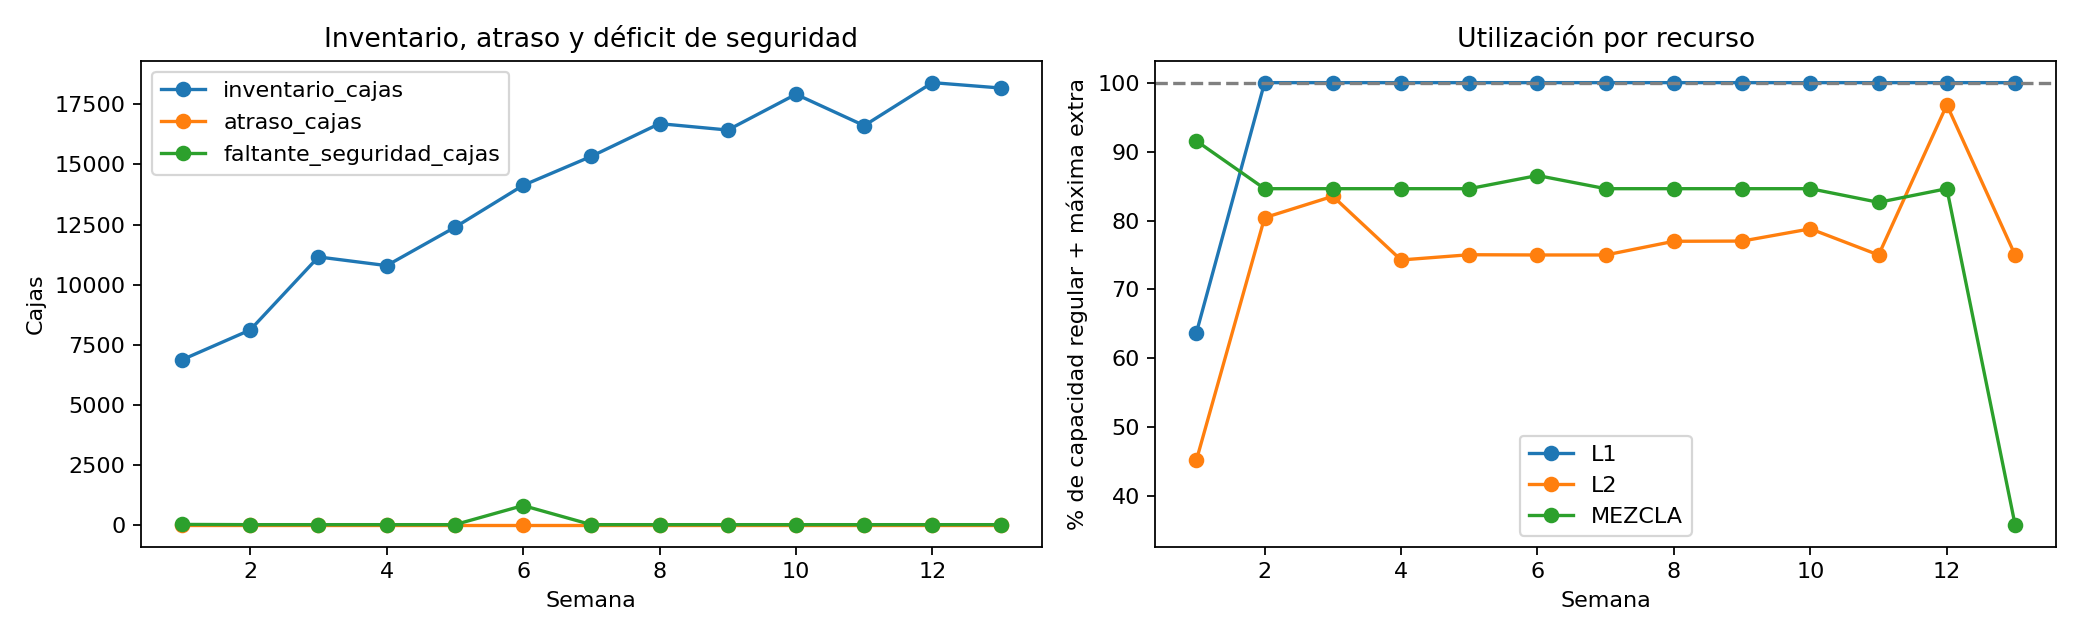

In [128]:
# Gráficos del plan nuevo, solamente cuando hay una solución factible.
if bool(base.factible):
    import matplotlib.pyplot as plt
    plan = pd.read_csv(ROOT / "resultados/base/plan_sku.csv")
    recursos = pd.read_csv(ROOT / "resultados/base/recursos.csv")
    agregado = plan.groupby("t")[["inventario_cajas", "atraso_cajas"]].sum()
    fig, ax = plt.subplots(1, 2, figsize=(15, 4))
    agregado.plot(ax=ax[0], marker="o")
    ax[0].set(title="Inventario y atraso por semana", xlabel="Semana", ylabel="Cajas")
    for nombre, grupo in recursos.groupby("recurso"):
        ax[1].plot(grupo.t, grupo.utilizacion_disponible * 100, marker="o", label=nombre)
    ax[1].axhline(100, color="grey", linestyle="--", linewidth=1)
    ax[1].set(title="Uso de capacidad disponible", xlabel="Semana", ylabel="% de capacidad regular + máxima extra")
    ax[1].legend()
    plt.tight_layout(); plt.show()


In [129]:
# Comprimir las nuevas salidas para descargarlas desde el panel Archivos de Colab.
import shutil
archivo_resultados = shutil.make_archive(str(ROOT / "resultados_nuevos"), "zip", ROOT / "resultados")
print("Descarga las nuevas salidas:", archivo_resultados)

from IPython.display import FileLink
display(FileLink(archivo_resultados))


Descarga las nuevas salidas: /workspace/scratch/f07d6c58523b/casework/final/ejecucion/Avance2_Equipo8/resultados_nuevos.zip


/workspace/scratch/f07d6c58523b/casework/final/ejecucion/Avance2_Equipo8/resultados_nuevos.zip